# KRAS mutation operator space — amino-acid-aware numerical validation

In [ ]:
!pip install biopython

In [ ]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from Bio.PDB import PDBParser, PDBList
from scipy.spatial.distance import pdist, squareform

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

PDB_ID = "4OBE"
CHAIN_ID = "A"
PDB_DIR = Path("pdb_files")
OUTPUT_DIR = Path("kras_operator_space_v5_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DISTANCE_CUTOFF = 7.0

# Amino-acid-aware mutation model.
# Larger physicochemical changes induce stronger weakening of the local interaction pattern.
ALPHA_MIN = 0.20
ALPHA_MAX = 0.85
SECOND_SHELL_FACTOR = 0.15

print("Configuration")
print("-------------")
print(f"PDB ID: {PDB_ID}")
print(f"Chain: {CHAIN_ID}")
print(f"Distance cutoff: {DISTANCE_CUTOFF} Å")
print(f"Mutation alpha range: [{ALPHA_MIN}, {ALPHA_MAX}]")
print(f"Second-shell factor: {SECOND_SHELL_FACTOR}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")


Configuration
-------------
PDB ID: 4OBE
Chain: A
Distance cutoff: 7.0 Å
Mutation alpha range: [0.2, 0.85]
Second-shell factor: 0.15
Output directory: C:\Users\Roberto\Downloads\kras_operator_space_v5_outputs


## 1. Utility functions

In [ ]:
def download_pdb(pdb_id: str, pdb_dir: Path = PDB_DIR) -> Path:
    """Download a PDB file using Bio.PDB and return the local path."""
    pdb_dir.mkdir(exist_ok=True)
    pdbl = PDBList()
    pdbl.retrieve_pdb_file(pdb_id, pdir=str(pdb_dir), file_format="pdb")
    return pdb_dir / f"pdb{pdb_id.lower()}.ent"


def build_rin_from_pdb(
    pdb_id: str,
    chain_id: str = "A",
    distance_cutoff: float = 7.0,
    pdb_dir: Path = PDB_DIR,
) -> tuple[nx.Graph, np.ndarray, list[int], Path]:
    """Build a C-alpha distance-based RIN from a PDB structure.

    Nodes correspond to residues with a C-alpha atom.
    Edges are added when the C-alpha distance is below the chosen cutoff.
    Edge weights are set equal to the C-alpha Euclidean distance.
    """
    pdb_file = download_pdb(pdb_id, pdb_dir)

    parser = PDBParser(QUIET=True)
    structure = parser.get_structure(pdb_id, str(pdb_file))

    model = structure[0]
    if chain_id not in model:
        available = [chain.id for chain in model]
        raise ValueError(f"Chain {chain_id!r} not found. Available chains: {available}")

    chain = model[chain_id]

    residues = []
    coords = []
    residue_numbers = []

    for residue in chain:
        if "CA" not in residue:
            continue

        hetflag, resseq, icode = residue.id
        if hetflag.strip():
            continue

        residues.append(residue)
        residue_numbers.append(int(resseq))
        coords.append(residue["CA"].coord)

    coords = np.asarray(coords, dtype=float)
    distances = squareform(pdist(coords))

    G = nx.Graph()

    for idx, resnum in enumerate(residue_numbers):
        G.add_node(
            idx,
            residue_number=resnum,
            residue_name=residues[idx].resname,
            coord=coords[idx],
        )

    n = len(residue_numbers)
    for i in range(n):
        for j in range(i + 1, n):
            distance = float(distances[i, j])
            if distance <= distance_cutoff:
                G.add_edge(i, j, weight=distance)

    return G, coords, residue_numbers, pdb_file


def weighted_adjacency(G: nx.Graph) -> np.ndarray:
    """Return the weighted adjacency matrix of a graph."""
    return nx.to_numpy_array(G, weight="weight", dtype=float)


def weighted_laplacian(G: nx.Graph) -> np.ndarray:
    """Return the weighted combinatorial graph Laplacian L = D - A."""
    A = weighted_adjacency(G)
    degrees = A.sum(axis=1)
    return np.diag(degrees) - A


def mutate_edge_weakening(
    G: nx.Graph,
    nodes_to_perturb: list[int],
    alpha: float = 0.5,
) -> nx.Graph:
    """Return a mutated graph obtained by weakening edges incident to selected nodes."""
    if not (0 < alpha <= 1):
        raise ValueError("alpha must satisfy 0 < alpha <= 1")

    H = G.copy()

    for v in nodes_to_perturb:
        if v not in H:
            continue

        for u in list(H.neighbors(v)):
            w = H[v][u].get("weight", 1.0)
            H[v][u]["weight"] = float(w) * alpha

    return H


# ---------------------------------------------------------------------
# Amino-acid-aware mutation perturbation model
# ---------------------------------------------------------------------

AA3_TO_1 = {
    "ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C",
    "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H", "ILE": "I",
    "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P",
    "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V",
}

# Simple physicochemical descriptors used only to differentiate mutations at the same site.
# Hydropathy values follow the Kyte--Doolittle scale; volumes are approximate residue volumes.
AA_HYDROPATHY = {
    "A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5,
    "Q": -3.5, "E": -3.5, "G": -0.4, "H": -3.2, "I": 4.5,
    "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8, "P": -1.6,
    "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2,
}

AA_VOLUME = {
    "A": 88.6, "R": 173.4, "N": 114.1, "D": 111.1, "C": 108.5,
    "Q": 143.8, "E": 138.4, "G": 60.1, "H": 153.2, "I": 166.7,
    "L": 166.7, "K": 168.6, "M": 162.9, "F": 189.9, "P": 112.7,
    "S": 89.0, "T": 116.1, "W": 227.8, "Y": 193.6, "V": 140.0,
}

AA_CHARGE = {
    "D": -1.0, "E": -1.0, "K": 1.0, "R": 1.0, "H": 0.1,
}


def aa_charge(aa: str) -> float:
    return AA_CHARGE.get(aa, 0.0)


def parse_mutation_name(name: str) -> dict:
    """Parse a mutation label such as G12D into WT residue, position and mutant residue."""
    import re
    match = re.match(r"^([A-Z])(\d+)([A-Z])$", name)
    if match is None:
        raise ValueError(f"Mutation name {name!r} does not follow the pattern G12D")
    wt, pos, mut = match.groups()
    return {"wt_aa": wt, "resnum": int(pos), "mut_aa": mut}


def amino_acid_severity(wt_aa: str, mut_aa: str) -> float:
    """Return a normalized physicochemical dissimilarity score in [0, approximately 1]."""
    if wt_aa not in AA_HYDROPATHY or mut_aa not in AA_HYDROPATHY:
        raise ValueError(f"Unknown amino acid substitution {wt_aa}->{mut_aa}")

    dh = abs(AA_HYDROPATHY[wt_aa] - AA_HYDROPATHY[mut_aa]) / 9.0
    dv = abs(AA_VOLUME[wt_aa] - AA_VOLUME[mut_aa]) / 170.0
    dc = abs(aa_charge(wt_aa) - aa_charge(mut_aa)) / 2.0

    return float(np.sqrt((dh ** 2 + dv ** 2 + dc ** 2) / 3.0))


def alpha_from_severity(
    severity: float,
    alpha_min: float = ALPHA_MIN,
    alpha_max: float = ALPHA_MAX,
) -> float:
    """Map physicochemical severity to an edge-weakening factor.

    Larger severity values produce smaller alpha values, corresponding to stronger local perturbations.
    """
    alpha = alpha_max - severity * (alpha_max - alpha_min)
    return float(np.clip(alpha, alpha_min, alpha_max))


def mutate_amino_acid_aware(
    G: nx.Graph,
    nodes_to_perturb: list[int],
    alpha: float,
    second_shell_factor: float = SECOND_SHELL_FACTOR,
) -> nx.Graph:
    """Return a mutated graph using an amino-acid-aware local weakening model.

    The main effect weakens edges incident to the mutated residue by alpha. A smaller
    second-shell correction weakens edges among first neighbors, introducing a mild local
    environmental perturbation while keeping the model simple and reproducible.
    """
    if not (0 < alpha <= 1):
        raise ValueError("alpha must satisfy 0 < alpha <= 1")

    H = G.copy()
    beta = 1.0 - second_shell_factor * (1.0 - alpha)
    beta = float(np.clip(beta, 0.0, 1.0))

    for v in nodes_to_perturb:
        if v not in H:
            continue

        neighbors = list(H.neighbors(v))

        for u in neighbors:
            w = H[v][u].get("weight", 1.0)
            H[v][u]["weight"] = float(w) * alpha

        # Mildly perturb interactions among neighbors of the mutated residue.
        for i, u in enumerate(neighbors):
            for w_node in neighbors[i + 1:]:
                if H.has_edge(u, w_node):
                    w = H[u][w_node].get("weight", 1.0)
                    H[u][w_node]["weight"] = float(w) * beta

    return H


def hilbert_schmidt_norm(A: np.ndarray) -> float:
    """Hilbert--Schmidt/Frobenius norm for real matrices."""
    return float(np.sqrt(np.trace(A.T @ A)))


def hilbert_schmidt_inner(A: np.ndarray, B: np.ndarray) -> float:
    """Hilbert--Schmidt inner product for real matrices."""
    return float(np.trace(A.T @ B))


def algebraic_connectivity(L: np.ndarray) -> float:
    """Second-smallest eigenvalue of the Laplacian."""
    evals = np.sort(np.linalg.eigvalsh(L))
    return float(evals[1]) if len(evals) > 1 else np.nan


def matrix_rank(A: np.ndarray, tol: float = 1e-10) -> int:
    """Numerical matrix rank."""
    return int(np.linalg.matrix_rank(A, tol=tol))


## 2. Build the wild-type KRAS RIN

In [ ]:
G_wt, coords, residue_numbers, pdb_file = build_rin_from_pdb(
    pdb_id=PDB_ID,
    chain_id=CHAIN_ID,
    distance_cutoff=DISTANCE_CUTOFF,
    pdb_dir=PDB_DIR,
)

A_wt = weighted_adjacency(G_wt)
L_wt = weighted_laplacian(G_wt)
lambda2_wt = algebraic_connectivity(L_wt)

print("PDB file:", pdb_file)
print("Number of residues:", G_wt.number_of_nodes())
print("Number of interactions:", G_wt.number_of_edges())
print("WT algebraic connectivity lambda_2:", lambda2_wt)
print("Adjacency shape:", A_wt.shape)
print("Laplacian shape:", L_wt.shape)


PDB file: pdb_files\pdb4obe.ent
Number of residues: 169
Number of interactions: 666
WT algebraic connectivity lambda_2: 1.3533143538022039
Adjacency shape: (169, 169)
Laplacian shape: (169, 169)


In [ ]:
residue_table = pd.DataFrame([
    {
        "node": node,
        "residue_number": data["residue_number"],
        "residue_name": data["residue_name"],
        "degree": G_wt.degree(node),
        "weighted_degree": sum(G_wt[node][nbr].get("weight", 1.0) for nbr in G_wt.neighbors(node)),
    }
    for node, data in G_wt.nodes(data=True)
])

residue_table.head(10)


,node,residue_number,residue_name,degree,weighted_degree
0,0,1,MET,5,27.352467
1,1,2,THR,6,32.109656
2,2,3,GLU,8,43.887577
3,3,4,TYR,8,44.342193
4,4,5,LYS,10,55.250089
5,5,6,LEU,12,67.100578
6,6,7,VAL,11,60.885688
7,7,8,VAL,10,54.669874
8,8,9,VAL,9,51.059023
9,9,10,GLY,7,37.307906


## 3. Define KRAS mutation sites

The list below can be expanded depending on the biological scope of the experiment. Several KRAS mutations share the same residue position, for example G12D, G12V and G12C. Under the present edge-weakening model, mutations affecting the same residue and using the same weakening parameter \(lpha\) will generate identical perturbation operators. Later experiments may assign mutation-specific parameters or use mutant-resolved structures if available.


In [ ]:
# A compact panel of clinically recurrent KRAS mutations.
# Multiple substitutions at the same site are intentionally included to test whether
# the amino-acid-aware perturbation model distinguishes mutations beyond residue position.
mutation_labels = [
    "G12D", "G12V", "G12C", "G12A", "G12S", "G12R",
    "G13D", "G13C", "G13V",
    "Q61H", "Q61L", "Q61R",
    "K117N", "A146T",
]

resnum_to_node = {
    data["residue_number"]: node
    for node, data in G_wt.nodes(data=True)
}

mutation_specs = []
for label in mutation_labels:
    parsed = parse_mutation_name(label)
    resnum = parsed["resnum"]
    node = resnum_to_node.get(resnum, None)

    if node is None:
        print(f"WARNING: mutation {label} maps to missing residue number {resnum}")
        continue

    pdb_resname = G_wt.nodes[node]["residue_name"]
    pdb_wt = AA3_TO_1.get(pdb_resname, None)

    if pdb_wt is not None and pdb_wt != parsed["wt_aa"]:
        print(
            f"WARNING: mutation {label} expects WT {parsed['wt_aa']} "
            f"but PDB residue {resnum} is {pdb_resname} ({pdb_wt})"
        )

    severity = amino_acid_severity(parsed["wt_aa"], parsed["mut_aa"])
    alpha = alpha_from_severity(severity)

    mutation_specs.append({
        "name": label,
        "resnums": [resnum],
        "site": resnum,
        "wt_aa": parsed["wt_aa"],
        "mut_aa": parsed["mut_aa"],
        "pdb_wt_aa": pdb_wt,
        "aa_severity": severity,
        "alpha": alpha,
    })

mutation_design_df = pd.DataFrame(mutation_specs)
mutation_design_df


,name,resnums,site,wt_aa,mut_aa,pdb_wt_aa,aa_severity,alpha
0,G12D,[12],12,G,D,G,0.391000,0.595850
1,G12V,[12],12,G,V,G,0.400888,0.589423
2,G12C,[12],12,G,C,G,0.248250,0.688637
3,G12A,[12],12,G,A,G,0.171132,0.738764
4,G12S,[12],12,G,S,G,0.101448,0.784059
5,G12R,[12],12,G,R,G,0.548244,0.493642
6,G13D,[13],13,G,D,G,0.391000,0.595850
7,G13C,[13],13,G,C,G,0.248250,0.688637
8,G13V,[13],13,G,V,G,0.400888,0.589423
9,Q61H,[61],61,Q,H,Q,0.047147,0.819354


## 4. Construct mutation perturbation operators

In [ ]:
rows = []
delta_laplacians = {}
mutated_laplacians = {}
mutated_graphs = {}

for mutation in mutation_specs:
    name = mutation["name"]
    resnums = mutation["resnums"]
    alpha_i = mutation["alpha"]

    nodes = [
        resnum_to_node[r]
        for r in resnums
        if r in resnum_to_node
    ]

    G_mut = mutate_amino_acid_aware(
        G_wt,
        nodes,
        alpha=alpha_i,
        second_shell_factor=SECOND_SHELL_FACTOR,
    )
    L_mut = weighted_laplacian(G_mut)
    delta_L = L_mut - L_wt

    mutated_graphs[name] = G_mut
    mutated_laplacians[name] = L_mut
    delta_laplacians[name] = delta_L

    lambda2_mut = algebraic_connectivity(L_mut)

    rows.append(
        {
            "mutation": name,
            "site": mutation["site"],
            "wt_aa": mutation["wt_aa"],
            "mut_aa": mutation["mut_aa"],
            "aa_severity": mutation["aa_severity"],
            "alpha": alpha_i,
            "residue_numbers": ",".join(map(str, resnums)),
            "nodes": ",".join(map(str, nodes)),
            "hs_norm": hilbert_schmidt_norm(delta_L),
            "rank_delta_L": matrix_rank(delta_L),
            "lambda2_wt": lambda2_wt,
            "lambda2_mut": lambda2_mut,
            "delta_lambda2": lambda2_mut - lambda2_wt,
            "distance_cutoff": DISTANCE_CUTOFF,
            "second_shell_factor": SECOND_SHELL_FACTOR,
        }
    )

operator_space_df = pd.DataFrame(rows)
operator_space_df


,mutation,site,wt_aa,mut_aa,aa_severity,alpha,residue_numbers,nodes,hs_norm,rank_delta_L,lambda2_wt,lambda2_mut,delta_lambda2,distance_cutoff,second_shell_factor
0,G12D,12,G,D,0.391000,0.595850,12,11,11.490845,4,1.353314,1.352965,-0.000350,7.0,0.15
1,G12V,12,G,V,0.400888,0.589423,12,11,11.673600,4,1.353314,1.352957,-0.000358,7.0,0.15
2,G12C,12,G,C,0.248250,0.688637,12,11,8.852710,4,1.353314,1.353066,-0.000248,7.0,0.15
3,G12A,12,G,A,0.171132,0.738764,12,11,7.427498,4,1.353314,1.353114,-0.000200,7.0,0.15
4,G12S,12,G,S,0.101448,0.784059,12,11,6.139679,4,1.353314,1.353154,-0.000160,7.0,0.15
5,G12R,12,G,R,0.548244,0.493642,12,11,14.396861,4,1.353314,1.352822,-0.000492,7.0,0.15
6,G13D,13,G,D,0.391000,0.595850,13,12,10.981945,4,1.353314,1.352094,-0.001220,7.0,0.15
7,G13C,13,G,C,0.248250,0.688637,13,12,8.460647,4,1.353314,1.352415,-0.000900,7.0,0.15
8,G13V,13,G,V,0.400888,0.589423,13,12,11.156607,4,1.353314,1.352071,-0.001243,7.0,0.15
9,Q61H,61,Q,H,0.047147,0.819354,61,60,5.290656,4,1.353314,1.352970,-0.000345,7.0,0.15


## 5. Pairwise Hilbert--Schmidt geometry of the mutation operator space

In [ ]:
mutation_names = [m["name"] for m in mutation_specs]
N_mut = len(mutation_names)

D_hs = np.zeros((N_mut, N_mut), dtype=float)
G_hs = np.zeros((N_mut, N_mut), dtype=float)

for i, name_i in enumerate(mutation_names):
    for j, name_j in enumerate(mutation_names):
        Delta_i = delta_laplacians[name_i]
        Delta_j = delta_laplacians[name_j]
        D_hs[i, j] = hilbert_schmidt_norm(Delta_i - Delta_j)
        G_hs[i, j] = hilbert_schmidt_inner(Delta_i, Delta_j)

D_hs_df = pd.DataFrame(D_hs, index=mutation_names, columns=mutation_names)
G_hs_df = pd.DataFrame(G_hs, index=mutation_names, columns=mutation_names)

print("Pairwise Hilbert--Schmidt distance matrix")
display(D_hs_df)
print("Hilbert--Schmidt Gram matrix")
display(G_hs_df)


Pairwise Hilbert--Schmidt distance matrix


,G12D,G12V,G12C,G12A,G12S,G12R,G13D,G13C,G13V,Q61H,Q61L,Q61R,K117N,A146T
G12D,0.000000,0.182755,2.638135,4.063347,5.351166,2.906015,11.560272,10.580201,11.645341,12.650319,17.675043,15.457528,24.872423,22.978285
G12V,0.182755,0.000000,2.820890,4.246102,5.533921,2.723260,11.661073,10.710552,11.744131,12.816551,17.794397,15.593864,24.957381,23.070219
G12C,2.638135,2.820890,0.000000,1.425212,2.713031,5.544150,10.358194,8.906198,10.473815,10.313172,16.085339,13.611250,23.769064,21.779176
G12A,4.063347,4.246102,1.425212,0.000000,1.287819,6.969363,9.942302,8.215161,10.074360,9.119143,15.347161,12.730411,23.275860,21.239816
G12S,5.351166,5.533921,2.713031,1.287819,0.000000,8.257181,9.732130,7.764783,9.877744,8.104734,14.766966,12.024613,22.897458,20.824450
G12R,2.906015,2.723260,5.544150,6.969363,8.257181,0.000000,13.370653,12.805649,13.426458,15.338208,19.688505,17.724707,26.341365,24.560774
G13D,11.560272,11.661073,10.358194,9.942302,9.732130,13.370653,0.000000,2.521299,0.174661,12.189921,17.348509,15.083062,24.641450,22.728070
G13C,10.580201,10.710552,8.906198,8.215161,7.764783,12.805649,2.521299,0.000000,2.695960,9.978657,15.872939,13.359573,23.625843,21.622779
G13V,11.645341,11.744131,10.473815,10.074360,9.877744,13.426458,0.174661,2.695960,0.000000,12.347506,17.459596,15.210704,24.719785,22.812977
Q61H,12.650319,12.816551,10.313172,9.119143,8.104734,15.338208,12.189921,9.978657,12.347506,0.000000,8.139445,5.048379,22.684553,20.590121


Hilbert--Schmidt Gram matrix


,G12D,G12V,G12C,G12A,G12S,G12R,G13D,G13C,G13V,Q61H,Q61L,Q61R,K117N,A146T
G12D,132.039525,134.139533,101.725125,85.348229,70.550103,165.432096,59.501383,45.840711,60.447717,0.000000,0.000000,0.000000,0.000000,0.000000
G12V,134.139533,136.272940,103.343001,86.705640,71.672160,168.063193,60.447717,46.569779,61.409101,0.000000,0.000000,0.000000,0.000000,0.000000
G12C,101.725125,103.343001,78.370481,65.753487,54.352801,127.451236,45.840711,35.316334,46.569779,0.000000,0.000000,0.000000,0.000000,0.000000
G12A,85.348229,86.705640,65.753487,55.167725,45.602454,106.932651,38.460739,29.630699,39.072434,0.000000,0.000000,0.000000,0.000000,0.000000
G12S,70.550103,71.672160,54.352801,45.602454,37.695660,88.392105,31.792213,24.493173,32.297849,0.000000,0.000000,0.000000,0.000000,0.000000
G12R,165.432096,168.063193,127.451236,106.932651,88.392105,207.269593,74.549182,57.433749,75.734842,0.000000,0.000000,0.000000,0.000000,0.000000
G13D,59.501383,60.447717,45.840711,38.460739,31.792213,74.549182,120.603126,92.914361,122.521245,0.000000,0.000000,0.000000,0.000000,0.000000
G13C,45.840711,46.569779,35.316334,29.630699,24.493173,57.433749,92.914361,71.582543,94.392107,0.000000,0.000000,0.000000,0.000000,0.000000
G13V,60.447717,61.409101,46.569779,39.072434,32.297849,75.734842,122.521245,94.392107,124.469871,0.000000,0.000000,0.000000,0.000000,0.000000
Q61H,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,27.991045,71.054054,54.700282,0.000000,0.000000


## 6. Save outputs for the next experiments

In [ ]:
operator_space_df.to_csv(OUTPUT_DIR / "kras_mutation_operator_space_summary.csv", index=False)
mutation_design_df.to_csv(OUTPUT_DIR / "kras_mutation_design_amino_acid_aware.csv", index=False)
D_hs_df.to_csv(OUTPUT_DIR / "kras_mutation_operator_distance_matrix.csv")
G_hs_df.to_csv(OUTPUT_DIR / "kras_mutation_operator_gram_matrix.csv")
residue_table.to_csv(OUTPUT_DIR / "kras_rin_residue_table.csv", index=False)

np.save(OUTPUT_DIR / "L_wt.npy", L_wt)
np.save(OUTPUT_DIR / "A_wt.npy", A_wt)
np.save(OUTPUT_DIR / "D_hs.npy", D_hs)
np.save(OUTPUT_DIR / "G_hs.npy", G_hs)

for name, delta_L in delta_laplacians.items():
    np.save(OUTPUT_DIR / f"delta_L_{name}.npy", delta_L)

print("Saved outputs in:", OUTPUT_DIR.resolve())
print("Files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)


Saved outputs in: C:\Users\Roberto\Downloads\kras_operator_space_v5_outputs
Files:
 - A_wt.npy
 - D_hs.npy
 - delta_L_A146T.npy
 - delta_L_G12A.npy
 - delta_L_G12C.npy
 - delta_L_G12D.npy
 - delta_L_G12R.npy
 - delta_L_G12S.npy
 - delta_L_G12V.npy
 - delta_L_G13C.npy
 - delta_L_G13D.npy
 - delta_L_G13V.npy
 - delta_L_K117N.npy
 - delta_L_Q61H.npy
 - delta_L_Q61L.npy
 - delta_L_Q61R.npy
 - G_hs.npy
 - kras_mutation_design_amino_acid_aware.csv
 - kras_mutation_operator_distance_matrix.csv
 - kras_mutation_operator_gram_matrix.csv
 - kras_mutation_operator_space_summary.csv
 - kras_rin_residue_table.csv
 - L_wt.npy


## 7. Basic figures

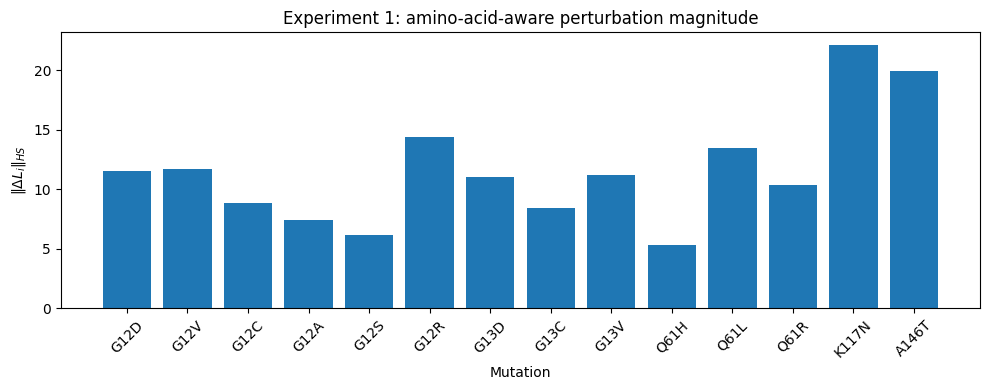

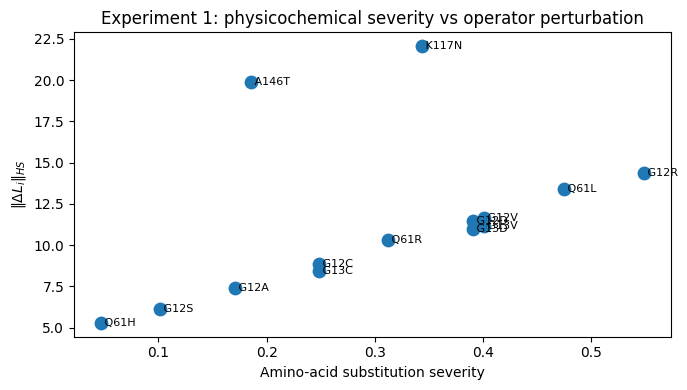

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(operator_space_df["mutation"], operator_space_df["hs_norm"])
ax1.set_ylabel(r"$\|\Delta L_i\|_{HS}$")
ax1.set_xlabel("Mutation")
ax1.set_title("Experiment 1: amino-acid-aware perturbation magnitude")
ax1.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "hs_norm_by_mutation_amino_acid_aware.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 4))
plt.scatter(operator_space_df["aa_severity"], operator_space_df["hs_norm"], s=80)
for _, row in operator_space_df.iterrows():
    plt.text(row["aa_severity"], row["hs_norm"], f" {row['mutation']}", va="center", fontsize=8)
plt.xlabel("Amino-acid substitution severity")
plt.ylabel(r"$\|\Delta L_i\|_{HS}$")
plt.title("Experiment 1: physicochemical severity vs operator perturbation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "severity_vs_hs_norm.png", dpi=300)
plt.show()


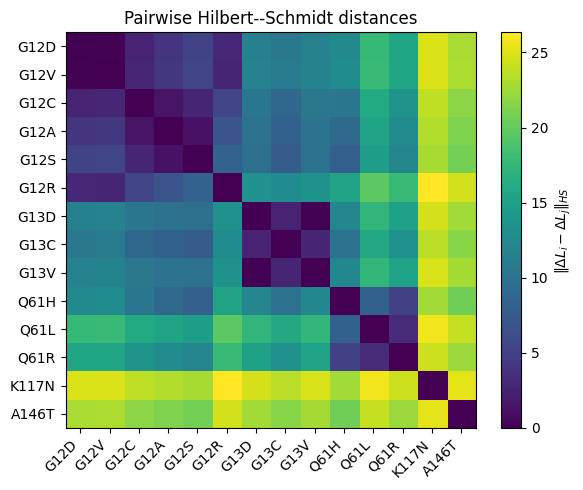

In [ ]:
plt.figure(figsize=(6, 5))
plt.imshow(D_hs, aspect="auto")
plt.xticks(range(N_mut), mutation_names, rotation=45, ha="right")
plt.yticks(range(N_mut), mutation_names)
plt.colorbar(label=r"$\|\Delta L_i - \Delta L_j\|_{HS}$")
plt.title("Pairwise Hilbert--Schmidt distances")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mutation_operator_distance_matrix.png", dpi=300)
plt.show()


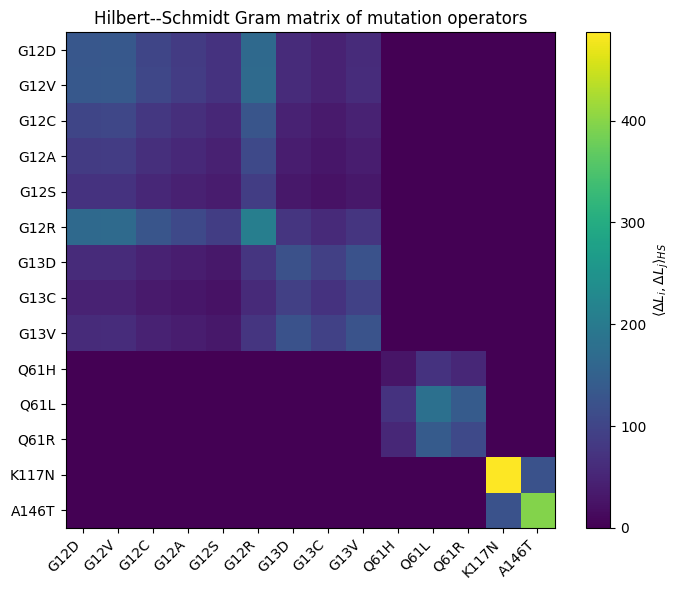

In [ ]:
plt.figure(figsize=(7, 6))
plt.imshow(G_hs, aspect="auto")
plt.xticks(range(N_mut), mutation_names, rotation=45, ha="right")
plt.yticks(range(N_mut), mutation_names)
plt.colorbar(label=r"$\langle \Delta L_i,\Delta L_j\rangle_{HS}$")
plt.title("Hilbert--Schmidt Gram matrix of mutation operators")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "mutation_operator_gram_matrix.png", dpi=300)
plt.show()


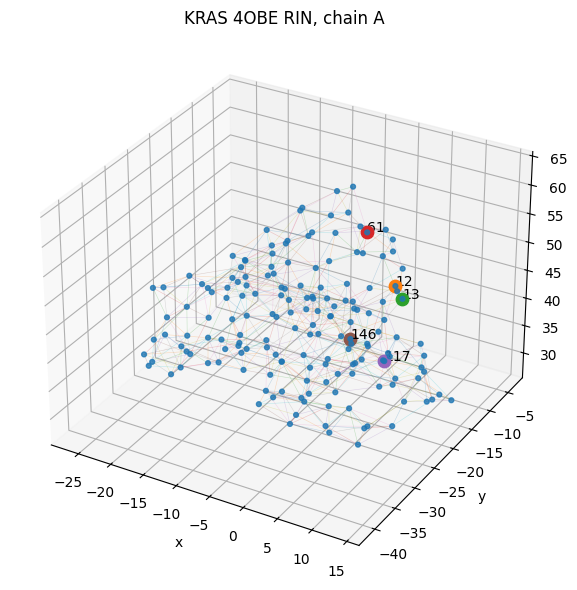

In [ ]:
# 3D visualization of the RIN using C-alpha coordinates.
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection="3d")

# Plot edges
for u, v in G_wt.edges():
    p = coords[u]
    q = coords[v]
    ax.plot([p[0], q[0]], [p[1], q[1]], [p[2], q[2]], linewidth=0.4, alpha=0.25)

# Plot nodes
ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], s=12, alpha=0.8)

# Highlight mutation residues
highlight_resnums = sorted({r for spec in mutation_specs for r in spec["resnums"]})
for resnum in highlight_resnums:
    if resnum in resnum_to_node:
        node = resnum_to_node[resnum]
        p = coords[node]
        ax.scatter([p[0]], [p[1]], [p[2]], s=80)
        ax.text(p[0], p[1], p[2], str(resnum), fontsize=10)

ax.set_title(f"KRAS {PDB_ID} RIN, chain {CHAIN_ID}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kras_rin_3d.png", dpi=300)
plt.show()



## 9. Experiment 2 — Validation of the variational representative selection functional

In [ ]:

import itertools
from dataclasses import dataclass

# ---------------------------------------------------------------------
# Experiment 2 configuration
# ---------------------------------------------------------------------
MU = 1.0
N_RANDOM_BASELINE = 1000

# Final paper strategy: use k=5 as the main showcase value, and k=4,6 as compact robustness checks.
K_MAIN = min(5, N_mut)
K_ROBUSTNESS = [k for k in [4, 5, 6] if 1 <= k <= N_mut]
if K_MAIN not in K_ROBUSTNESS:
    K_ROBUSTNESS.append(K_MAIN)
k_values = sorted(set(K_ROBUSTNESS))
if len(k_values) == 0:
    k_values = list(range(1, min(N_mut, 6) + 1))

# The theory uses V_i = Tr(Delta L_i^2), which equals ||Delta L_i||_HS^2
# for real symmetric perturbation operators.
V_vec = np.array([
    hilbert_schmidt_norm(delta_laplacians[name]) ** 2
    for name in mutation_names
], dtype=float)

# The theory uses D_ij = d(L_i,L_j)^2.
D_sq = D_hs ** 2


def mask_from_indices(indices: tuple[int, ...], n: int) -> np.ndarray:
    mask = np.zeros(n, dtype=int)
    mask[list(indices)] = 1
    return mask


def names_from_mask(mask: np.ndarray) -> list[str]:
    return [mutation_names[i] for i, value in enumerate(mask) if value == 1]


def variational_components(mask: np.ndarray, V: np.ndarray, D2: np.ndarray, mu: float = 1.0) -> dict:
    """Compute V(R), D(R), and J(R) for a binary selection mask."""
    selected = np.where(mask == 1)[0]

    V_R = float(np.sum(V[selected]))

    D_R = 0.0
    for i_pos, i in enumerate(selected):
        for j in selected[i_pos + 1:]:
            D_R += float(D2[i, j])

    J_R = -V_R - mu * D_R

    return {
        "V": V_R,
        "D": D_R,
        "J": J_R,
    }


def exact_variational_selection(k: int, V: np.ndarray, D2: np.ndarray, mu: float = 1.0) -> dict:
    """Brute-force exact minimization of the variational functional for fixed k."""
    best = None

    for indices in itertools.combinations(range(len(V)), k):
        mask = mask_from_indices(indices, len(V))
        values = variational_components(mask, V, D2, mu)

        if best is None or values["J"] < best["J"]:
            best = {
                "mask": mask,
                "indices": indices,
                "selected": names_from_mask(mask),
                **values,
            }

    return best


def top_energy_baseline(k: int, V: np.ndarray, D2: np.ndarray, mu: float = 1.0) -> dict:
    """Baseline: select the k largest individual perturbation energies."""
    indices = tuple(np.argsort(-V)[:k])
    mask = mask_from_indices(indices, len(V))
    values = variational_components(mask, V, D2, mu)

    return {
        "mask": mask,
        "indices": indices,
        "selected": names_from_mask(mask),
        **values,
    }


def random_baseline(k: int, V: np.ndarray, D2: np.ndarray, mu: float = 1.0, n_samples: int = 1000) -> dict:
    """Random baseline averaged over uniformly sampled subsets of cardinality k."""
    rng = np.random.default_rng(RANDOM_SEED + k)
    all_values = []

    for _ in range(n_samples):
        indices = tuple(rng.choice(len(V), size=k, replace=False))
        mask = mask_from_indices(indices, len(V))
        all_values.append(variational_components(mask, V, D2, mu))

    return {
        "V_mean": float(np.mean([v["V"] for v in all_values])),
        "V_std": float(np.std([v["V"] for v in all_values])),
        "D_mean": float(np.mean([v["D"] for v in all_values])),
        "D_std": float(np.std([v["D"] for v in all_values])),
        "J_mean": float(np.mean([v["J"] for v in all_values])),
        "J_std": float(np.std([v["J"] for v in all_values])),
    }


experiment_2_rows = []

for k in k_values:
    exact = exact_variational_selection(k, V_vec, D_sq, MU)
    top = top_energy_baseline(k, V_vec, D_sq, MU)
    rnd = random_baseline(k, V_vec, D_sq, MU, N_RANDOM_BASELINE)

    experiment_2_rows.append({
        "k": k,
        "method": "variational_exact",
        "selected": ", ".join(exact["selected"]),
        "V": exact["V"],
        "D": exact["D"],
        "J": exact["J"],
    })

    experiment_2_rows.append({
        "k": k,
        "method": "top_perturbation_energy",
        "selected": ", ".join(top["selected"]),
        "V": top["V"],
        "D": top["D"],
        "J": top["J"],
    })

    experiment_2_rows.append({
        "k": k,
        "method": "random_mean",
        "selected": "random subsets",
        "V": rnd["V_mean"],
        "D": rnd["D_mean"],
        "J": rnd["J_mean"],
        "V_std": rnd["V_std"],
        "D_std": rnd["D_std"],
        "J_std": rnd["J_std"],
    })

experiment_2_df = pd.DataFrame(experiment_2_rows)
experiment_2_df


,k,method,selected,V,D,J,V_std,D_std,J_std
0,4,variational_exact,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
1,4,top_perturbation_energy,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
2,4,random_mean,random subsets,617.829325,1446.336043,-2064.165368,228.385208,800.226776,1019.202942
3,5,variational_exact,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,NaN,NaN,NaN
4,5,top_perturbation_energy,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,NaN,NaN,NaN
5,5,random_mean,random subsets,782.681122,2464.140017,-3246.821139,244.176041,1110.472630,1346.020354
6,6,variational_exact,"G12R, G13V, Q61L, Q61R, K117N, A146T",1501.562706,6831.761863,-8333.324568,NaN,NaN,NaN
7,6,top_perturbation_energy,"G12D, G12V, G12R, Q61L, K117N, A146T",1538.509652,6510.405222,-8048.914874,NaN,NaN,NaN
8,6,random_mean,random subsets,935.434201,3681.943778,-4617.377978,246.044177,1402.282311,1639.518803


In [ ]:

# Save Experiment 2 results
experiment_2_df.to_csv(OUTPUT_DIR / "experiment_2_variational_selection_results.csv", index=False)

print("Experiment 2 saved:")
print(" -", OUTPUT_DIR / "experiment_2_variational_selection_results.csv")


Experiment 2 saved:
 - kras_operator_space_v5_outputs\experiment_2_variational_selection_results.csv


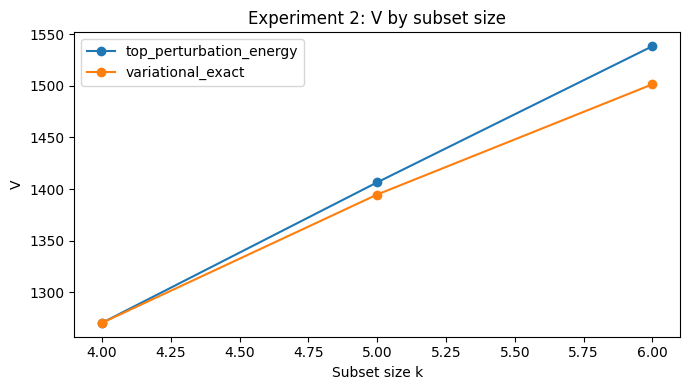

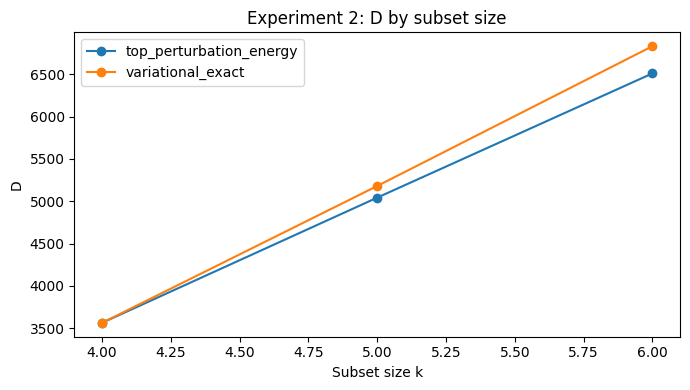

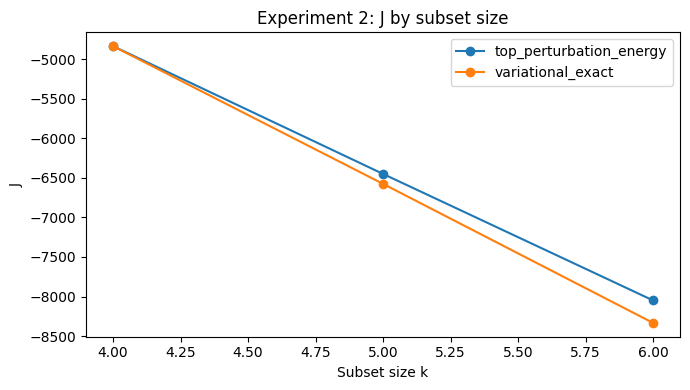

Saved Experiment 2 comparison figures.


In [ ]:

# Plot comparison of V, D, and J across k values for deterministic methods.
det_df = experiment_2_df[experiment_2_df["method"].isin(["variational_exact", "top_perturbation_energy"])].copy()

for metric in ["V", "D", "J"]:
    plt.figure(figsize=(7, 4))

    for method, group in det_df.groupby("method"):
        group = group.sort_values("k")
        plt.plot(group["k"], group[metric], marker="o", label=method)

    plt.xlabel("Subset size k")
    plt.ylabel(metric)
    plt.title(f"Experiment 2: {metric} by subset size")
    plt.legend()
    plt.tight_layout()

    out_path = OUTPUT_DIR / f"experiment_2_{metric}_comparison.png"
    plt.savefig(out_path, dpi=200)
    plt.show()

print("Saved Experiment 2 comparison figures.")


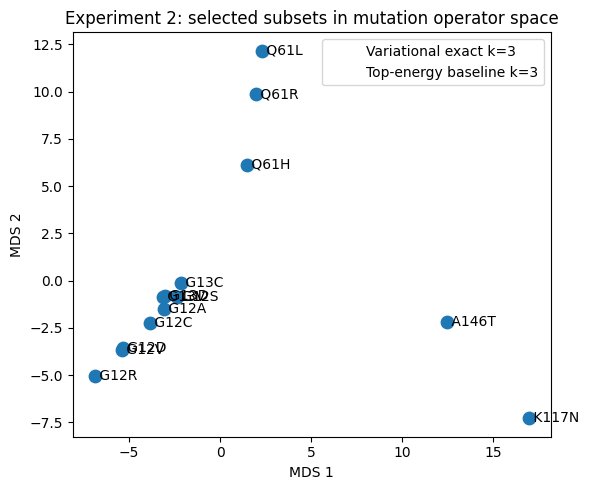

Saved: kras_operator_space_v5_outputs\experiment_2_mds_selected_subsets.png


In [ ]:

# Classical MDS visualization of the mutation operator space.
def classical_mds(distance_matrix: np.ndarray, n_components: int = 2) -> np.ndarray:
    """Classical multidimensional scaling from a distance matrix."""
    D2 = distance_matrix ** 2
    n = D2.shape[0]
    J_center = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J_center @ D2 @ J_center

    evals, evecs = np.linalg.eigh(B)
    idx = np.argsort(evals)[::-1]
    evals = evals[idx]
    evecs = evecs[:, idx]

    positive = np.maximum(evals[:n_components], 0)
    coords_mds = evecs[:, :n_components] * np.sqrt(positive)

    return coords_mds


mds_coords = classical_mds(D_hs, n_components=2)

# Choose a representative k for visualization.
k_plot = min(3, N_mut)
exact_plot = exact_variational_selection(k_plot, V_vec, D_sq, MU)
top_plot = top_energy_baseline(k_plot, V_vec, D_sq, MU)

plt.figure(figsize=(6, 5))
plt.scatter(mds_coords[:, 0], mds_coords[:, 1], s=80)

for i, name in enumerate(mutation_names):
    plt.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", va="center")

exact_indices = list(exact_plot["indices"])
top_indices = list(top_plot["indices"])

plt.scatter(
    mds_coords[exact_indices, 0],
    mds_coords[exact_indices, 1],
    s=220,
    facecolors="none",
    linewidths=2,
    label=f"Variational exact k={k_plot}",
)

plt.scatter(
    mds_coords[top_indices, 0],
    mds_coords[top_indices, 1],
    s=120,
    marker="s",
    facecolors="none",
    linewidths=2,
    label=f"Top-energy baseline k={k_plot}",
)

plt.xlabel("MDS 1")
plt.ylabel("MDS 2")
plt.title("Experiment 2: selected subsets in mutation operator space")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_2_mds_selected_subsets.png"
plt.savefig(out_path, dpi=200)
plt.show()

print("Saved:", out_path)



## 10. Experiment 3 — Validation of the exact QUBO and Ising reformulations


In [ ]:

# ---------------------------------------------------------------------
# Experiment 3: Exact reformulation checks
# ---------------------------------------------------------------------

def build_qubo_matrix(
    V: np.ndarray,
    D2: np.ndarray,
    mu: float,
    lam: float,
    k: int,
) -> np.ndarray:
    """Build the symmetric QUBO matrix A under Q(x)=x^T A x + lambda k^2."""
    n = len(V)
    one = np.ones((n, 1))
    I = np.eye(n)

    return (
        -np.diag(V)
        - (mu / 2.0) * D2
        + lam * (one @ one.T)
        - 2.0 * lam * k * I
    )


def penalty_bound_B(V: np.ndarray, D2: np.ndarray, mu: float) -> float:
    """Conservative exact penalty bound B."""
    upper_tri_sum = float(np.sum(np.triu(D2, k=1)))
    return float(np.sum(V) + mu * upper_tri_sum)


def qubo_energy(mask: np.ndarray, A: np.ndarray, lam: float, k: int) -> float:
    """Penalized QUBO energy."""
    x = mask.astype(float)
    return float(x.T @ A @ x + lam * (k ** 2))


def binary_to_spin(mask: np.ndarray) -> np.ndarray:
    """Map x in {0,1}^N to z in {-1,+1}^N using x=(1-z)/2."""
    return 1 - 2 * mask.astype(int)


def spin_to_binary(z: np.ndarray) -> np.ndarray:
    """Map z in {-1,+1}^N to x in {0,1}^N using x=(1-z)/2."""
    return ((1 - z) // 2).astype(int)


def ising_coefficients_from_A(A: np.ndarray, lam: float, k: int) -> dict:
    """Compute E0, h, and J from the symmetric QUBO matrix A."""
    n = A.shape[0]
    one = np.ones(n)

    E0 = float(lam * (k ** 2) + 0.25 * (one.T @ A @ one + np.trace(A)))
    h = -0.5 * np.sum(A, axis=1)

    J = np.zeros_like(A, dtype=float)
    for i in range(n):
        for j in range(i + 1, n):
            J[i, j] = 0.5 * A[i, j]
            J[j, i] = J[i, j]

    return {"E0": E0, "h": h, "J": J}


def ising_energy(z: np.ndarray, coeffs: dict) -> float:
    """Classical Ising energy E0 + sum_i h_i z_i + sum_{i<j} J_ij z_i z_j."""
    E = coeffs["E0"] + float(np.dot(coeffs["h"], z))

    J = coeffs["J"]
    n = len(z)
    for i in range(n):
        for j in range(i + 1, n):
            E += float(J[i, j] * z[i] * z[j])

    return float(E)


def all_binary_masks(n: int):
    """Generate all binary masks of length n."""
    for bits in itertools.product([0, 1], repeat=n):
        yield np.array(bits, dtype=int)


experiment_3_rows = []
B_bound = penalty_bound_B(V_vec, D_sq, MU)

for k in k_values:
    lam = 1.05 * B_bound if B_bound > 0 else 1.0

    A_qubo = build_qubo_matrix(V_vec, D_sq, MU, lam, k)
    coeffs = ising_coefficients_from_A(A_qubo, lam, k)

    # Direct constrained variational optimum
    exact_var = exact_variational_selection(k, V_vec, D_sq, MU)

    # Unconstrained QUBO optimum over all bitstrings
    best_qubo = None
    best_ising = None
    max_energy_mismatch = 0.0

    for mask in all_binary_masks(N_mut):
        z = binary_to_spin(mask)

        q_energy = qubo_energy(mask, A_qubo, lam, k)
        i_energy = ising_energy(z, coeffs)
        max_energy_mismatch = max(max_energy_mismatch, abs(q_energy - i_energy))

        if best_qubo is None or q_energy < best_qubo["energy"]:
            best_qubo = {
                "mask": mask,
                "energy": q_energy,
                "selected": names_from_mask(mask),
                "cardinality": int(mask.sum()),
            }

        if best_ising is None or i_energy < best_ising["energy"]:
            best_ising = {
                "z": z,
                "mask": mask,
                "energy": i_energy,
                "selected": names_from_mask(mask),
                "cardinality": int(mask.sum()),
            }

    var_mask = exact_var["mask"]
    var_qubo_energy = qubo_energy(var_mask, A_qubo, lam, k)
    var_ising_energy = ising_energy(binary_to_spin(var_mask), coeffs)

    experiment_3_rows.append({
        "k": k,
        "lambda": lam,
        "B_bound": B_bound,
        "variational_selected": ", ".join(exact_var["selected"]),
        "qubo_selected": ", ".join(best_qubo["selected"]),
        "ising_selected": ", ".join(best_ising["selected"]),
        "variational_J": exact_var["J"],
        "qubo_min_energy": best_qubo["energy"],
        "ising_min_energy": best_ising["energy"],
        "qubo_energy_at_variational_solution": var_qubo_energy,
        "ising_energy_at_variational_solution": var_ising_energy,
        "qubo_cardinality": best_qubo["cardinality"],
        "ising_cardinality": best_ising["cardinality"],
        "same_variational_qubo_subset": set(exact_var["selected"]) == set(best_qubo["selected"]),
        "same_variational_ising_subset": set(exact_var["selected"]) == set(best_ising["selected"]),
        "max_abs_qubo_ising_energy_mismatch": max_energy_mismatch,
    })

experiment_3_df = pd.DataFrame(experiment_3_rows)
experiment_3_df


,k,lambda,B_bound,variational_selected,qubo_selected,ising_selected,variational_J,qubo_min_energy,ising_min_energy,qubo_energy_at_variational_solution,ising_energy_at_variational_solution,qubo_cardinality,ising_cardinality,same_variational_qubo_subset,same_variational_ising_subset,max_abs_qubo_ising_energy_mismatch
0,4,25389.536101,24180.510572,"G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T",-4833.915354,-4833.915354,-4833.915354,-4833.915354,-4833.915354,4,4,True,True,1.862645e-09
1,5,25389.536101,24180.510572,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",-6574.992212,-6574.992212,-6574.992212,-6574.992212,-6574.992212,5,5,True,True,1.396984e-09
2,6,25389.536101,24180.510572,"G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T",-8333.324568,-8333.324568,-8333.324568,-8333.324568,-8333.324568,6,6,True,True,6.984919e-10


In [ ]:

# Save Experiment 3 outputs
experiment_3_df.to_csv(OUTPUT_DIR / "experiment_3_exact_reformulation_validation.csv", index=False)

# Save one QUBO matrix and Ising coefficients per k.
for k in k_values:
    lam = 1.05 * B_bound if B_bound > 0 else 1.0
    A_qubo = build_qubo_matrix(V_vec, D_sq, MU, lam, k)
    coeffs = ising_coefficients_from_A(A_qubo, lam, k)

    np.save(OUTPUT_DIR / f"experiment_3_qubo_A_k{k}.npy", A_qubo)
    np.save(OUTPUT_DIR / f"experiment_3_ising_h_k{k}.npy", coeffs["h"])
    np.save(OUTPUT_DIR / f"experiment_3_ising_J_k{k}.npy", coeffs["J"])

print("Experiment 3 saved:")
print(" -", OUTPUT_DIR / "experiment_3_exact_reformulation_validation.csv")


Experiment 3 saved:
 - kras_operator_space_v5_outputs\experiment_3_exact_reformulation_validation.csv


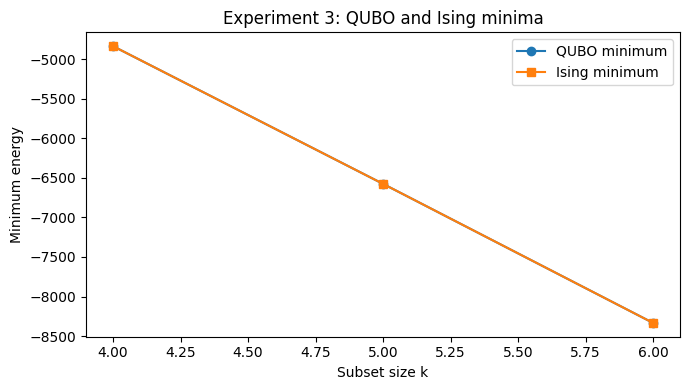

Saved: kras_operator_space_v5_outputs\experiment_3_qubo_ising_minima.png


,k,variational_selected,qubo_selected,ising_selected,qubo_cardinality,ising_cardinality,same_variational_qubo_subset,same_variational_ising_subset,max_abs_qubo_ising_energy_mismatch
0,4,"G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T","G12R, Q61L, K117N, A146T",4,4,True,True,1.862645e-09
1,5,"G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T","G12R, G13V, Q61L, K117N, A146T",5,5,True,True,1.396984e-09
2,6,"G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T","G12R, G13V, Q61L, Q61R, K117N, A146T",6,6,True,True,6.984919e-10


In [ ]:

# Plot exact reformulation validation.
plt.figure(figsize=(7, 4))
plt.plot(experiment_3_df["k"], experiment_3_df["qubo_min_energy"], marker="o", label="QUBO minimum")
plt.plot(experiment_3_df["k"], experiment_3_df["ising_min_energy"], marker="s", label="Ising minimum")
plt.xlabel("Subset size k")
plt.ylabel("Minimum energy")
plt.title("Experiment 3: QUBO and Ising minima")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_3_qubo_ising_minima.png"
plt.savefig(out_path, dpi=200)
plt.show()

print("Saved:", out_path)

display(experiment_3_df[[
    "k",
    "variational_selected",
    "qubo_selected",
    "ising_selected",
    "qubo_cardinality",
    "ising_cardinality",
    "same_variational_qubo_subset",
    "same_variational_ising_subset",
    "max_abs_qubo_ising_energy_mismatch",
]])



## 11. Experiment 4 — Quantum and hybrid optimization of the cost Hamiltonian

In [ ]:

from scipy.optimize import minimize
import multiprocessing

try:
    from joblib import Parallel, delayed
    JOBLIB_AVAILABLE = True
except ImportError:
    JOBLIB_AVAILABLE = False
    Parallel = None
    delayed = None

# ---------------------------------------------------------------------
# Experiment 4 configuration
# ---------------------------------------------------------------------
K_QOPT = K_MAIN                 # main representative target subset size for optimization experiments
LAMBDA_QOPT = 1.05 * B_bound if B_bound > 0 else 1.0
QAOA_P_VALUES = [1, 2]
QAOA_RESTARTS = 8
QAOA_SHOTS = 3000
QAOA_MAXITER = 500
SA_RESTARTS = 100
SA_STEPS = 1500

# Parallel execution. Keep this moderate because NumPy/BLAS may already use several threads.
N_JOBS = multiprocessing.cpu_count() if JOBLIB_AVAILABLE else 1
PARALLEL_BACKEND = "loky"

A_qopt = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_QOPT, K_QOPT)
coeffs_qopt = ising_coefficients_from_A(A_qopt, LAMBDA_QOPT, K_QOPT)

all_masks_list = list(all_binary_masks(N_mut))
all_masks_array = np.asarray(all_masks_list, dtype=int)
all_energies = np.array([
    qubo_energy(mask, A_qopt, LAMBDA_QOPT, K_QOPT)
    for mask in all_masks_list
], dtype=float)

exact_energy = float(np.min(all_energies))
optimal_indices = np.where(np.isclose(all_energies, exact_energy, atol=1e-9))[0]
optimal_masks = [all_masks_list[i] for i in optimal_indices]

print("Experiment 4 target")
print("-------------------")
print(f"k = {K_QOPT}")
print(f"lambda = {LAMBDA_QOPT:.6g}")
print(f"exact minimum energy = {exact_energy:.6g}")
print(f"number of degenerate optima = {len(optimal_masks)}")
print(f"parallel backend available = {JOBLIB_AVAILABLE}")
print(f"N_JOBS = {N_JOBS}")
print("one exact optimum:", names_from_mask(optimal_masks[0]))


Experiment 4 target
-------------------
k = 5
lambda = 25389.5
exact minimum energy = -6574.99
number of degenerate optima = 1
parallel backend available = True
N_JOBS = 20
one exact optimum: ['G12R', 'G13V', 'Q61L', 'K117N', 'A146T']


In [ ]:

# ---------------------------------------------------------------------
# QAOA statevector simulator for diagonal Ising/QUBO cost Hamiltonians
# ---------------------------------------------------------------------

def apply_mixer_x_layer(psi: np.ndarray, beta: float, masks: np.ndarray) -> np.ndarray:
    """Apply exp(-i beta sum_i X_i) to a statevector indexed by binary masks."""
    n_states, n_qubits = masks.shape
    state = psi.copy()

    # Build index lookup once per call. For the small systems in this notebook this is sufficient.
    index = {tuple(mask): idx for idx, mask in enumerate(masks)}

    c = np.cos(beta)
    s = np.sin(beta)

    for q in range(n_qubits):
        new_state = state.copy()
        visited = np.zeros(n_states, dtype=bool)

        for idx, mask in enumerate(masks):
            if visited[idx]:
                continue

            flipped = mask.copy()
            flipped[q] = 1 - flipped[q]
            jdx = index[tuple(flipped)]

            if idx == jdx:
                continue

            a0 = state[idx]
            a1 = state[jdx]

            new_state[idx] = c * a0 - 1j * s * a1
            new_state[jdx] = -1j * s * a0 + c * a1

            visited[idx] = True
            visited[jdx] = True

        state = new_state

    return state


def qaoa_state(params: np.ndarray, p: int, energies: np.ndarray, masks: np.ndarray) -> np.ndarray:
    """Return the QAOA state for p layers under the convention U_M(beta) U_C(gamma)."""
    n_states = len(energies)
    betas = params[:p]
    gammas = params[p:]

    psi = np.ones(n_states, dtype=complex) / np.sqrt(n_states)

    for beta, gamma in zip(betas, gammas):
        psi = np.exp(-1j * gamma * energies) * psi
        psi = apply_mixer_x_layer(psi, beta, masks)

    return psi


def qaoa_expectation(params: np.ndarray, p: int, energies: np.ndarray, masks: np.ndarray) -> float:
    psi = qaoa_state(params, p, energies, masks)
    probs = np.abs(psi) ** 2
    return float(np.dot(probs, energies))


def _single_qaoa_restart(
    p: int,
    energies: np.ndarray,
    masks: np.ndarray,
    restart_seed: int,
    maxiter: int,
) -> dict:
    """Run one QAOA restart. This helper is parallel-safe."""
    rng = np.random.default_rng(restart_seed)
    bounds = [(0.0, np.pi)] * p + [(0.0, 2.0 * np.pi)] * p

    x0 = np.array([
        *rng.uniform(0.0, np.pi, size=p),
        *rng.uniform(0.0, 2.0 * np.pi, size=p),
    ])

    result = minimize(
        qaoa_expectation,
        x0=x0,
        args=(p, energies, masks),
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": maxiter},
    )

    return {
        "p": p,
        "params": result.x,
        "expectation": float(result.fun),
        "success": bool(result.success),
        "message": str(result.message),
        "nfev": int(result.nfev),
        "restart_seed": int(restart_seed),
    }


def optimize_qaoa(
    p: int,
    energies: np.ndarray,
    masks: np.ndarray,
    n_restarts: int = 20,
    seed: int = 42,
    n_jobs: int = 1,
    maxiter: int = 500,
) -> dict:
    """Multi-start variational optimization of QAOA parameters.

    Restarts are independent and can be parallelized with joblib.
    """
    restart_seeds = [seed + 1000 * p + restart for restart in range(n_restarts)]

    if JOBLIB_AVAILABLE and n_jobs != 1 and n_restarts > 1:
        restart_results = Parallel(n_jobs=n_jobs, backend=PARALLEL_BACKEND, verbose=5)(
            delayed(_single_qaoa_restart)(p, energies, masks, restart_seed, maxiter)
            for restart_seed in restart_seeds
        )
    else:
        restart_results = [
            _single_qaoa_restart(p, energies, masks, restart_seed, maxiter)
            for restart_seed in restart_seeds
        ]

    best = min(restart_results, key=lambda row: row["expectation"])
    best["restart_results"] = restart_results
    best["total_nfev"] = int(sum(row["nfev"] for row in restart_results))

    psi = qaoa_state(best["params"], p, energies, masks)
    probs = np.abs(psi) ** 2
    best["state"] = psi
    best["probabilities"] = probs
    best["feasible_probability"] = float(np.sum(probs[np.sum(masks, axis=1) == K_QOPT]))
    best["optimal_probability"] = float(np.sum(probs[optimal_indices]))

    # Finite-shot sampling to mimic experimental readout.
    rng = np.random.default_rng(seed + 999 + p)
    sampled_indices = rng.choice(len(energies), size=QAOA_SHOTS, replace=True, p=probs)
    sampled_energies = energies[sampled_indices]
    best_sample_idx = sampled_indices[int(np.argmin(sampled_energies))]

    best["sampled_best_index"] = int(best_sample_idx)
    best["sampled_best_mask"] = masks[best_sample_idx].astype(int)
    best["sampled_best_energy"] = float(energies[best_sample_idx])
    best["sampled_best_selected"] = names_from_mask(best["sampled_best_mask"])
    best["sampled_best_cardinality"] = int(np.sum(best["sampled_best_mask"]))

    return best


In [ ]:
# ---------------------------------------------------------------------
# Simulated annealing baseline on the same penalized QUBO energy
# ---------------------------------------------------------------------

def _single_sa_restart(
    A: np.ndarray,
    lam: float,
    k: int,
    n_steps: int,
    t_initial: float,
    t_final: float,
    seed: int,
) -> dict:
    """Run one bit-flip simulated annealing restart. This helper is parallel-safe."""
    rng = np.random.default_rng(seed)
    n = A.shape[0]

    x = rng.integers(0, 2, size=n, dtype=int)
    e = qubo_energy(x, A, lam, k)
    best_local_x = x.copy()
    best_local_e = e

    for step in range(n_steps):
        frac = step / max(n_steps - 1, 1)
        temp = t_initial * (t_final / t_initial) ** frac

        q = int(rng.integers(0, n))
        x_new = x.copy()
        x_new[q] = 1 - x_new[q]
        e_new = qubo_energy(x_new, A, lam, k)
        delta = e_new - e

        if delta <= 0 or rng.random() < np.exp(-delta / max(temp, 1e-12)):
            x = x_new
            e = e_new

            if e < best_local_e:
                best_local_x = x.copy()
                best_local_e = e

    return {
        "mask": best_local_x,
        "energy": float(best_local_e),
        "selected": names_from_mask(best_local_x),
        "cardinality": int(np.sum(best_local_x)),
    }


def simulated_annealing_qubo(
    A: np.ndarray,
    lam: float,
    k: int,
    n_steps: int = 2000,
    n_restarts: int = 100,
    t_initial: float | None = None,
    t_final: float = 1e-3,
    seed: int = 42,
    n_jobs: int = 1,
) -> dict:
    """Simple bit-flip simulated annealing for the penalized QUBO energy.

    Restarts are independent and can be parallelized with joblib.
    """
    n = A.shape[0]

    if t_initial is None:
        # Scale temperature to the energy range for numerical stability.
        energies = np.array([qubo_energy(mask, A, lam, k) for mask in all_binary_masks(n)])
        t_initial = max(float(np.std(energies)), 1.0)

    restart_seeds = [seed + 20000 + restart for restart in range(n_restarts)]

    if JOBLIB_AVAILABLE and n_jobs != 1 and n_restarts > 1:
        restart_results = Parallel(n_jobs=n_jobs, backend=PARALLEL_BACKEND, verbose=5)(
            delayed(_single_sa_restart)(A, lam, k, n_steps, t_initial, t_final, restart_seed)
            for restart_seed in restart_seeds
        )
    else:
        restart_results = [
            _single_sa_restart(A, lam, k, n_steps, t_initial, t_final, restart_seed)
            for restart_seed in restart_seeds
        ]

    best_global = min(restart_results, key=lambda row: row["energy"])
    best_global["restart_results"] = restart_results

    return best_global


In [ ]:
# ---------------------------------------------------------------------
# Run Experiment 4
# ---------------------------------------------------------------------
experiment_4_rows = []

# Exact reference optimum.
exact_mask = optimal_masks[0]
experiment_4_rows.append({
    "method": "exact_enumeration",
    "p": np.nan,
    "energy": exact_energy,
    "expectation": exact_energy,
    "optimality_gap": 0.0,
    "relative_gap": 0.0,
    "optimal_probability": 1.0,
    "feasible_probability": 1.0,
    "cardinality": int(np.sum(exact_mask)),
    "selected": ", ".join(names_from_mask(exact_mask)),
})

# QAOA approximations. Independent restarts are parallelized inside optimize_qaoa.
qaoa_results = {}
for p in QAOA_P_VALUES:
    result = optimize_qaoa(
        p=p,
        energies=all_energies,
        masks=all_masks_array,
        n_restarts=QAOA_RESTARTS,
        seed=RANDOM_SEED,
        n_jobs=N_JOBS,
        maxiter=QAOA_MAXITER,
    )
    qaoa_results[p] = result

    gap = result["sampled_best_energy"] - exact_energy
    experiment_4_rows.append({
        "method": "qaoa_statevector_sampled_best",
        "p": p,
        "energy": result["sampled_best_energy"],
        "expectation": result["expectation"],
        "optimality_gap": gap,
        "relative_gap": gap / (abs(exact_energy) + 1e-12),
        "optimal_probability": result["optimal_probability"],
        "feasible_probability": result["feasible_probability"],
        "cardinality": result["sampled_best_cardinality"],
        "total_nfev": result["total_nfev"],
        "selected": ", ".join(result["sampled_best_selected"]),
    })

# Simulated annealing baseline. Independent restarts are parallelized inside simulated_annealing_qubo.
sa_result = simulated_annealing_qubo(
    A=A_qopt,
    lam=LAMBDA_QOPT,
    k=K_QOPT,
    n_steps=SA_STEPS,
    n_restarts=SA_RESTARTS,
    seed=RANDOM_SEED,
    n_jobs=N_JOBS,
)
sa_gap = sa_result["energy"] - exact_energy
experiment_4_rows.append({
    "method": "simulated_annealing_qubo",
    "p": np.nan,
    "energy": sa_result["energy"],
    "expectation": np.nan,
    "optimality_gap": sa_gap,
    "relative_gap": sa_gap / (abs(exact_energy) + 1e-12),
    "optimal_probability": np.nan,
    "feasible_probability": float(sa_result["cardinality"] == K_QOPT),
    "cardinality": sa_result["cardinality"],
    "total_nfev": np.nan,
    "selected": ", ".join(sa_result["selected"]),
})

experiment_4_df = pd.DataFrame(experiment_4_rows)
experiment_4_df


[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   3 out of   8 | elapsed:  2.1min remaining:  3.5min
[Parallel(n_jobs=20)]: Done   5 out of   8 | elapsed:  2.6min remaining:  1.6min
[Parallel(n_jobs=20)]: Done   8 out of   8 | elapsed:  3.4min finished
[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   3 out of   8 | elapsed:  9.6min remaining: 16.0min
[Parallel(n_jobs=20)]: Done   5 out of   8 | elapsed: 12.6min remaining:  7.6min
[Parallel(n_jobs=20)]: Done   8 out of   8 | elapsed: 28.8min finished
[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=20)]: Done  33 tasks      | elapsed:    0.3s
[Parallel(n_jobs=20)]: Done  61 out of 100 | elapsed:    0.4s remaining:    0.2s
[Parallel(n_jobs=20)]: Done  82 out of 100 | elapsed:    0.4s remaining:    0.0s
[Paralle

,method,p,energy,expectation,optimality_gap,relative_gap,optimal_probability,feasible_probability,cardinality,selected,total_nfev
0,exact_enumeration,NaN,-6574.992212,-6574.992212,0.000000,0.000000,1.000000,1.000000,5,"G12R, G13V, Q61L, K117N, A146T",NaN
1,qaoa_statevector_sampled_best,1.0,-6115.806633,174931.318439,459.185579,0.069838,0.000038,0.122134,5,"G12S, G12R, Q61L, K117N, A146T",576.0
2,qaoa_statevector_sampled_best,2.0,-6241.062471,170188.840797,333.929740,0.050788,0.000019,0.123923,5,"G12C, G12R, Q61L, K117N, A146T",1455.0
3,simulated_annealing_qubo,NaN,-6574.992212,NaN,0.000000,0.000000,NaN,1.000000,5,"G12R, G13V, Q61L, K117N, A146T",NaN


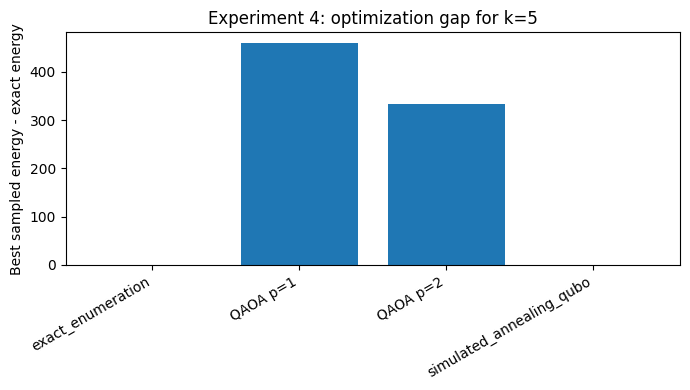

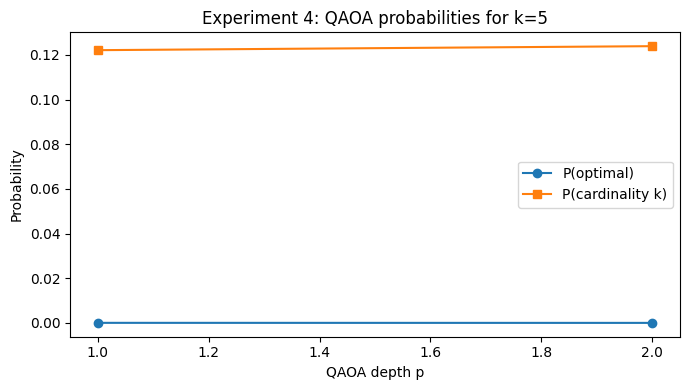

Experiment 4 saved:
 - kras_operator_space_v5_outputs\experiment_4_quantum_hybrid_optimization.csv


,method,p,energy,expectation,optimality_gap,relative_gap,optimal_probability,feasible_probability,cardinality,selected,total_nfev
0,exact_enumeration,NaN,-6574.992212,-6574.992212,0.000000,0.000000,1.000000,1.000000,5,"G12R, G13V, Q61L, K117N, A146T",NaN
1,qaoa_statevector_sampled_best,1.0,-6115.806633,174931.318439,459.185579,0.069838,0.000038,0.122134,5,"G12S, G12R, Q61L, K117N, A146T",576.0
2,qaoa_statevector_sampled_best,2.0,-6241.062471,170188.840797,333.929740,0.050788,0.000019,0.123923,5,"G12C, G12R, Q61L, K117N, A146T",1455.0
3,simulated_annealing_qubo,NaN,-6574.992212,NaN,0.000000,0.000000,NaN,1.000000,5,"G12R, G13V, Q61L, K117N, A146T",NaN


In [ ]:
# Save and visualize Experiment 4 outputs.
experiment_4_df.to_csv(OUTPUT_DIR / "experiment_4_quantum_hybrid_optimization.csv", index=False)

plt.figure(figsize=(7, 4))
plot_df = experiment_4_df.copy()
plot_df["label"] = plot_df.apply(
    lambda r: f"QAOA p={int(r['p'])}" if r["method"] == "qaoa_statevector_sampled_best" else r["method"],
    axis=1,
)
plt.bar(plot_df["label"], plot_df["optimality_gap"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("Best sampled energy - exact energy")
plt.title(f"Experiment 4: optimization gap for k={K_QOPT}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "experiment_4_optimization_gap.png", dpi=200)
plt.show()

plt.figure(figsize=(7, 4))
qaoa_plot = experiment_4_df[experiment_4_df["method"] == "qaoa_statevector_sampled_best"].copy()
if len(qaoa_plot) > 0:
    plt.plot(qaoa_plot["p"], qaoa_plot["optimal_probability"], marker="o", label="P(optimal)")
    plt.plot(qaoa_plot["p"], qaoa_plot["feasible_probability"], marker="s", label="P(cardinality k)")
    plt.xlabel("QAOA depth p")
    plt.ylabel("Probability")
    plt.title(f"Experiment 4: QAOA probabilities for k={K_QOPT}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "experiment_4_qaoa_probabilities.png", dpi=200)
    plt.show()

print("Experiment 4 saved:")
print(" -", OUTPUT_DIR / "experiment_4_quantum_hybrid_optimization.csv")
display(experiment_4_df)


## 12. Experiment 5 — Structural interpretation of selected representative subsets

In [ ]:
# ---------------------------------------------------------------------
# Experiment 5: structural/geometric analysis of representative subsets
# ---------------------------------------------------------------------

def subset_geometric_metrics(mask: np.ndarray, distance_matrix: np.ndarray) -> dict:
    """Compute geometric diversity and coverage metrics for a selected subset."""
    selected = np.where(mask == 1)[0]
    unselected_or_all = np.arange(distance_matrix.shape[0])

    if len(selected) <= 1:
        avg_pairwise_distance = np.nan
        min_pairwise_distance = np.nan
    else:
        pairwise = []
        for a, i in enumerate(selected):
            for j in selected[a + 1:]:
                pairwise.append(distance_matrix[i, j])
        avg_pairwise_distance = float(np.mean(pairwise))
        min_pairwise_distance = float(np.min(pairwise))

    # Coverage radius: mean distance from every mutation to the closest selected mutation.
    if len(selected) == 0:
        mean_coverage = np.nan
        max_coverage = np.nan
    else:
        nearest = np.min(distance_matrix[:, selected], axis=1)
        mean_coverage = float(np.mean(nearest))
        max_coverage = float(np.max(nearest))

    return {
        "avg_pairwise_distance": avg_pairwise_distance,
        "min_pairwise_distance": min_pairwise_distance,
        "mean_coverage_distance": mean_coverage,
        "max_coverage_distance": max_coverage,
    }


def row_for_subset(method: str, mask: np.ndarray) -> dict:
    components = variational_components(mask, V_vec, D_sq, MU)
    geom = subset_geometric_metrics(mask, D_hs)
    return {
        "method": method,
        "k": int(np.sum(mask)),
        "selected": ", ".join(names_from_mask(mask)),
        **components,
        **geom,
    }

# Representative subsets to compare.
exact_subset = exact_variational_selection(K_QOPT, V_vec, D_sq, MU)["mask"]
top_subset = top_energy_baseline(K_QOPT, V_vec, D_sq, MU)["mask"]
sa_subset = sa_result["mask"]

# Use the highest-depth QAOA result for structural interpretation.
best_p = max(QAOA_P_VALUES)
qaoa_subset = qaoa_results[best_p]["sampled_best_mask"]

experiment_5_rows = [
    row_for_subset("variational_exact", exact_subset),
    row_for_subset("top_perturbation_energy", top_subset),
    row_for_subset(f"qaoa_p{best_p}_sampled_best", qaoa_subset),
    row_for_subset("simulated_annealing_qubo", sa_subset),
]

experiment_5_df = pd.DataFrame(experiment_5_rows)
experiment_5_df


,method,k,selected,V,D,J,avg_pairwise_distance,min_pairwise_distance,mean_coverage_distance,max_coverage_distance
0,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,22.405483,13.426458,2.892936,8.257181
1,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,21.418127,2.723260,4.152138,11.744131
2,qaoa_p2_sampled_best,5,"G12C, G12R, Q61L, K117N, A146T",1348.567667,4892.494804,-6241.062471,21.281374,5.544150,3.604883,10.473815
3,simulated_annealing_qubo,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,22.405483,13.426458,2.892936,8.257181


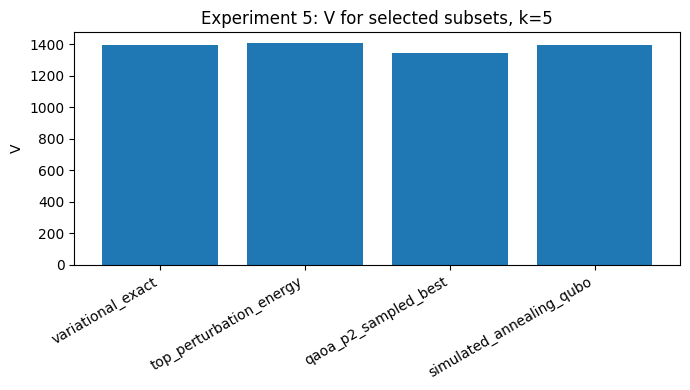

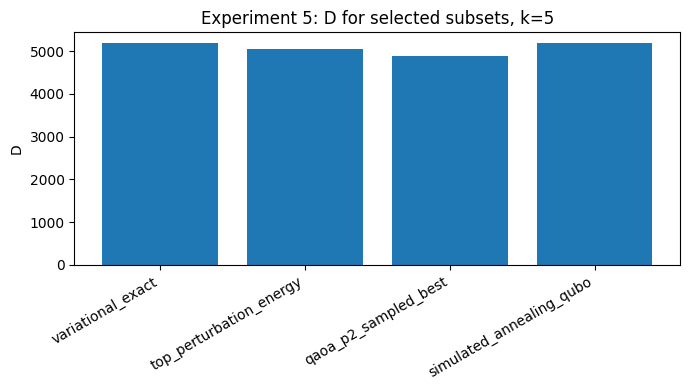

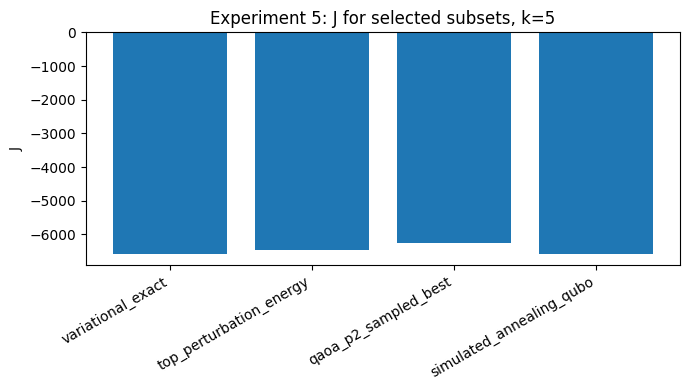

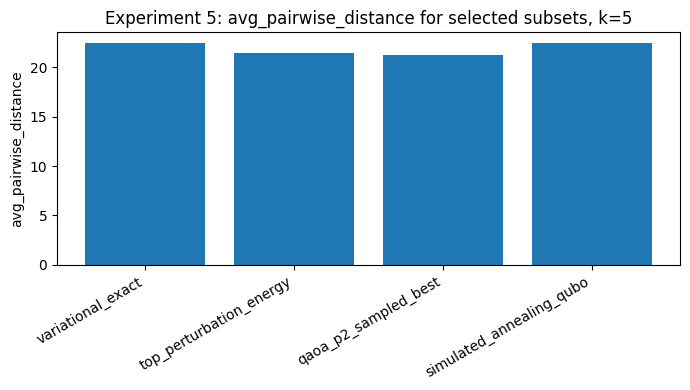

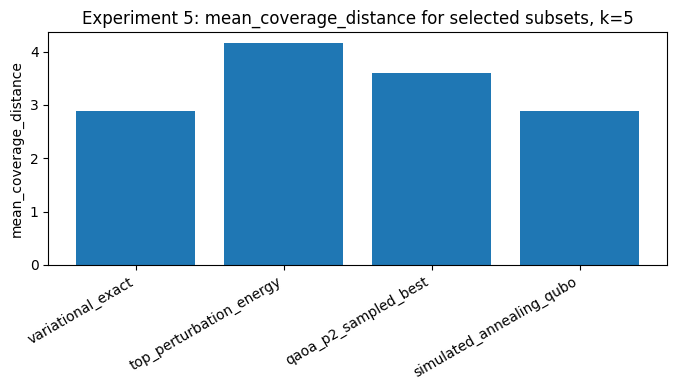

Experiment 5 saved:
 - kras_operator_space_v5_outputs\experiment_5_structural_interpretation.csv


,method,k,selected,V,D,J,avg_pairwise_distance,min_pairwise_distance,mean_coverage_distance,max_coverage_distance
0,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,22.405483,13.426458,2.892936,8.257181
1,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,21.418127,2.723260,4.152138,11.744131
2,qaoa_p2_sampled_best,5,"G12C, G12R, Q61L, K117N, A146T",1348.567667,4892.494804,-6241.062471,21.281374,5.544150,3.604883,10.473815
3,simulated_annealing_qubo,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,22.405483,13.426458,2.892936,8.257181


In [ ]:
# Save and visualize Experiment 5 outputs.
experiment_5_df.to_csv(OUTPUT_DIR / "experiment_5_structural_interpretation.csv", index=False)

metrics_to_plot = ["V", "D", "J", "avg_pairwise_distance", "mean_coverage_distance"]
for metric in metrics_to_plot:
    plt.figure(figsize=(7, 4))
    plt.bar(experiment_5_df["method"], experiment_5_df[metric])
    plt.xticks(rotation=30, ha="right")
    plt.ylabel(metric)
    plt.title(f"Experiment 5: {metric} for selected subsets, k={K_QOPT}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"experiment_5_{metric}.png", dpi=200)
    plt.show()

print("Experiment 5 saved:")
print(" -", OUTPUT_DIR / "experiment_5_structural_interpretation.csv")
display(experiment_5_df)


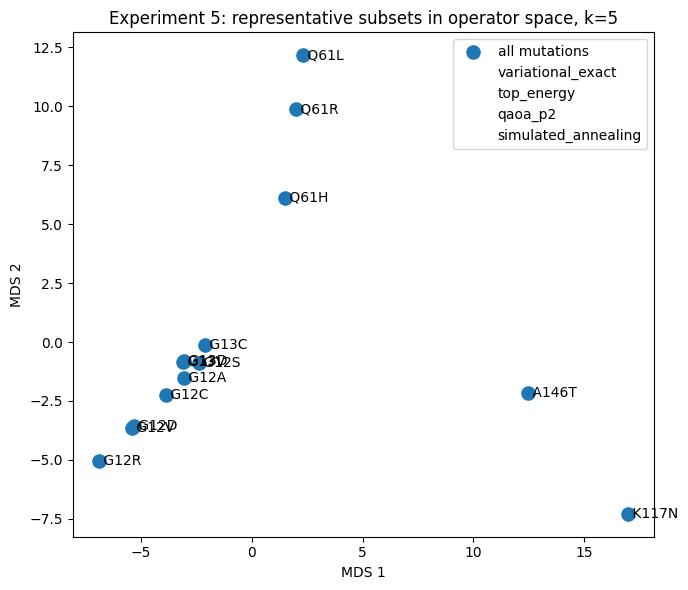

In [ ]:
# Visualize selected subsets on the MDS embedding of the mutation operator space.
plt.figure(figsize=(7, 6))
plt.scatter(mds_coords[:, 0], mds_coords[:, 1], s=90, label="all mutations")

for i, name in enumerate(mutation_names):
    plt.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", va="center")

selection_masks = {
    "variational_exact": exact_subset,
    "top_energy": top_subset,
    f"qaoa_p{best_p}": qaoa_subset,
    "simulated_annealing": sa_subset,
}

markers = ["o", "s", "^", "D"]
for marker, (method, mask) in zip(markers, selection_masks.items()):
    idx = np.where(mask == 1)[0]
    plt.scatter(
        mds_coords[idx, 0],
        mds_coords[idx, 1],
        s=220,
        facecolors="none",
        linewidths=2,
        marker=marker,
        label=method,
    )

plt.xlabel("MDS 1")
plt.ylabel("MDS 2")
plt.title(f"Experiment 5: representative subsets in operator space, k={K_QOPT}")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "experiment_5_mds_representative_subsets.png", dpi=200)
plt.show()


## 13. Supplementary experiment — sensitivity to the diversity parameter

,k,mu,selected,V,D,J
0,4,0.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-1270.197187
1,4,0.01,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-1305.834368
2,4,0.10,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-1626.569004
3,4,0.50,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-3052.056270
4,4,1.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354
5,4,2.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-8397.633521
6,4,5.00,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-19088.788022
7,5,0.00,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1406.470127
8,5,0.01,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1456.898934
9,5,0.10,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-1912.699573


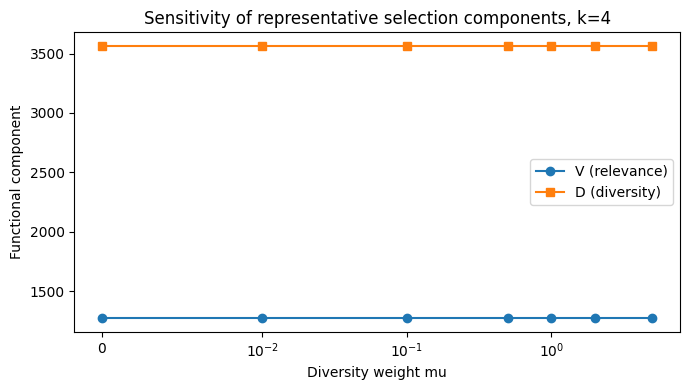

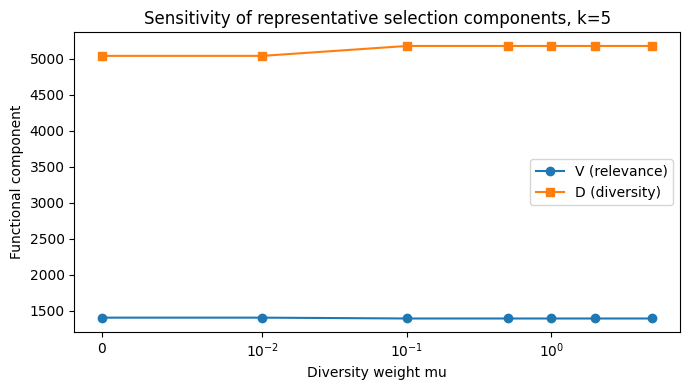

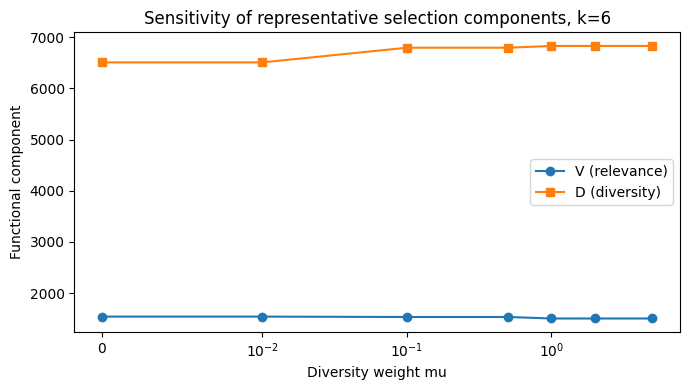

In [ ]:
MU_VALUES = [0.0, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0]
K_SENS_VALUES = k_values

sensitivity_rows = []
for k in K_SENS_VALUES:
    for mu_value in MU_VALUES:
        exact = exact_variational_selection(k, V_vec, D_sq, mu=mu_value)
        sensitivity_rows.append({
            "k": k,
            "mu": mu_value,
            "selected": ", ".join(exact["selected"]),
            "V": exact["V"],
            "D": exact["D"],
            "J": exact["J"],
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df.to_csv(OUTPUT_DIR / "supplementary_mu_sensitivity.csv", index=False)
display(sensitivity_df)

for k in K_SENS_VALUES:
    sub = sensitivity_df[sensitivity_df["k"] == k]
    plt.figure(figsize=(7, 4))
    plt.plot(sub["mu"], sub["V"], marker="o", label="V (relevance)")
    plt.plot(sub["mu"], sub["D"], marker="s", label="D (diversity)")
    plt.xscale("symlog", linthresh=0.01)
    plt.xlabel("Diversity weight mu")
    plt.ylabel("Functional component")
    plt.title(f"Sensitivity of representative selection components, k={k}")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"supplementary_mu_sensitivity_k{k}.png", dpi=200)
    plt.show()


## 14. Experiment 6 — Geometry preservation in the Ising interaction graph

In [ ]:
# ---------------------------------------------------------------------
# Experiment 6: Geometry preservation under the Ising transformation
# ---------------------------------------------------------------------
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr, pearsonr

# We use the same representative cardinality and penalty scale as Experiment 4
# when available. Otherwise, we build a safe default from the exact-penalty bound.
try:
    K_GEOM_HAM = K_QOPT
except NameError:
    K_GEOM_HAM = min(3, N_mut)

try:
    LAMBDA_GEOM_HAM = LAMBDA_QOPT
except NameError:
    B_bound_geom = penalty_bound_B(V_vec, D_sq, MU)
    LAMBDA_GEOM_HAM = 1.05 * B_bound_geom if B_bound_geom > 0 else 1.0

A_geom_ham = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_GEOM_HAM, K_GEOM_HAM)
ising_geom_coeffs = ising_coefficients_from_A(A_geom_ham, LAMBDA_GEOM_HAM, K_GEOM_HAM)
J_couplings = ising_geom_coeffs["J"].copy()

# The Hamiltonian coupling matrix is not itself a distance matrix. Since
# J_ij = lambda/2 - mu/4 * D_ij, a coupling-induced dissimilarity can be
# obtained by reversing the affine transformation on the off-diagonal entries.
J_off = J_couplings[np.triu_indices(N_mut, k=1)]
J_max = float(np.max(J_off)) if len(J_off) > 0 else 0.0

D_from_J = np.zeros_like(J_couplings, dtype=float)
for i in range(N_mut):
    for j in range(N_mut):
        if i == j:
            D_from_J[i, j] = 0.0
        else:
            D_from_J[i, j] = J_max - J_couplings[i, j]

# Numerical comparison between original geometry and Ising coupling structure.
D_sq_off = D_sq[np.triu_indices(N_mut, k=1)]
D_hs_off = D_hs[np.triu_indices(N_mut, k=1)]

if len(D_sq_off) > 1:
    spearman_Dsq_J = spearmanr(D_sq_off, J_off).correlation
    pearson_Dsq_J = pearsonr(D_sq_off, J_off).statistic
    spearman_Dhs_J = spearmanr(D_hs_off, J_off).correlation
    pearson_Dhs_J = pearsonr(D_hs_off, J_off).statistic
else:
    spearman_Dsq_J = np.nan
    pearson_Dsq_J = np.nan
    spearman_Dhs_J = np.nan
    pearson_Dhs_J = np.nan

geometry_hamiltonian_summary = pd.DataFrame([
    {
        "k": K_GEOM_HAM,
        "lambda": LAMBDA_GEOM_HAM,
        "mu": MU,
        "spearman_Dsq_vs_J": spearman_Dsq_J,
        "pearson_Dsq_vs_J": pearson_Dsq_J,
        "spearman_Dhs_vs_J": spearman_Dhs_J,
        "pearson_Dhs_vs_J": pearson_Dhs_J,
        "max_abs_Dsq_affine_error": float(np.max(np.abs(D_from_J - (MU / 4.0) * D_sq))) if N_mut > 1 else np.nan,
    }
])

geometry_hamiltonian_summary.to_csv(
    OUTPUT_DIR / "experiment_6_geometry_hamiltonian_summary.csv",
    index=False,
)
display(geometry_hamiltonian_summary)

print("Theory check:")
print("J_ij should be an affine decreasing function of D_ij = d^2.")
print("Spearman correlation between D^2 and J should be close to -1.")

,k,lambda,mu,spearman_Dsq_vs_J,pearson_Dsq_vs_J,spearman_Dhs_vs_J,pearson_Dhs_vs_J,max_abs_Dsq_affine_error
0,5,25389.536101,1.0,-1.0,-1.0,-1.0,-0.968464,0.007627


Theory check:
J_ij should be an affine decreasing function of D_ij = d^2.
Spearman correlation between D^2 and J should be close to -1.


C:\Users\Roberto\AppData\Local\Temp\ipykernel_31680\2368082020.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


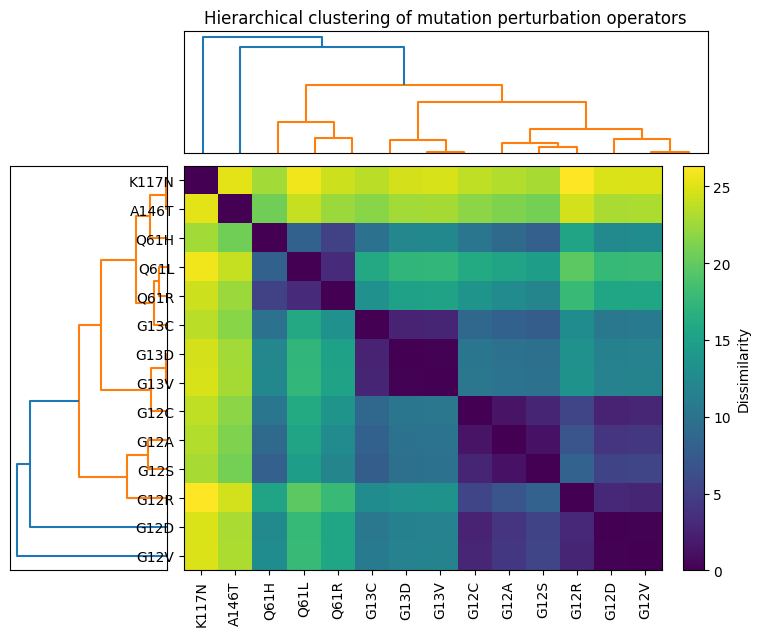

C:\Users\Roberto\AppData\Local\Temp\ipykernel_31680\2368082020.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


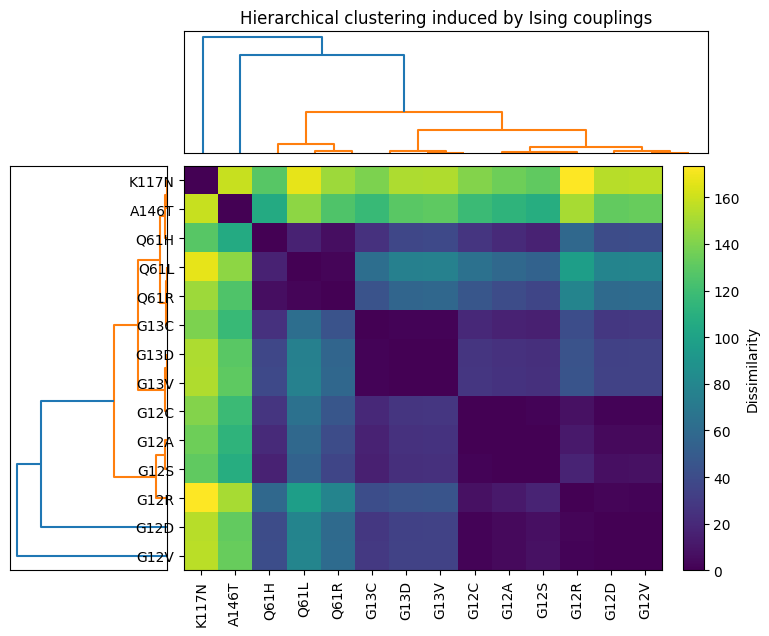

Saved: kras_operator_space_v5_outputs\experiment_6_dendrogram_heatmap_operator_distance.png
Saved: kras_operator_space_v5_outputs\experiment_6_dendrogram_heatmap_ising_couplings.png


In [ ]:
# ---------------------------------------------------------------------
# Helper functions for clustered heatmaps and dendrograms
# ---------------------------------------------------------------------
def safe_linkage_from_distance(distance_matrix: np.ndarray, method: str = "average"):
    """Return hierarchical linkage matrix from a symmetric distance matrix."""
    if distance_matrix.shape[0] < 2:
        return None
    condensed = squareform(distance_matrix, checks=False)
    return linkage(condensed, method=method)


def plot_dendrogram_heatmap(
    distance_matrix: np.ndarray,
    labels: list[str],
    title: str,
    filename: str,
    method: str = "average",
):
    """Plot a dendrogram and the distance matrix ordered by hierarchical clustering."""
    Z = safe_linkage_from_distance(distance_matrix, method=method)

    if Z is None:
        print("Not enough mutations for dendrogram.")
        return None

    order = leaves_list(Z)
    ordered_matrix = distance_matrix[np.ix_(order, order)]
    ordered_labels = [labels[i] for i in order]

    fig = plt.figure(figsize=(9, 7))
    gs = fig.add_gridspec(
        nrows=2,
        ncols=2,
        width_ratios=[1.2, 4.0],
        height_ratios=[1.2, 4.0],
        wspace=0.05,
        hspace=0.05,
    )

    ax_top = fig.add_subplot(gs[0, 1])
    dendrogram(Z, ax=ax_top, no_labels=True, color_threshold=None)
    ax_top.set_xticks([])
    ax_top.set_yticks([])
    ax_top.set_title(title)

    ax_left = fig.add_subplot(gs[1, 0])
    dendrogram(Z, ax=ax_left, orientation="left", no_labels=True, color_threshold=None)
    ax_left.set_xticks([])
    ax_left.set_yticks([])

    ax_heat = fig.add_subplot(gs[1, 1])
    im = ax_heat.imshow(ordered_matrix, aspect="auto")
    ax_heat.set_xticks(np.arange(len(ordered_labels)))
    ax_heat.set_yticks(np.arange(len(ordered_labels)))
    ax_heat.set_xticklabels(ordered_labels, rotation=90)
    ax_heat.set_yticklabels(ordered_labels)

    cbar = fig.colorbar(im, ax=ax_heat, fraction=0.046, pad=0.04)
    cbar.set_label("Dissimilarity")

    fig.tight_layout()
    out_path = OUTPUT_DIR / filename
    fig.savefig(out_path, dpi=250, bbox_inches="tight")
    plt.show()

    return {
        "linkage": Z,
        "order": order,
        "ordered_labels": ordered_labels,
        "path": out_path,
    }


# Clustered heatmap of the original operator geometry.
cluster_D = plot_dendrogram_heatmap(
    distance_matrix=D_hs,
    labels=mutation_names,
    title="Hierarchical clustering of mutation perturbation operators",
    filename="experiment_6_dendrogram_heatmap_operator_distance.png",
)

# Clustered heatmap of the Ising coupling-induced dissimilarity.
cluster_J = plot_dendrogram_heatmap(
    distance_matrix=D_from_J,
    labels=mutation_names,
    title="Hierarchical clustering induced by Ising couplings",
    filename="experiment_6_dendrogram_heatmap_ising_couplings.png",
)

if cluster_D is not None:
    print("Saved:", cluster_D["path"])
if cluster_J is not None:
    print("Saved:", cluster_J["path"])

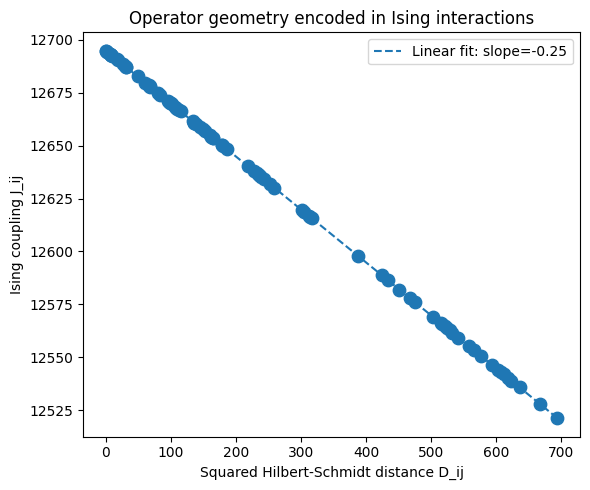

Saved: kras_operator_space_v5_outputs\experiment_6_distance_vs_ising_coupling.png
Spearman(D^2, J) = -1.000000
Pearson(D^2, J)  = -1.000000


In [ ]:
# ---------------------------------------------------------------------
# Scatter plot: operator distances versus Ising couplings
# ---------------------------------------------------------------------
plt.figure(figsize=(6, 5))
plt.scatter(D_sq_off, J_off, s=80)

if len(D_sq_off) > 1:
    slope, intercept = np.polyfit(D_sq_off, J_off, deg=1)
    x_line = np.linspace(float(np.min(D_sq_off)), float(np.max(D_sq_off)), 100)
    y_line = slope * x_line + intercept
    plt.plot(x_line, y_line, linestyle="--", label=f"Linear fit: slope={slope:.3g}")

plt.xlabel("Squared Hilbert-Schmidt distance D_ij")
plt.ylabel("Ising coupling J_ij")
plt.title("Operator geometry encoded in Ising interactions")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_6_distance_vs_ising_coupling.png"
plt.savefig(out_path, dpi=250)
plt.show()

print("Saved:", out_path)
print(f"Spearman(D^2, J) = {spearman_Dsq_J:.6f}")
print(f"Pearson(D^2, J)  = {pearson_Dsq_J:.6f}")

,mutation,cluster_operator_distance,hs_norm
10,Q61L,1,13.430102
11,Q61R,2,10.339035
9,Q61H,3,5.290656
7,G13C,4,8.460647
6,G13D,4,10.981945
8,G13V,4,11.156607
3,G12A,5,7.427498
2,G12C,5,8.852710
4,G12S,5,6.139679
0,G12D,6,11.490845


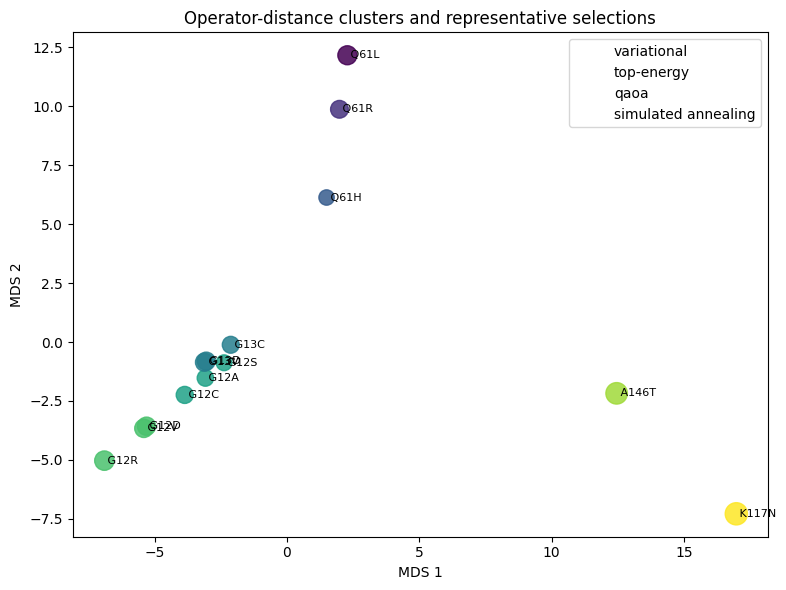

Saved: kras_operator_space_v5_outputs\experiment_6_mds_clusters_and_selected_subsets.png


In [ ]:
# ---------------------------------------------------------------------
# Cluster labels and representative subsets on the MDS embedding
# ---------------------------------------------------------------------
N_CLUSTERS = min(8, N_mut)

if cluster_D is not None and N_mut >= 2:
    cluster_labels = fcluster(cluster_D["linkage"], t=N_CLUSTERS, criterion="maxclust")
else:
    cluster_labels = np.ones(N_mut, dtype=int)

cluster_df = pd.DataFrame({
    "mutation": mutation_names,
    "cluster_operator_distance": cluster_labels,
    "hs_norm": np.sqrt(V_vec),
})
cluster_df.to_csv(OUTPUT_DIR / "experiment_6_operator_distance_clusters.csv", index=False)
display(cluster_df.sort_values(["cluster_operator_distance", "mutation"]))

# Select the same representative subsets compared in Experiment 5 when available.
selection_masks = {}
try:
    selection_masks["variational"] = exact_subset
except NameError:
    selection_masks["variational"] = exact_variational_selection(K_GEOM_HAM, V_vec, D_sq, MU)["mask"]

try:
    selection_masks["top-energy"] = top_subset
except NameError:
    selection_masks["top-energy"] = top_energy_baseline(K_GEOM_HAM, V_vec, D_sq, MU)["mask"]

try:
    selection_masks["qaoa"] = qaoa_subset
except NameError:
    pass

try:
    selection_masks["simulated annealing"] = sa_subset
except NameError:
    pass

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    mds_coords[:, 0],
    mds_coords[:, 1],
    s=80 + 8 * np.sqrt(V_vec),
    c=cluster_labels,
    alpha=0.85,
)

for i, name in enumerate(mutation_names):
    plt.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", va="center", fontsize=8)

# Overlay representative selections with empty markers.
marker_cycle = ["o", "s", "^", "D"]
for marker, (label, mask) in zip(marker_cycle, selection_masks.items()):
    idx = np.where(mask == 1)[0]
    plt.scatter(
        mds_coords[idx, 0],
        mds_coords[idx, 1],
        s=260,
        marker=marker,
        facecolors="none",
        linewidths=2,
        label=label,
    )

plt.xlabel("MDS 1")
plt.ylabel("MDS 2")
plt.title("Operator-distance clusters and representative selections")
plt.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_6_mds_clusters_and_selected_subsets.png"
plt.savefig(out_path, dpi=250)
plt.show()

print("Saved:", out_path)

,method,k,selected,covered_clusters,n_covered_clusters,total_clusters,cluster_coverage_ratio
0,variational,5,"G12R, G13V, Q61L, K117N, A146T","1, 4, 6, 7, 8",5,8,0.625
1,top-energy,5,"G12V, G12R, Q61L, K117N, A146T","1, 6, 7, 8",4,8,0.500
2,qaoa,5,"G12C, G12R, Q61L, K117N, A146T","1, 5, 6, 7, 8",5,8,0.625
3,simulated annealing,5,"G12R, G13V, Q61L, K117N, A146T","1, 4, 6, 7, 8",5,8,0.625


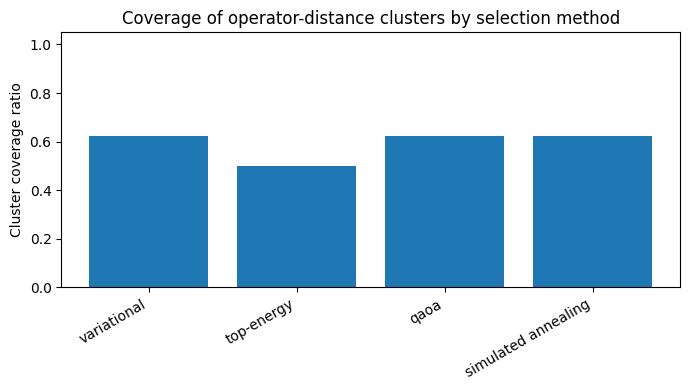

Saved: kras_operator_space_v5_outputs\experiment_6_cluster_coverage_ratio.png


In [ ]:
# ---------------------------------------------------------------------
# Cluster coverage by representative subsets
# ---------------------------------------------------------------------
coverage_rows = []

for method, mask in selection_masks.items():
    selected_idx = np.where(mask == 1)[0]
    covered_clusters = sorted(set(cluster_labels[selected_idx]))
    coverage_rows.append({
        "method": method,
        "k": int(mask.sum()),
        "selected": ", ".join(names_from_mask(mask)),
        "covered_clusters": ", ".join(map(str, covered_clusters)),
        "n_covered_clusters": len(covered_clusters),
        "total_clusters": int(len(set(cluster_labels))),
        "cluster_coverage_ratio": len(covered_clusters) / max(1, len(set(cluster_labels))),
    })

cluster_coverage_df = pd.DataFrame(coverage_rows)
cluster_coverage_df.to_csv(
    OUTPUT_DIR / "experiment_6_cluster_coverage_by_method.csv",
    index=False,
)
display(cluster_coverage_df)

plt.figure(figsize=(7, 4))
plt.bar(cluster_coverage_df["method"], cluster_coverage_df["cluster_coverage_ratio"])
plt.ylim(0, 1.05)
plt.ylabel("Cluster coverage ratio")
plt.title("Coverage of operator-distance clusters by selection method")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_6_cluster_coverage_ratio.png"
plt.savefig(out_path, dpi=250)
plt.show()

print("Saved:", out_path)

## 15. Paper-ready geometry--Hamiltonian figures

C:\Users\Roberto\AppData\Local\Temp\ipykernel_31680\1918869086.py:87: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


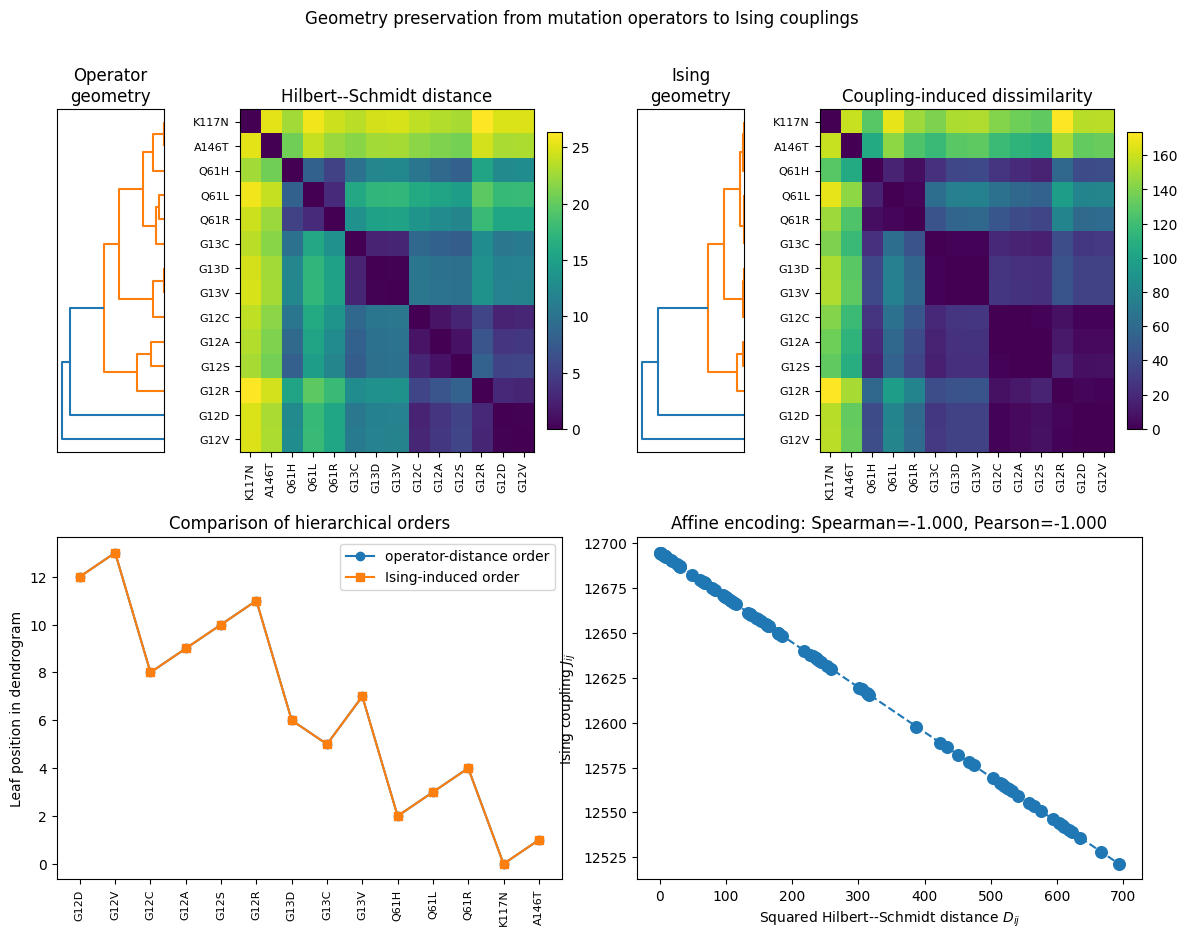

Saved: kras_operator_space_v5_outputs\experiment_7_geometry_hamiltonian_four_panel.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 7A: four-panel comparison of operator geometry and Ising geometry
# ---------------------------------------------------------------------
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import squareform

# Build linkage objects if they are not already available from Experiment 6.
if 'cluster_D' in globals() and cluster_D is not None:
    Z_D = cluster_D['linkage']
    order_D = cluster_D['order']
else:
    Z_D = linkage(squareform(D_hs, checks=False), method='average')
    order_D = leaves_list(Z_D)

if 'cluster_J' in globals() and cluster_J is not None:
    Z_J = cluster_J['linkage']
    order_J = cluster_J['order']
else:
    Z_J = linkage(squareform(D_from_J, checks=False), method='average')
    order_J = leaves_list(Z_J)

ordered_D = D_hs[np.ix_(order_D, order_D)]
ordered_J = D_from_J[np.ix_(order_J, order_J)]
labels_D = [mutation_names[i] for i in order_D]
labels_J = [mutation_names[i] for i in order_J]

fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 4, width_ratios=[1.0, 3.0, 1.0, 3.0], wspace=0.35, hspace=0.25)

# Operator-distance dendrogram and heatmap
ax_dend_D = fig.add_subplot(gs[0, 0])
dendrogram(Z_D, ax=ax_dend_D, orientation='left', no_labels=True, color_threshold=None)
ax_dend_D.set_xticks([])
ax_dend_D.set_yticks([])
ax_dend_D.set_title('Operator\ngeometry')

ax_heat_D = fig.add_subplot(gs[0, 1])
im_D = ax_heat_D.imshow(ordered_D, aspect='auto')
ax_heat_D.set_xticks(np.arange(len(labels_D)))
ax_heat_D.set_yticks(np.arange(len(labels_D)))
ax_heat_D.set_xticklabels(labels_D, rotation=90, fontsize=8)
ax_heat_D.set_yticklabels(labels_D, fontsize=8)
ax_heat_D.set_title('Hilbert--Schmidt distance')
fig.colorbar(im_D, ax=ax_heat_D, fraction=0.046, pad=0.04)

# Ising-coupling dendrogram and heatmap
ax_dend_J = fig.add_subplot(gs[0, 2])
dendrogram(Z_J, ax=ax_dend_J, orientation='left', no_labels=True, color_threshold=None)
ax_dend_J.set_xticks([])
ax_dend_J.set_yticks([])
ax_dend_J.set_title('Ising\ngeometry')

ax_heat_J = fig.add_subplot(gs[0, 3])
im_J = ax_heat_J.imshow(ordered_J, aspect='auto')
ax_heat_J.set_xticks(np.arange(len(labels_J)))
ax_heat_J.set_yticks(np.arange(len(labels_J)))
ax_heat_J.set_xticklabels(labels_J, rotation=90, fontsize=8)
ax_heat_J.set_yticklabels(labels_J, fontsize=8)
ax_heat_J.set_title('Coupling-induced dissimilarity')
fig.colorbar(im_J, ax=ax_heat_J, fraction=0.046, pad=0.04)

# Lower panels: direct comparison of the two orders
ax_order = fig.add_subplot(gs[1, :2])
rank_D = {mutation_names[idx]: pos for pos, idx in enumerate(order_D)}
rank_J = {mutation_names[idx]: pos for pos, idx in enumerate(order_J)}
common_labels = mutation_names
x_pos = np.arange(len(common_labels))
ax_order.plot(x_pos, [rank_D[m] for m in common_labels], marker='o', label='operator-distance order')
ax_order.plot(x_pos, [rank_J[m] for m in common_labels], marker='s', label='Ising-induced order')
ax_order.set_xticks(x_pos)
ax_order.set_xticklabels(common_labels, rotation=90, fontsize=8)
ax_order.set_ylabel('Leaf position in dendrogram')
ax_order.set_title('Comparison of hierarchical orders')
ax_order.legend()

ax_scatter = fig.add_subplot(gs[1, 2:])
ax_scatter.scatter(D_sq_off, J_off, s=70)
if len(D_sq_off) > 1:
    slope, intercept = np.polyfit(D_sq_off, J_off, deg=1)
    x_line = np.linspace(float(np.min(D_sq_off)), float(np.max(D_sq_off)), 100)
    ax_scatter.plot(x_line, slope * x_line + intercept, linestyle='--')
ax_scatter.set_xlabel('Squared Hilbert--Schmidt distance $D_{ij}$')
ax_scatter.set_ylabel('Ising coupling $J_{ij}$')
ax_scatter.set_title(f'Affine encoding: Spearman={spearman_Dsq_J:.3f}, Pearson={pearson_Dsq_J:.3f}')

fig.suptitle('Geometry preservation from mutation operators to Ising couplings', y=0.98)
fig.tight_layout()
out_path = OUTPUT_DIR / 'experiment_7_geometry_hamiltonian_four_panel.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


C:\Users\Roberto\anaconda3\envs\Computacion-cuantica\Lib\site-packages\sklearn\manifold\_mds.py:744: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9. To suppress this warning, provide some value of `n_init`.
  warnings.warn(
C:\Users\Roberto\anaconda3\envs\Computacion-cuantica\Lib\site-packages\sklearn\manifold\_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
C:\Users\Roberto\anaconda3\envs\Computacion-cuantica\Lib\site-packages\sklearn\manifold\_mds.py:771: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(
C:\Users\Roberto\anaconda3\envs\Computacion-cuantica\Lib\site-packages\sklearn\manifold\_mds.py:744: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9. To suppress this warning, provide some value of `n_init`.
  warnings.w

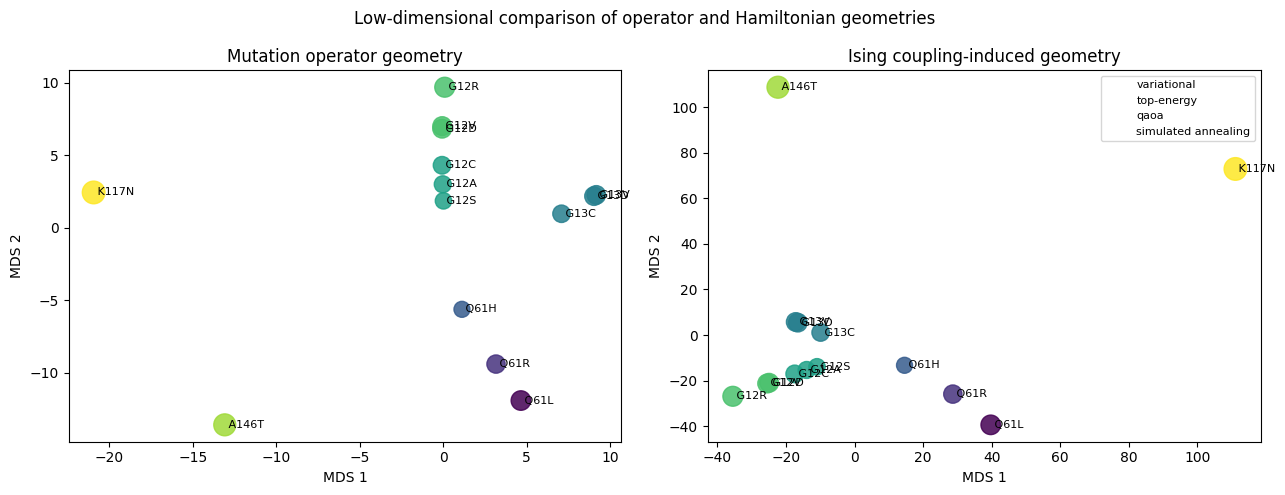

Saved: kras_operator_space_v5_outputs\experiment_7_mds_operator_vs_ising_geometry.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 7B: side-by-side MDS embeddings of D and J-induced geometry
# ---------------------------------------------------------------------
from sklearn.manifold import MDS

mds_operator = MDS(n_components=2, dissimilarity='precomputed', random_state=RANDOM_SEED, normalized_stress='auto')
coords_D = mds_operator.fit_transform(D_hs)

mds_ising = MDS(n_components=2, dissimilarity='precomputed', random_state=RANDOM_SEED, normalized_stress='auto')
coords_J = mds_ising.fit_transform(D_from_J)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, coords, title in [
    (axes[0], coords_D, 'Mutation operator geometry'),
    (axes[1], coords_J, 'Ising coupling-induced geometry'),
]:
    sc = ax.scatter(coords[:, 0], coords[:, 1], s=90 + 8 * np.sqrt(V_vec), c=cluster_labels, alpha=0.85)
    for i, name in enumerate(mutation_names):
        ax.text(coords[i, 0], coords[i, 1], f' {name}', va='center', fontsize=8)
    for marker, (label, mask) in zip(['o', 's', '^', 'D'], selection_masks.items()):
        idx = np.where(mask == 1)[0]
        ax.scatter(coords[idx, 0], coords[idx, 1], s=260, marker=marker, facecolors='none', linewidths=2, label=label)
    ax.set_xlabel('MDS 1')
    ax.set_ylabel('MDS 2')
    ax.set_title(title)

axes[1].legend(loc='best', fontsize=8)
fig.suptitle('Low-dimensional comparison of operator and Hamiltonian geometries')
fig.tight_layout()
out_path = OUTPUT_DIR / 'experiment_7_mds_operator_vs_ising_geometry.png'
fig.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


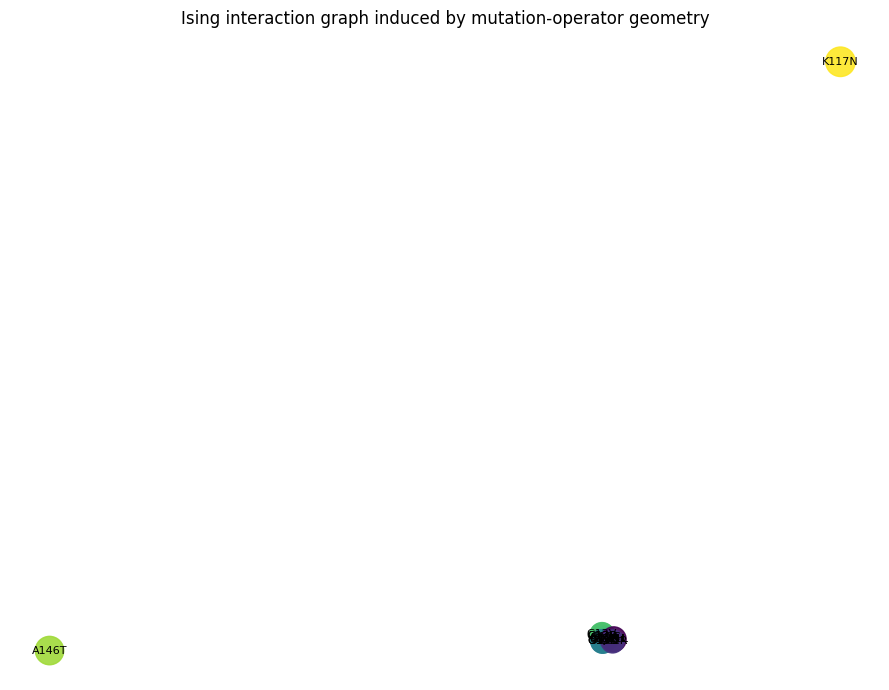

Saved: kras_operator_space_v5_outputs\experiment_7_ising_interaction_graph.png


,n_nodes,n_edges_shown,edge_threshold_abs_J,max_abs_J,min_abs_J
0,14,32,12668.061337,12694.760424,12521.301174


In [ ]:
# ---------------------------------------------------------------------
# Experiment 7C: weighted Ising interaction graph
# ---------------------------------------------------------------------
# This graph represents the two-body part of the cost Hamiltonian. Nodes are
# mutations, edges are weighted by |J_ij|, and node colors are operator-distance clusters.

G_ising = nx.Graph()
for i, name in enumerate(mutation_names):
    G_ising.add_node(name, cluster=int(cluster_labels[i]), hs_norm=float(np.sqrt(V_vec[i])))

abs_J = np.abs(J_couplings)
upper_abs_J = abs_J[np.triu_indices(N_mut, k=1)]
threshold = np.quantile(upper_abs_J, 0.65) if len(upper_abs_J) > 0 else 0.0

for i in range(N_mut):
    for j in range(i + 1, N_mut):
        weight = float(abs_J[i, j])
        if weight >= threshold:
            G_ising.add_edge(mutation_names[i], mutation_names[j], weight=weight, signed_weight=float(J_couplings[i, j]))

pos = nx.spring_layout(G_ising, seed=RANDOM_SEED, weight='weight')
node_sizes = [120 + 15 * G_ising.nodes[n]['hs_norm'] for n in G_ising.nodes]
node_colors = [G_ising.nodes[n]['cluster'] for n in G_ising.nodes]
edge_widths = [0.8 + 3.0 * G_ising[u][v]['weight'] / max(threshold, 1e-12) for u, v in G_ising.edges]

plt.figure(figsize=(9, 7))
nx.draw_networkx_edges(G_ising, pos, width=edge_widths, alpha=0.55)
nx.draw_networkx_nodes(G_ising, pos, node_size=node_sizes, node_color=node_colors, alpha=0.9)
nx.draw_networkx_labels(G_ising, pos, font_size=8)
plt.title('Ising interaction graph induced by mutation-operator geometry')
plt.axis('off')
plt.tight_layout()
out_path = OUTPUT_DIR / 'experiment_7_ising_interaction_graph.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)

ising_graph_summary = pd.DataFrame([
    {
        'n_nodes': G_ising.number_of_nodes(),
        'n_edges_shown': G_ising.number_of_edges(),
        'edge_threshold_abs_J': threshold,
        'max_abs_J': float(np.max(upper_abs_J)) if len(upper_abs_J) else np.nan,
        'min_abs_J': float(np.min(upper_abs_J)) if len(upper_abs_J) else np.nan,
    }
])
display(ising_graph_summary)
ising_graph_summary.to_csv(OUTPUT_DIR / 'experiment_7_ising_interaction_graph_summary.csv', index=False)


In [ ]:
# ---------------------------------------------------------------------
# Experiment 7D: compact manuscript figure table
# ---------------------------------------------------------------------
figure_table = pd.DataFrame([
    {
        'figure': 'Fig. 1',
        'candidate_file': 'kras_rin_3d.png',
        'main_message': 'KRAS is converted into a residue interaction network and graph Laplacian.',
        'supports': 'Section 2 / Experiment 1',
    },
    {
        'figure': 'Fig. 2',
        'candidate_file': 'mutation_operator_distance_matrix.png + mutation_operator_gram_matrix.png',
        'main_message': 'Mutation perturbations form a nontrivial operator space with Hilbert--Schmidt geometry.',
        'supports': 'Sections 2.3 and 3.1 / Experiment 1',
    },
    {
        'figure': 'Fig. 3',
        'candidate_file': 'experiment_5_mds_representative_subsets.png',
        'main_message': 'The variational functional selects high-impact and geometrically diverse mutation representatives.',
        'supports': 'Section 3.1 / Experiment 2',
    },
    {
        'figure': 'Fig. 4',
        'candidate_file': 'experiment_3_qubo_ising_minima.png',
        'main_message': 'The variational, QUBO and Ising formulations are numerically equivalent.',
        'supports': 'Sections 3.2 and 3.3 / Experiment 3',
    },
    {
        'figure': 'Fig. 5',
        'candidate_file': 'experiment_7_geometry_hamiltonian_four_panel.png',
        'main_message': 'The geometry of mutation operators is encoded in the Ising coupling structure.',
        'supports': 'Section 3.3 / Experiment 6-7',
    },
    {
        'figure': 'Fig. 6',
        'candidate_file': 'experiment_4_optimization_gap.png',
        'main_message': 'Quantum/hybrid optimizers operate on the same cost Hamiltonian and approximate its optimum.',
        'supports': 'Section 3.4 / Experiment 4',
    },
])

figure_table.to_csv(OUTPUT_DIR / 'paper_candidate_figures_v7.csv', index=False)
display(figure_table)
print('Saved:', OUTPUT_DIR / 'paper_candidate_figures_v7.csv')


,figure,candidate_file,main_message,supports
0,Fig. 1,kras_rin_3d.png,KRAS is converted into a residue interaction n...,Section 2 / Experiment 1
1,Fig. 2,mutation_operator_distance_matrix.png + mutati...,Mutation perturbations form a nontrivial opera...,Sections 2.3 and 3.1 / Experiment 1
2,Fig. 3,experiment_5_mds_representative_subsets.png,The variational functional selects high-impact...,Section 3.1 / Experiment 2
3,Fig. 4,experiment_3_qubo_ising_minima.png,"The variational, QUBO and Ising formulations a...",Sections 3.2 and 3.3 / Experiment 3
4,Fig. 5,experiment_7_geometry_hamiltonian_four_panel.png,The geometry of mutation operators is encoded ...,Section 3.3 / Experiment 6-7
5,Fig. 6,experiment_4_optimization_gap.png,Quantum/hybrid optimizers operate on the same ...,Section 3.4 / Experiment 4


Saved: kras_operator_space_v5_outputs\paper_candidate_figures_v7.csv


## 16. Publication-grade hierarchical clustering visualizations


In [ ]:
# ---------------------------------------------------------------------
# Experiment 8A: utilities for clearer clustering figures
# ---------------------------------------------------------------------
import re
from matplotlib.gridspec import GridSpec
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list, fcluster
from scipy.spatial.distance import squareform

# Use the operator-distance matrix already computed in the notebook.
# D_hs is the Hilbert--Schmidt distance between mutation perturbation operators.
# D_from_J is the distance-like representation induced by Ising couplings.

if 'D_hs' not in globals():
    D_hs = np.sqrt(D_sq)

if 'Z_D' not in globals():
    Z_D = linkage(squareform(D_hs, checks=False), method='average')

if 'order_D' not in globals():
    order_D = leaves_list(Z_D)

if 'D_from_J' in globals():
    if 'Z_J' not in globals():
        Z_J = linkage(squareform(D_from_J, checks=False), method='average')
    if 'order_J' not in globals():
        order_J = leaves_list(Z_J)
else:
    Z_J = None
    order_J = None

# Residue-site extraction from mutation names such as G12D, Q61L, A146T.
def mutation_site(name: str):
    match = re.search(r"(\d+)", str(name))
    return int(match.group(1)) if match else -1

mutation_sites = np.array([mutation_site(name) for name in mutation_names])
unique_sites = sorted(set(mutation_sites))

# Stable color assignment by residue position.
site_cmap = plt.cm.get_cmap('tab20', max(1, len(unique_sites)))
site_to_color = {site: site_cmap(i) for i, site in enumerate(unique_sites)}
mutation_label_colors = {name: site_to_color[site] for name, site in zip(mutation_names, mutation_sites)}

# Operator clusters used for coloring selected figures.
N_CLUSTER_VIS = min(8, N_mut)
cluster_labels_vis = fcluster(Z_D, t=N_CLUSTER_VIS, criterion='maxclust') if N_mut >= 2 else np.ones(N_mut, dtype=int)

print('Mutation sites:', dict(zip(mutation_names, mutation_sites)))
print('Number of visualization clusters:', len(set(cluster_labels_vis)))


Mutation sites: {'G12D': np.int64(12), 'G12V': np.int64(12), 'G12C': np.int64(12), 'G12A': np.int64(12), 'G12S': np.int64(12), 'G12R': np.int64(12), 'G13D': np.int64(13), 'G13C': np.int64(13), 'G13V': np.int64(13), 'Q61H': np.int64(61), 'Q61L': np.int64(61), 'Q61R': np.int64(61), 'K117N': np.int64(117), 'A146T': np.int64(146)}
Number of visualization clusters: 8


C:\Users\Roberto\AppData\Local\Temp\ipykernel_31680\964081475.py:40: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  site_cmap = plt.cm.get_cmap('tab20', max(1, len(unique_sites)))


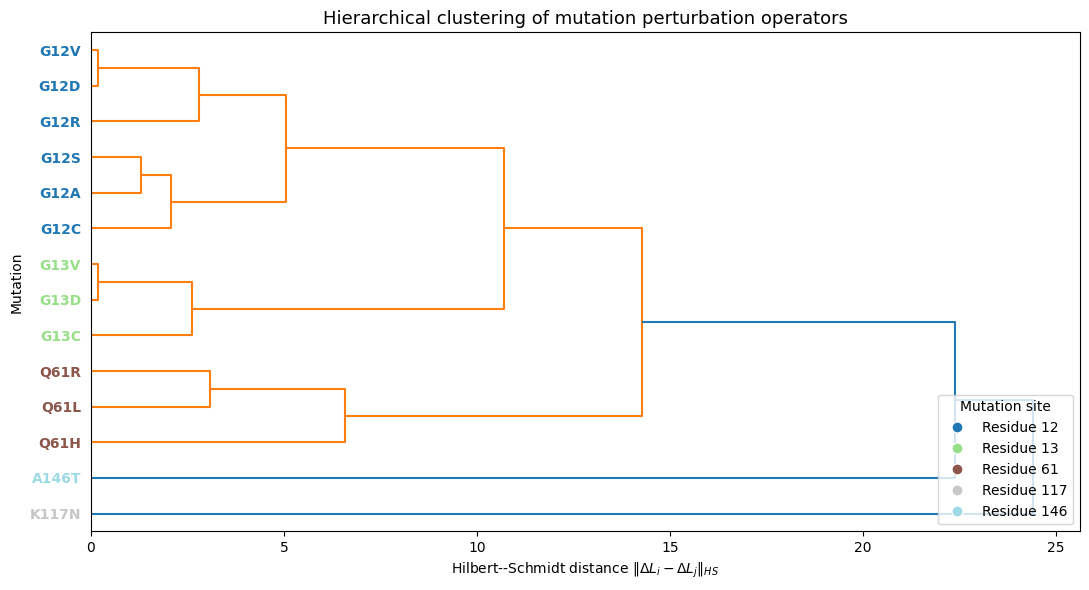

Saved: kras_operator_space_v5_outputs\experiment_8_readable_operator_dendrogram.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 8B: readable horizontal dendrogram of mutation perturbation operators
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, max(6, 0.42 * N_mut)))

dendro = dendrogram(
    Z_D,
    labels=mutation_names,
    orientation='right',
    leaf_font_size=10,
    color_threshold=None,
    ax=ax,
)

ax.set_title('Hierarchical clustering of mutation perturbation operators', fontsize=13)
ax.set_xlabel(r'Hilbert--Schmidt distance $\|\Delta L_i-\Delta L_j\|_{HS}$')
ax.set_ylabel('Mutation')

# Color leaf labels by mutated residue position.
for tick in ax.get_yticklabels():
    label = tick.get_text()
    tick.set_color(mutation_label_colors.get(label, 'black'))
    tick.set_fontweight('bold')

# Add a compact legend for residue positions.
legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', label=f'Residue {site}',
               markerfacecolor=site_to_color[site], markersize=8)
    for site in unique_sites
]
ax.legend(handles=legend_handles, title='Mutation site', loc='lower right', frameon=True)

plt.tight_layout()
out_path = OUTPUT_DIR / 'experiment_8_readable_operator_dendrogram.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


C:\Users\Roberto\AppData\Local\Temp\ipykernel_31680\2245341011.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cluster_cmap = plt.cm.get_cmap('tab10', max(1, len(set(cluster_labels_vis))))


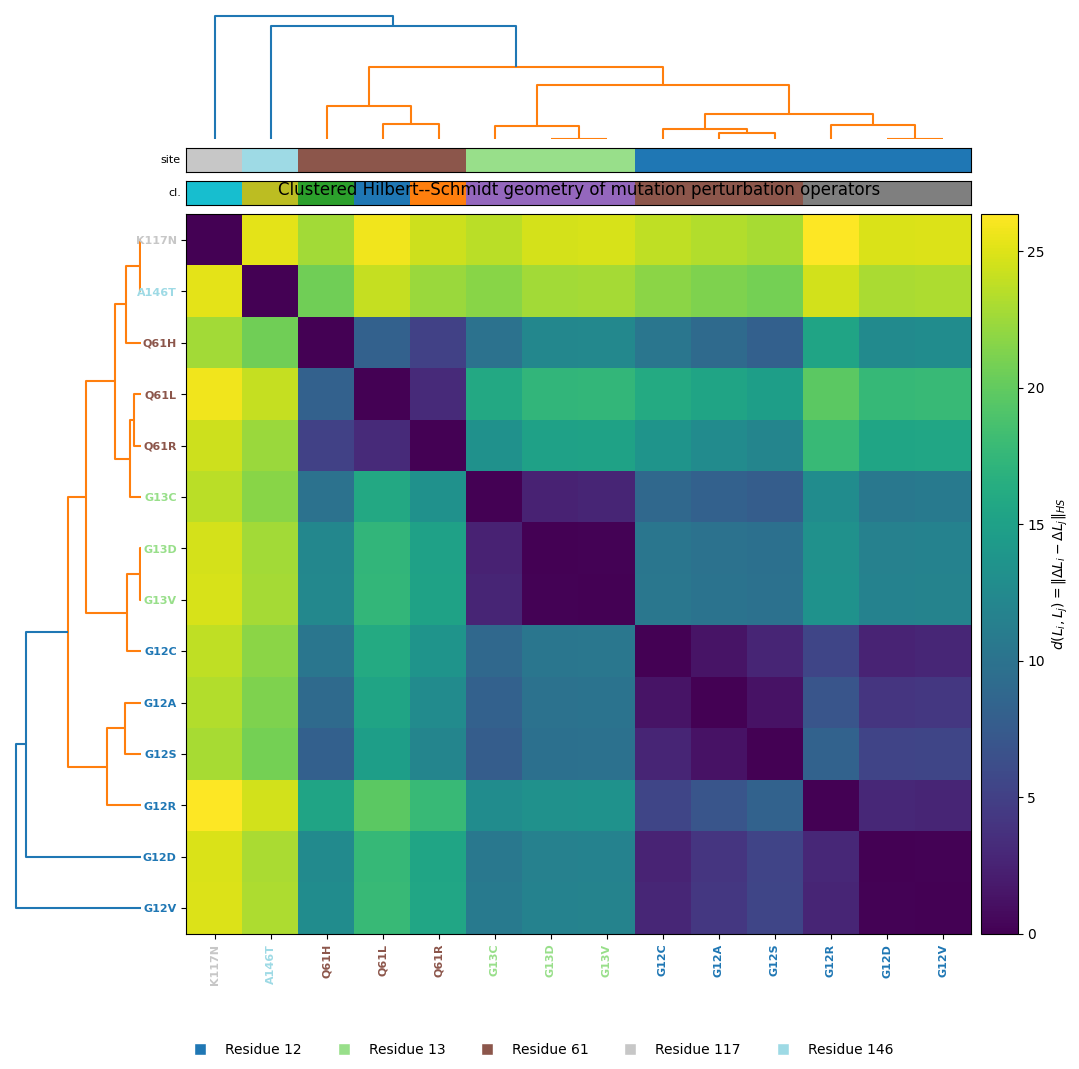

Saved: kras_operator_space_v5_outputs\experiment_8_clustered_heatmap_operator_distance_readable.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 8C: publication-style clustered heatmap for operator distances
# ---------------------------------------------------------------------
def plot_clustered_heatmap(distance_matrix, linkage_matrix, order, title, output_name, cbar_label):
    ordered = distance_matrix[np.ix_(order, order)]
    labels = [mutation_names[i] for i in order]
    ordered_sites = mutation_sites[order]
    ordered_cluster_labels = cluster_labels_vis[order]

    fig = plt.figure(figsize=(13, 12))
    gs = GridSpec(
        4,
        4,
        figure=fig,
        width_ratios=[1.25, 0.25, 7.5, 0.35],
        height_ratios=[1.35, 0.25, 0.25, 7.5],
        wspace=0.04,
        hspace=0.04,
    )

    ax_top = fig.add_subplot(gs[0, 2])
    ax_left = fig.add_subplot(gs[3, 0])
    ax_site = fig.add_subplot(gs[1, 2])
    ax_cluster = fig.add_subplot(gs[2, 2])
    ax_heat = fig.add_subplot(gs[3, 2])
    ax_cbar = fig.add_subplot(gs[3, 3])

    dendrogram(linkage_matrix, ax=ax_top, no_labels=True, color_threshold=None)
    ax_top.axis('off')

    dendrogram(linkage_matrix, ax=ax_left, orientation='left', no_labels=True, color_threshold=None)
    ax_left.axis('off')

    # Residue-site color strip.
    site_rgb = np.array([site_to_color[site] for site in ordered_sites]).reshape(1, len(order), 4)
    ax_site.imshow(site_rgb, aspect='auto')
    ax_site.set_xticks([])
    ax_site.set_yticks([])
    ax_site.set_ylabel('site', rotation=0, ha='right', va='center', fontsize=8)

    # Cluster color strip.
    cluster_cmap = plt.cm.get_cmap('tab10', max(1, len(set(cluster_labels_vis))))
    cluster_rgb = np.array([cluster_cmap(int(c) - 1) for c in ordered_cluster_labels]).reshape(1, len(order), 4)
    ax_cluster.imshow(cluster_rgb, aspect='auto')
    ax_cluster.set_xticks([])
    ax_cluster.set_yticks([])
    ax_cluster.set_ylabel('cl.', rotation=0, ha='right', va='center', fontsize=8)

    im = ax_heat.imshow(ordered, aspect='auto')
    ax_heat.set_title(title, pad=14)
    ax_heat.set_xticks(np.arange(len(order)))
    ax_heat.set_yticks(np.arange(len(order)))
    ax_heat.set_xticklabels(labels, rotation=90, fontsize=8)
    ax_heat.set_yticklabels(labels, fontsize=8)

    for tick in ax_heat.get_xticklabels():
        tick.set_color(mutation_label_colors.get(tick.get_text(), 'black'))
        tick.set_fontweight('bold')
    for tick in ax_heat.get_yticklabels():
        tick.set_color(mutation_label_colors.get(tick.get_text(), 'black'))
        tick.set_fontweight('bold')

    cbar = fig.colorbar(im, cax=ax_cbar)
    cbar.set_label(cbar_label)

    # Residue-site legend below the plot.
    legend_handles = [
        plt.Line2D([0], [0], marker='s', color='w', label=f'Residue {site}',
                   markerfacecolor=site_to_color[site], markersize=8)
        for site in unique_sites
    ]
    fig.legend(handles=legend_handles, loc='lower center', ncol=min(len(unique_sites), 6), frameon=False)

    out_path = OUTPUT_DIR / output_name
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved:', out_path)

plot_clustered_heatmap(
    D_hs,
    Z_D,
    order_D,
    title='Clustered Hilbert--Schmidt geometry of mutation perturbation operators',
    output_name='experiment_8_clustered_heatmap_operator_distance_readable.png',
    cbar_label=r'$d(L_i,L_j)=\|\Delta L_i-\Delta L_j\|_{HS}$',
)


C:\Users\Roberto\AppData\Local\Temp\ipykernel_31680\2245341011.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cluster_cmap = plt.cm.get_cmap('tab10', max(1, len(set(cluster_labels_vis))))


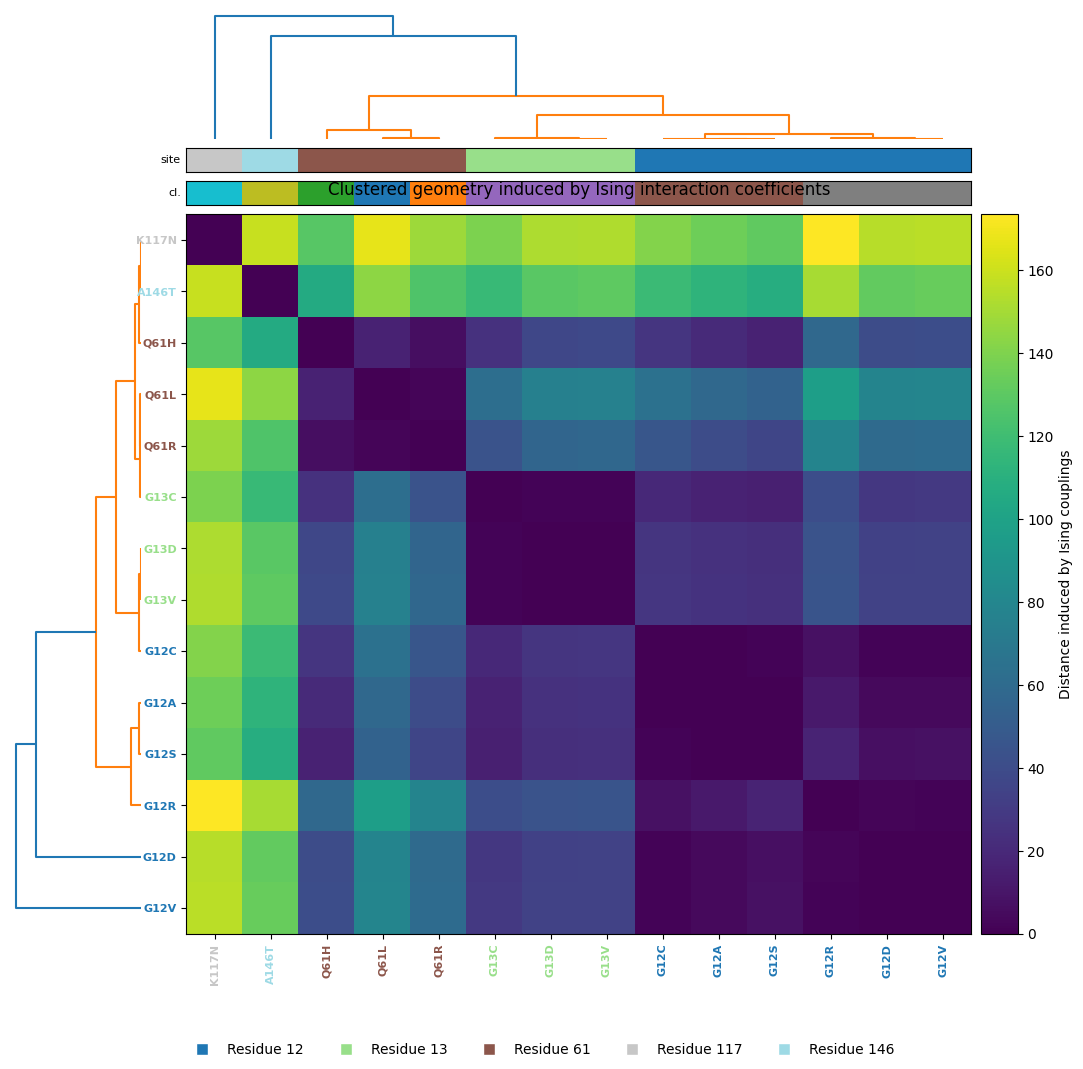

Saved: kras_operator_space_v5_outputs\experiment_8_clustered_heatmap_ising_geometry_readable.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 8D: readable clustering view for the Ising-coupling-induced geometry
# ---------------------------------------------------------------------
if 'D_from_J' in globals() and Z_J is not None:
    # Reuse the same plotting function, now for the distance-like matrix induced by Ising couplings.
    plot_clustered_heatmap(
        D_from_J,
        Z_J,
        order_J,
        title='Clustered geometry induced by Ising interaction coefficients',
        output_name='experiment_8_clustered_heatmap_ising_geometry_readable.png',
        cbar_label='Distance induced by Ising couplings',
    )
else:
    print('D_from_J was not found. Run Experiment 6/7 before this cell.')


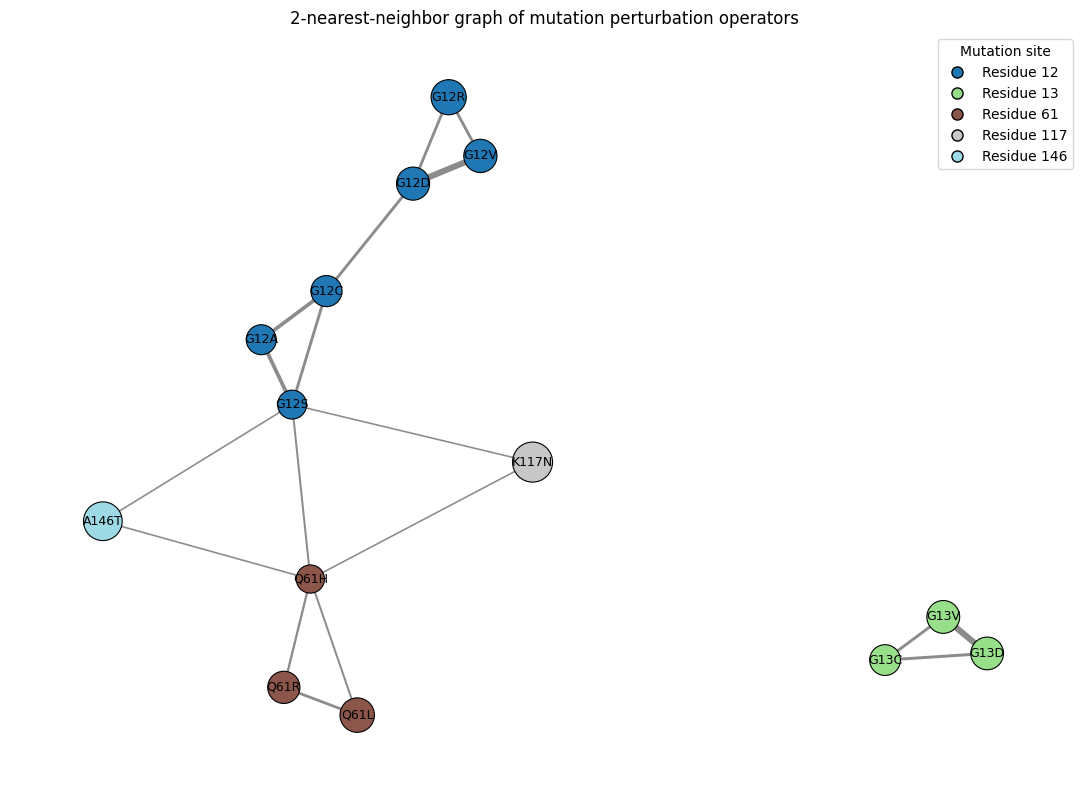

Saved: kras_operator_space_v5_outputs\experiment_8_operator_space_knn_graph.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 8E: nearest-neighbor graph in the mutation operator space
# ---------------------------------------------------------------------
# The dendrogram is useful but can be visually dense. A k-nearest-neighbor graph gives
# a cleaner cluster-level summary of local relationships in the operator space.
K_NEIGHBORS = min(2, max(1, N_mut - 1))

G_knn = nx.Graph()
for i, name in enumerate(mutation_names):
    G_knn.add_node(name, site=int(mutation_sites[i]), cluster=int(cluster_labels_vis[i]), hs_norm=float(np.sqrt(V_vec[i])))

for i in range(N_mut):
    nearest = np.argsort(D_hs[i])[1:K_NEIGHBORS + 1]
    for j in nearest:
        weight = float(D_hs[i, j])
        similarity = 1.0 / (1.0 + weight)
        G_knn.add_edge(mutation_names[i], mutation_names[j], distance=weight, weight=similarity)

pos = nx.spring_layout(G_knn, seed=RANDOM_SEED, weight='weight')
node_colors = [site_to_color[G_knn.nodes[n]['site']] for n in G_knn.nodes()]
node_sizes = [280 + 25 * G_knn.nodes[n]['hs_norm'] for n in G_knn.nodes()]
edge_widths = [1.0 + 4.0 * G_knn[u][v]['weight'] for u, v in G_knn.edges()]

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G_knn, pos, ax=ax, width=edge_widths, alpha=0.45)
nx.draw_networkx_nodes(G_knn, pos, ax=ax, node_color=node_colors, node_size=node_sizes, edgecolors='black', linewidths=0.8)
nx.draw_networkx_labels(G_knn, pos, ax=ax, font_size=9)

ax.set_title(f'{K_NEIGHBORS}-nearest-neighbor graph of mutation perturbation operators')
ax.axis('off')

legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', label=f'Residue {site}',
               markerfacecolor=site_to_color[site], markeredgecolor='black', markersize=8)
    for site in unique_sites
]
ax.legend(handles=legend_handles, title='Mutation site', loc='best', frameon=True)

plt.tight_layout()
out_path = OUTPUT_DIR / 'experiment_8_operator_space_knn_graph.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', out_path)


In [ ]:
# ---------------------------------------------------------------------
# Experiment 8F: cluster summary table for the Results section
# ---------------------------------------------------------------------
cluster_summary_rows = []
for c in sorted(set(cluster_labels_vis)):
    idx = np.where(cluster_labels_vis == c)[0]
    cluster_summary_rows.append({
        'operator_cluster': int(c),
        'n_mutations': int(len(idx)),
        'mutations': ', '.join([mutation_names[i] for i in idx]),
        'mean_hs_norm': float(np.mean(np.sqrt(V_vec[idx]))),
        'mean_pairwise_distance': float(np.mean(D_hs[np.ix_(idx, idx)][np.triu_indices(len(idx), k=1)])) if len(idx) > 1 else 0.0,
    })

operator_cluster_summary_df = pd.DataFrame(cluster_summary_rows)
operator_cluster_summary_df.to_csv(OUTPUT_DIR / 'experiment_8_operator_cluster_summary.csv', index=False)
display(operator_cluster_summary_df)

print('Recommended manuscript figures from Experiment 8:')
print('1) experiment_8_readable_operator_dendrogram.png')
print('2) experiment_8_clustered_heatmap_operator_distance_readable.png')
print('3) experiment_8_clustered_heatmap_ising_geometry_readable.png')
print('4) experiment_8_operator_space_knn_graph.png')


,operator_cluster,n_mutations,mutations,mean_hs_norm,mean_pairwise_distance
0,1,1,Q61L,13.430102,0.000000
1,2,1,Q61R,10.339035,0.000000
2,3,1,Q61H,5.290656,0.000000
3,4,3,"G13D, G13C, G13V",10.199733,1.797307
4,5,3,"G12C, G12A, G12S",7.473296,1.808687
5,6,3,"G12D, G12V, G12R",12.520435,1.937344
6,7,1,A146T,19.898795,0.000000
7,8,1,K117N,22.058964,0.000000


Recommended manuscript figures from Experiment 8:
1) experiment_8_readable_operator_dendrogram.png
2) experiment_8_clustered_heatmap_operator_distance_readable.png
3) experiment_8_clustered_heatmap_ising_geometry_readable.png
4) experiment_8_operator_space_knn_graph.png


## 17. Experiment 9 — Degree-normalized perturbation-energy ablation

In [ ]:

# ---------------------------------------------------------------------
# Experiment 9A: construct degree-normalized perturbation energies
# ---------------------------------------------------------------------
EPS_DEGREE = 1e-12

# Residue degree information from the wild-type RIN.
residue_degree_map = {
    int(row["residue_number"]): float(row["degree"])
    for _, row in residue_table.iterrows()
}
residue_weighted_degree_map = {
    int(row["residue_number"]): float(row["weighted_degree"])
    for _, row in residue_table.iterrows()
}

mutation_sites_ordered = []
mutation_degrees = []
mutation_weighted_degrees = []

for name in mutation_names:
    # Prefer metadata from operator_space_df, fall back to parsing the mutation label.
    if "site" in operator_space_df.columns:
        site = int(operator_space_df.loc[operator_space_df["mutation"] == name, "site"].iloc[0])
    else:
        site = mutation_site(name) if "mutation_site" in globals() else int("".join(ch for ch in name if ch.isdigit()))

    mutation_sites_ordered.append(site)
    mutation_degrees.append(residue_degree_map.get(site, np.nan))
    mutation_weighted_degrees.append(residue_weighted_degree_map.get(site, np.nan))

mutation_degrees = np.asarray(mutation_degrees, dtype=float)
mutation_weighted_degrees = np.asarray(mutation_weighted_degrees, dtype=float)

# Normalized alternatives. Weighted degree is the primary version because the RIN is weighted.
V_degree_normalized = V_vec / np.maximum(mutation_degrees, EPS_DEGREE)
V_weighted_degree_normalized = V_vec / np.maximum(mutation_weighted_degrees, EPS_DEGREE)

normalized_energy_df = pd.DataFrame({
    "mutation": mutation_names,
    "site": mutation_sites_ordered,
    "V_original": V_vec,
    "hs_norm": np.sqrt(V_vec),
    "degree": mutation_degrees,
    "weighted_degree": mutation_weighted_degrees,
    "V_degree_normalized": V_degree_normalized,
    "V_weighted_degree_normalized": V_weighted_degree_normalized,
})

normalized_energy_df.to_csv(OUTPUT_DIR / "experiment_9_degree_normalized_energies.csv", index=False)
display(normalized_energy_df.sort_values("V_weighted_degree_normalized", ascending=False))

print("Saved:", OUTPUT_DIR / "experiment_9_degree_normalized_energies.csv")


,mutation,site,V_original,hs_norm,degree,weighted_degree,V_degree_normalized,V_weighted_degree_normalized
5,G12R,12,207.269593,14.396861,4.0,19.842582,51.817398,10.445696
12,K117N,117,486.597913,22.058964,9.0,48.380297,54.066435,10.057770
10,Q61L,61,180.367635,13.430102,4.0,21.154934,45.091909,8.526032
1,G12V,12,136.272940,11.673600,4.0,19.842582,34.068235,6.867702
0,G12D,12,132.039525,11.490845,4.0,19.842582,33.009881,6.654352
8,G13V,13,124.469871,11.156607,4.0,19.374979,31.117468,6.424258
13,A146T,146,395.962046,19.898795,11.0,61.933582,35.996550,6.393334
6,G13D,13,120.603126,10.981945,4.0,19.374979,30.150782,6.224684
11,Q61R,61,106.895648,10.339035,4.0,21.154934,26.723912,5.052989
2,G12C,12,78.370481,8.852710,4.0,19.842582,19.592620,3.949611


Saved: kras_operator_space_v5_outputs\experiment_9_degree_normalized_energies.csv


In [ ]:
# ---------------------------------------------------------------------
# Experiment 9B: repeat Experiment 2 with normalized perturbation energies
# ---------------------------------------------------------------------
def run_variational_selection_table(V_input: np.ndarray, label: str) -> pd.DataFrame:
    rows = []
    for k in k_values:
        exact = exact_variational_selection(k, V_input, D_sq, MU)
        top = top_energy_baseline(k, V_input, D_sq, MU)
        rnd = random_baseline(k, V_input, D_sq, MU, N_RANDOM_BASELINE)

        rows.append({
            "energy_model": label,
            "k": k,
            "method": "variational_exact",
            "selected": ", ".join(exact["selected"]),
            "V": exact["V"],
            "D": exact["D"],
            "J": exact["J"],
        })
        rows.append({
            "energy_model": label,
            "k": k,
            "method": "top_perturbation_energy",
            "selected": ", ".join(top["selected"]),
            "V": top["V"],
            "D": top["D"],
            "J": top["J"],
        })
        rows.append({
            "energy_model": label,
            "k": k,
            "method": "random_mean",
            "selected": "random subsets",
            "V": rnd["V_mean"],
            "D": rnd["D_mean"],
            "J": rnd["J_mean"],
            "V_std": rnd["V_std"],
            "D_std": rnd["D_std"],
            "J_std": rnd["J_std"],
        })

    return pd.DataFrame(rows)

experiment_9_original_df = run_variational_selection_table(V_vec, "original_total_perturbation")
experiment_9_degree_df = run_variational_selection_table(V_degree_normalized, "degree_normalized")
experiment_9_weighted_df = run_variational_selection_table(V_weighted_degree_normalized, "weighted_degree_normalized")

experiment_9_df = pd.concat(
    [experiment_9_original_df, experiment_9_degree_df, experiment_9_weighted_df],
    ignore_index=True,
)
experiment_9_df.to_csv(OUTPUT_DIR / "experiment_9_normalized_V_selection_results.csv", index=False)

display(experiment_9_df)
print("Saved:", OUTPUT_DIR / "experiment_9_normalized_V_selection_results.csv")


,energy_model,k,method,selected,V,D,J,V_std,D_std,J_std
0,original_total_perturbation,4,variational_exact,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
1,original_total_perturbation,4,top_perturbation_energy,"G12R, Q61L, K117N, A146T",1270.197187,3563.718167,-4833.915354,NaN,NaN,NaN
2,original_total_perturbation,4,random_mean,random subsets,617.829325,1446.336043,-2064.165368,228.385208,800.226776,1019.202942
3,original_total_perturbation,5,variational_exact,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,NaN,NaN,NaN
4,original_total_perturbation,5,top_perturbation_energy,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,NaN,NaN,NaN
5,original_total_perturbation,5,random_mean,random subsets,782.681122,2464.140017,-3246.821139,244.176041,1110.472630,1346.020354
6,original_total_perturbation,6,variational_exact,"G12R, G13V, Q61L, Q61R, K117N, A146T",1501.562706,6831.761863,-8333.324568,NaN,NaN,NaN
7,original_total_perturbation,6,top_perturbation_energy,"G12D, G12V, G12R, Q61L, K117N, A146T",1538.509652,6510.405222,-8048.914874,NaN,NaN,NaN
8,original_total_perturbation,6,random_mean,random subsets,935.434201,3681.943778,-4617.377978,246.044177,1402.282311,1639.518803
9,degree_normalized,4,variational_exact,"G12R, Q61L, K117N, A146T",186.972291,3563.718167,-3750.690458,NaN,NaN,NaN


Saved: kras_operator_space_v5_outputs\experiment_9_normalized_V_selection_results.csv


,energy_model,method,k,selected,sites,mean_degree,mean_weighted_degree,V_model,D,J,V_original_total_of_selected
0,original_total_perturbation,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T","12, 13, 61, 117, 146",6.4,34.137275,1394.667058,5180.325154,-6574.992212,1394.667058
1,original_total_perturbation,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T","12, 12, 61, 117, 146",6.4,34.230795,1406.470127,5042.880729,-6449.350856,1406.470127
2,degree_normalized,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T","12, 13, 61, 117, 146",6.4,34.137275,218.089759,5180.325154,-5398.414913,1394.667058
3,degree_normalized,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T","12, 12, 61, 117, 146",6.4,34.230795,221.040526,5042.880729,-5263.921256,1406.470127
4,weighted_degree_normalized,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T","12, 13, 61, 117, 146",6.4,34.137275,41.847090,5180.325154,-5222.172245,1394.667058
5,weighted_degree_normalized,top_perturbation_energy,5,"G12D, G12V, G12R, Q61L, K117N","12, 12, 12, 61, 117",5.0,25.812595,42.551552,3634.920779,-3677.472331,1142.547606


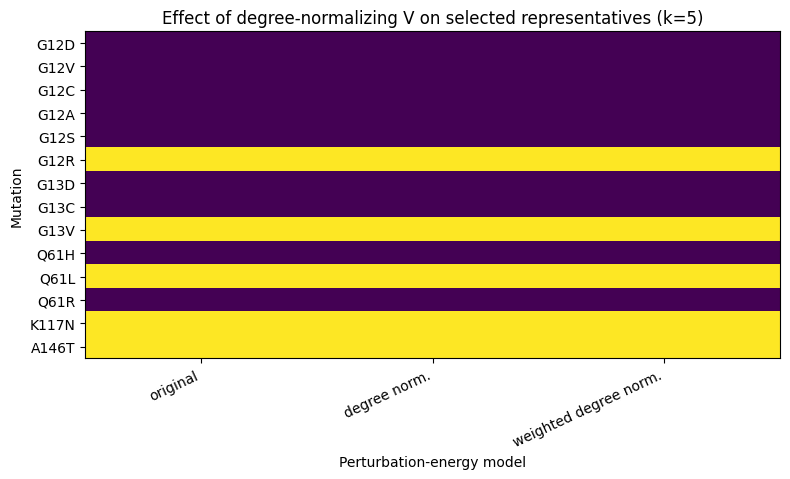

Saved: kras_operator_space_v5_outputs\experiment_9_selection_indicator_normalized_V.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 9C: compare selected subsets under original and normalized V
# ---------------------------------------------------------------------
# Focus on the same k used for quantum optimization if available, otherwise use a robust default.
k_norm_plot = K_QOPT if "K_QOPT" in globals() else min(4, N_mut)

comparison_rows = []
for energy_label, V_input in [
    ("original_total_perturbation", V_vec),
    ("degree_normalized", V_degree_normalized),
    ("weighted_degree_normalized", V_weighted_degree_normalized),
]:
    exact = exact_variational_selection(k_norm_plot, V_input, D_sq, MU)
    top = top_energy_baseline(k_norm_plot, V_input, D_sq, MU)

    for method_label, result in [
        ("variational_exact", exact),
        ("top_perturbation_energy", top),
    ]:
        selected_idx = np.where(result["mask"] == 1)[0]
        comparison_rows.append({
            "energy_model": energy_label,
            "method": method_label,
            "k": k_norm_plot,
            "selected": ", ".join(result["selected"]),
            "sites": ", ".join(map(str, [mutation_sites_ordered[i] for i in selected_idx])),
            "mean_degree": float(np.mean(mutation_degrees[selected_idx])),
            "mean_weighted_degree": float(np.mean(mutation_weighted_degrees[selected_idx])),
            "V_model": result["V"],
            "D": result["D"],
            "J": result["J"],
            "V_original_total_of_selected": float(np.sum(V_vec[selected_idx])),
        })

experiment_9_comparison_df = pd.DataFrame(comparison_rows)
experiment_9_comparison_df.to_csv(OUTPUT_DIR / "experiment_9_selected_subsets_comparison.csv", index=False)
display(experiment_9_comparison_df)

# Bar chart: which mutations are selected under each energy model.
plot_rows = []
for _, row in experiment_9_comparison_df.iterrows():
    if row["method"] != "variational_exact":
        continue
    selected_names = [s.strip() for s in row["selected"].split(",") if s.strip()]
    for name in selected_names:
        plot_rows.append({"energy_model": row["energy_model"], "mutation": name, "selected": 1})

selection_indicator_df = pd.DataFrame(plot_rows)
models = ["original_total_perturbation", "degree_normalized", "weighted_degree_normalized"]
indicator = pd.DataFrame(0, index=mutation_names, columns=models)
for _, row in selection_indicator_df.iterrows():
    indicator.loc[row["mutation"], row["energy_model"]] = 1

plt.figure(figsize=(8, max(4, 0.35 * N_mut)))
plt.imshow(indicator.values, aspect="auto")
plt.yticks(np.arange(N_mut), mutation_names)
plt.xticks(np.arange(len(models)), ["original", "degree norm.", "weighted degree norm."], rotation=25, ha="right")
plt.xlabel("Perturbation-energy model")
plt.ylabel("Mutation")
plt.title(f"Effect of degree-normalizing V on selected representatives (k={k_norm_plot})")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_9_selection_indicator_normalized_V.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


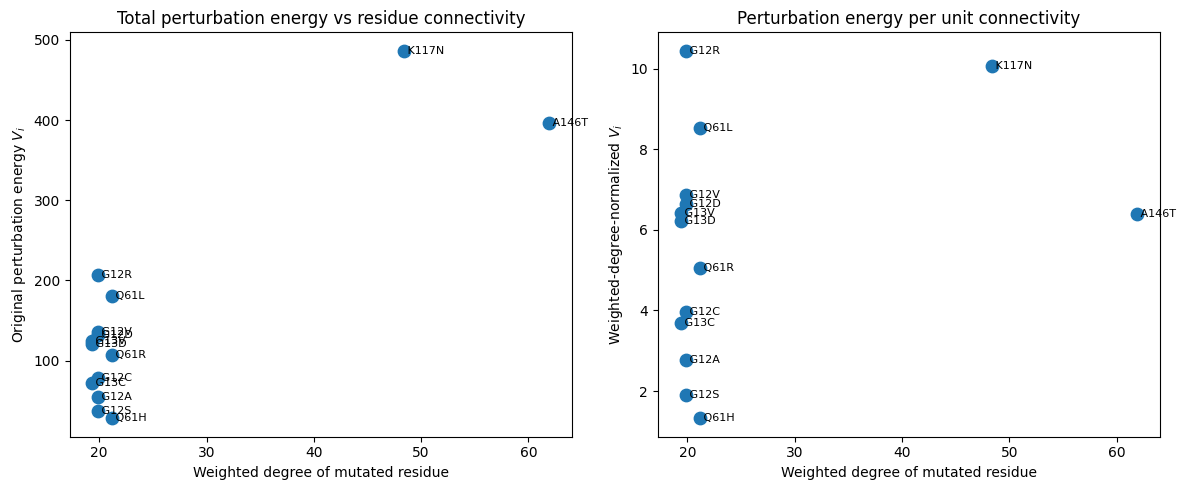

Saved: kras_operator_space_v5_outputs\experiment_9_V_vs_connectivity_ablation.png
Spearman(weighted degree, original V) = 0.364924
Spearman(weighted degree, weighted-normalized V) = 0.161675


In [ ]:
# ---------------------------------------------------------------------
# Experiment 9D: V versus residue connectivity
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(mutation_weighted_degrees, V_vec, s=80)
for i, name in enumerate(mutation_names):
    axes[0].text(mutation_weighted_degrees[i], V_vec[i], f" {name}", fontsize=8, va="center")
axes[0].set_xlabel("Weighted degree of mutated residue")
axes[0].set_ylabel(r"Original perturbation energy $V_i$")
axes[0].set_title("Total perturbation energy vs residue connectivity")

axes[1].scatter(mutation_weighted_degrees, V_weighted_degree_normalized, s=80)
for i, name in enumerate(mutation_names):
    axes[1].text(mutation_weighted_degrees[i], V_weighted_degree_normalized[i], f" {name}", fontsize=8, va="center")
axes[1].set_xlabel("Weighted degree of mutated residue")
axes[1].set_ylabel(r"Weighted-degree-normalized $V_i$")
axes[1].set_title("Perturbation energy per unit connectivity")

plt.tight_layout()
out_path = OUTPUT_DIR / "experiment_9_V_vs_connectivity_ablation.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

if len(mutation_weighted_degrees) > 1:
    corr_orig = spearmanr(mutation_weighted_degrees, V_vec).correlation
    corr_norm = spearmanr(mutation_weighted_degrees, V_weighted_degree_normalized).correlation
    print(f"Spearman(weighted degree, original V) = {corr_orig:.6f}")
    print(f"Spearman(weighted degree, weighted-normalized V) = {corr_norm:.6f}")


## 18. Additional manuscript figures — geometry, Hamiltonian and robustness

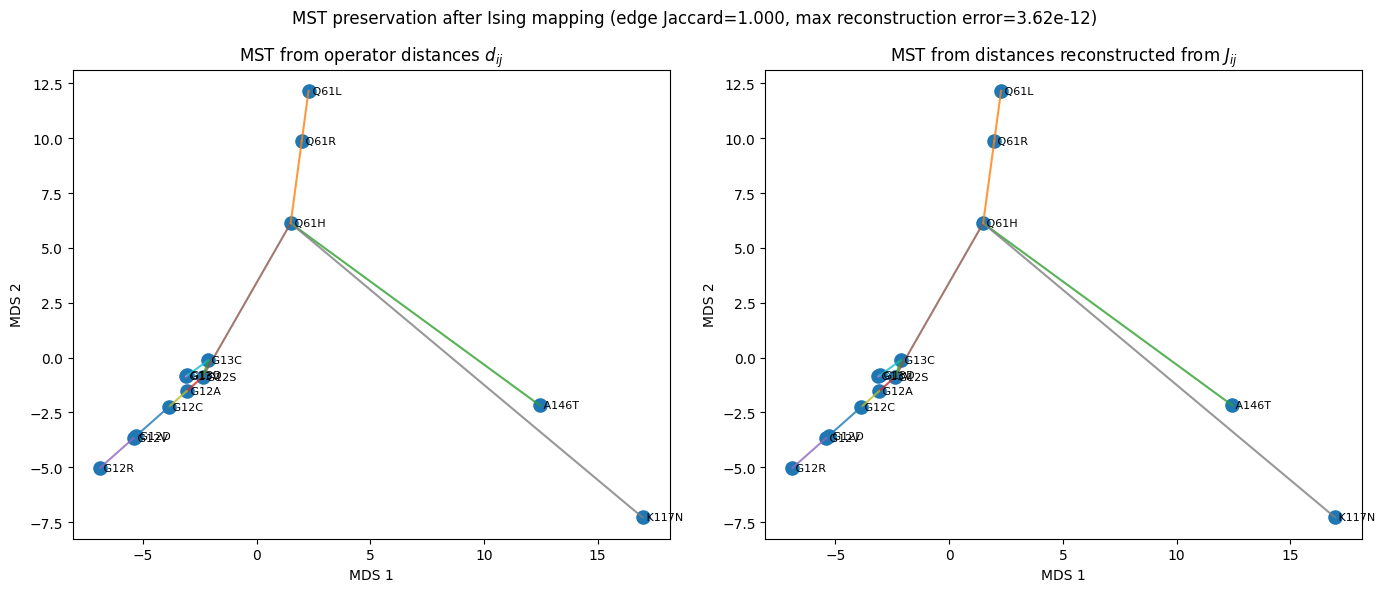

,metric,value
0,mst_edge_jaccard,1.000000e+00
1,n_edges_D,1.300000e+01
2,n_edges_J_reconstructed,1.300000e+01
3,n_common_edges,1.300000e+01
4,max_abs_error_Dsq_reconstruction,3.623768e-12
5,relative_error_Dsq_reconstruction,5.222565e-15


Saved: kras_operator_space_v5_outputs\experiment_10_mst_operator_vs_ising_reconstructed.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10A: MST(D) versus MST(J-reconstructed geometry)
# ---------------------------------------------------------------------
from scipy.sparse.csgraph import minimum_spanning_tree

# Use the same Hamiltonian coefficients already constructed for the geometry-preservation experiment.
K_GEOM_HAM = K_QOPT if "K_QOPT" in globals() else K_MAIN
LAMBDA_GEOM_HAM = LAMBDA_QOPT if "LAMBDA_QOPT" in globals() else 1.05 * penalty_bound_B(V_vec, D_sq, MU)

if "J_couplings" not in globals():
    A_geom_ham = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_GEOM_HAM, K_GEOM_HAM)
    ising_geom_coeffs = ising_coefficients_from_A(A_geom_ham, LAMBDA_GEOM_HAM, K_GEOM_HAM)
    J_couplings = ising_geom_coeffs["J"]

# The Ising couplings satisfy
#     J_ij = lambda/2 - mu/4 D_ij^2.
# Therefore the squared operator distances can be reconstructed from the
# Hamiltonian couplings as
#     D_ij^2 = (4/mu)(lambda/2 - J_ij).
# This is the correct distance-like object to compare against the operator geometry.
if MU <= 0:
    raise ValueError("MU must be positive to reconstruct distances from Ising couplings.")

D_sq_from_J = (4.0 / MU) * (LAMBDA_GEOM_HAM / 2.0 - J_couplings)
np.fill_diagonal(D_sq_from_J, 0.0)
D_sq_from_J = np.maximum(D_sq_from_J, 0.0)
D_from_J_hs = np.sqrt(D_sq_from_J)

D_for_mst = D_hs.copy()
np.fill_diagonal(D_for_mst, 0.0)

mst_D_sparse = minimum_spanning_tree(D_for_mst).toarray()
mst_J_sparse = minimum_spanning_tree(D_from_J_hs).toarray()

mst_D_edges = {
    tuple(sorted((i, j)))
    for i, j in zip(*np.where(mst_D_sparse > 0))
}
mst_J_edges = {
    tuple(sorted((i, j)))
    for i, j in zip(*np.where(mst_J_sparse > 0))
}

mst_jaccard = (
    len(mst_D_edges & mst_J_edges) / len(mst_D_edges | mst_J_edges)
    if len(mst_D_edges | mst_J_edges) > 0 else np.nan
)

reconstruction_max_abs_error = float(np.max(np.abs(D_sq - D_sq_from_J)))
reconstruction_rel_error = reconstruction_max_abs_error / max(float(np.max(np.abs(D_sq))), 1e-12)

def draw_mst(ax, edge_set, title):
    ax.scatter(mds_coords[:, 0], mds_coords[:, 1], s=90)
    for i, name in enumerate(mutation_names):
        ax.text(mds_coords[i, 0], mds_coords[i, 1], f" {name}", fontsize=8, va="center")
    for i, j in edge_set:
        ax.plot(
            [mds_coords[i, 0], mds_coords[j, 0]],
            [mds_coords[i, 1], mds_coords[j, 1]],
            linewidth=1.5,
            alpha=0.8,
        )
    ax.set_title(title)
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
draw_mst(axes[0], mst_D_edges, r"MST from operator distances $d_{ij}$")
draw_mst(axes[1], mst_J_edges, r"MST from distances reconstructed from $J_{ij}$")
fig.suptitle(
    f"MST preservation after Ising mapping "
    f"(edge Jaccard={mst_jaccard:.3f}, max reconstruction error={reconstruction_max_abs_error:.2e})"
)
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mst_operator_vs_ising_reconstructed.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

mst_summary_df = pd.DataFrame({
    "metric": [
        "mst_edge_jaccard",
        "n_edges_D",
        "n_edges_J_reconstructed",
        "n_common_edges",
        "max_abs_error_Dsq_reconstruction",
        "relative_error_Dsq_reconstruction",
    ],
    "value": [
        mst_jaccard,
        len(mst_D_edges),
        len(mst_J_edges),
        len(mst_D_edges & mst_J_edges),
        reconstruction_max_abs_error,
        reconstruction_rel_error,
    ],
})
mst_summary_df.to_csv(OUTPUT_DIR / "experiment_10_mst_summary.csv", index=False)
display(mst_summary_df)
print("Saved:", out_path)


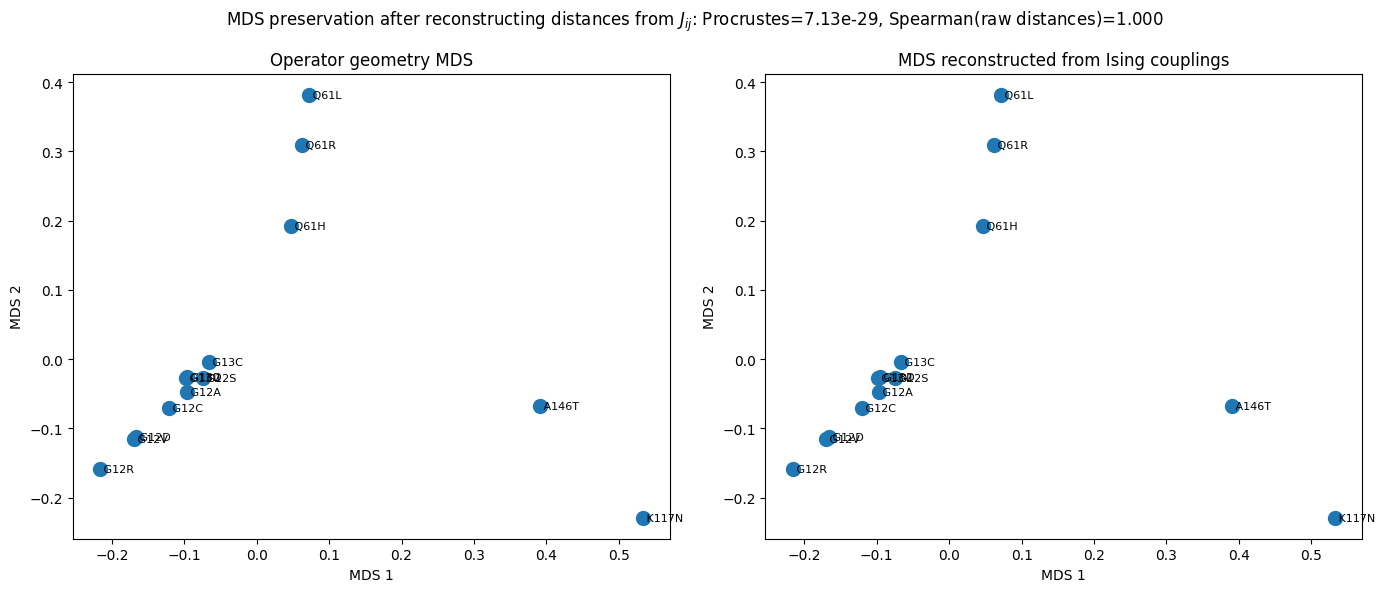

,metric,value
0,procrustes_disparity,7.125234e-29
1,pearson_embedding_distances,1.000000e+00
2,spearman_embedding_distances,1.000000e+00
3,pearson_raw_distances,1.000000e+00
4,spearman_raw_distances,1.000000e+00
5,max_abs_error_Dsq_reconstruction,3.623768e-12


Saved: kras_operator_space_v5_outputs\experiment_10_mds_operator_vs_ising_reconstructed.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10B: MDS(D) versus MDS(distance reconstructed from J)
# ---------------------------------------------------------------------
from scipy.spatial import procrustes
from scipy.stats import pearsonr, spearmanr
try:
    from sklearn.metrics import pairwise_distances
except Exception:
    pairwise_distances = None

# Use the true Hilbert--Schmidt distance reconstructed from the Hamiltonian couplings.
# This avoids treating J_ij itself as a distance, which would be conceptually incorrect.
D_from_J = D_from_J_hs.copy()

# Classical MDS is deterministic here and avoids extra dependencies.
coords_D_classical = classical_mds(D_hs, n_components=2)
coords_J_classical = classical_mds(D_from_J, n_components=2)

# Procrustes alignment quantifies whether both embeddings encode the same geometry.
mtx_D, mtx_J, procrustes_disparity = procrustes(coords_D_classical, coords_J_classical)

# Compare pairwise distances in both embeddings.
if pairwise_distances is not None:
    emb_D_dist = pairwise_distances(mtx_D)
    emb_J_dist = pairwise_distances(mtx_J)
else:
    emb_D_dist = squareform(pdist(mtx_D))
    emb_J_dist = squareform(pdist(mtx_J))

upper = np.triu_indices(N_mut, k=1)
pearson_emb = pearsonr(emb_D_dist[upper], emb_J_dist[upper]).statistic
spearman_emb = spearmanr(emb_D_dist[upper], emb_J_dist[upper]).correlation
pearson_raw = pearsonr(D_hs[upper], D_from_J[upper]).statistic
spearman_raw = spearmanr(D_hs[upper], D_from_J[upper]).correlation

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, coords_plot, title in [
    (axes[0], mtx_D, "Operator geometry MDS"),
    (axes[1], mtx_J, "MDS reconstructed from Ising couplings"),
]:
    ax.scatter(coords_plot[:, 0], coords_plot[:, 1], s=100)
    for i, name in enumerate(mutation_names):
        ax.text(coords_plot[i, 0], coords_plot[i, 1], f" {name}", fontsize=8, va="center")
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")
    ax.set_title(title)

fig.suptitle(
    f"MDS preservation after reconstructing distances from $J_{{ij}}$: "
    f"Procrustes={procrustes_disparity:.2e}, Spearman(raw distances)={spearman_raw:.3f}"
)
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mds_operator_vs_ising_reconstructed.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

mds_preservation_df = pd.DataFrame({
    "metric": [
        "procrustes_disparity",
        "pearson_embedding_distances",
        "spearman_embedding_distances",
        "pearson_raw_distances",
        "spearman_raw_distances",
        "max_abs_error_Dsq_reconstruction",
    ],
    "value": [
        procrustes_disparity,
        pearson_emb,
        spearman_emb,
        pearson_raw,
        spearman_raw,
        reconstruction_max_abs_error,
    ],
})
mds_preservation_df.to_csv(OUTPUT_DIR / "experiment_10_mds_preservation_summary.csv", index=False)
display(mds_preservation_df)
print("Saved:", out_path)


,method,k,V,D,J,selected
0,variational_exact,5,1394.667058,5180.325154,-6574.992212,"G12R, G13V, Q61L, K117N, A146T"
1,top_perturbation_energy,5,1406.470127,5042.880729,-6449.350856,"G12V, G12R, Q61L, K117N, A146T"
2,random_mean,5,775.363743,2452.063499,-3227.427242,random subsets
3,simulated_annealing,5,1394.667058,5180.325154,-6574.992212,"G12R, G13V, Q61L, K117N, A146T"


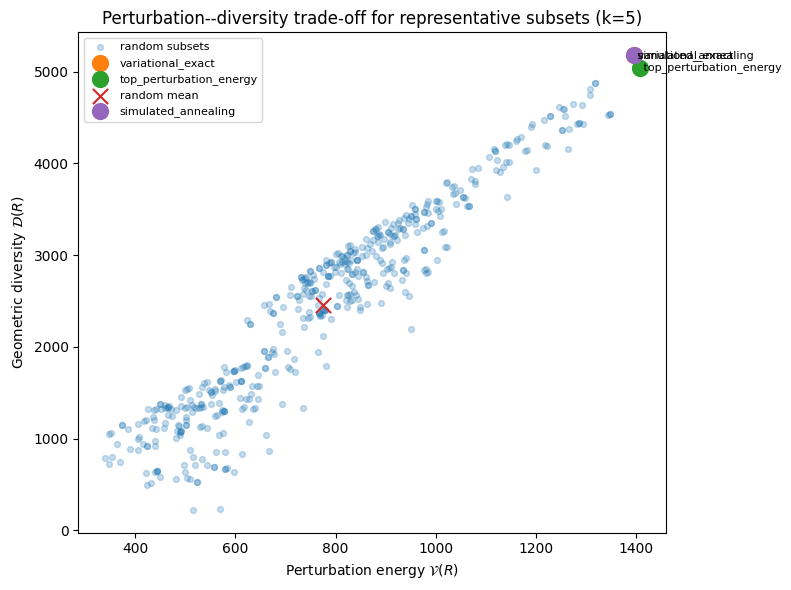

Saved: kras_operator_space_v5_outputs\experiment_10_pareto_V_D_tradeoff_k_main.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10C: Pareto-style perturbation--diversity trade-off
# ---------------------------------------------------------------------
# Compare deterministic and stochastic methods at the main showcase cardinality k=5.
K_PARETO = K_MAIN

pareto_rows = []

# Exact variational and top-energy baselines.
exact_main = exact_variational_selection(K_PARETO, V_vec, D_sq, MU)
top_main = top_energy_baseline(K_PARETO, V_vec, D_sq, MU)
for method_label, result in [
    ("variational_exact", exact_main),
    ("top_perturbation_energy", top_main),
]:
    pareto_rows.append({
        "method": method_label,
        "k": K_PARETO,
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selected": ", ".join(result["selected"]),
    })

# Random baseline cloud.
rng = np.random.default_rng(RANDOM_SEED + 1000 + K_PARETO)
random_points = []
for _ in range(500):
    idx = tuple(rng.choice(N_mut, size=K_PARETO, replace=False))
    mask = mask_from_indices(idx, N_mut)
    vals = variational_components(mask, V_vec, D_sq, MU)
    random_points.append(vals)

random_df = pd.DataFrame(random_points)
pareto_rows.append({
    "method": "random_mean",
    "k": K_PARETO,
    "V": float(random_df["V"].mean()),
    "D": float(random_df["D"].mean()),
    "J": float(random_df["J"].mean()),
    "selected": "random subsets",
})

# Simulated annealing result if available and generated for the same k.
if "sa_result" in globals() and int(sa_result.get("cardinality", -1)) == K_PARETO:
    sa_mask = sa_result["mask"]
    sa_vals = variational_components(sa_mask, V_vec, D_sq, MU)
    pareto_rows.append({
        "method": "simulated_annealing",
        "k": K_PARETO,
        "V": sa_vals["V"],
        "D": sa_vals["D"],
        "J": sa_vals["J"],
        "selected": ", ".join(names_from_mask(sa_mask)),
    })

# QAOA best sampled result if available and generated for the same k.
if "qaoa_df" in globals() and len(qaoa_df) > 0:
    qdf = qaoa_df.copy()
    if "best_bitstring" in qdf.columns:
        # Pick lowest best energy row.
        best_row = qdf.sort_values("best_energy").iloc[0]
        bitstring = best_row["best_bitstring"]
        if isinstance(bitstring, str):
            qaoa_mask = np.array([int(ch) for ch in bitstring], dtype=int)
        else:
            qaoa_mask = np.array(bitstring, dtype=int)
        if int(qaoa_mask.sum()) == K_PARETO:
            qaoa_vals = variational_components(qaoa_mask, V_vec, D_sq, MU)
            pareto_rows.append({
                "method": "qaoa_best_sampled",
                "k": K_PARETO,
                "V": qaoa_vals["V"],
                "D": qaoa_vals["D"],
                "J": qaoa_vals["J"],
                "selected": ", ".join(names_from_mask(qaoa_mask)),
            })

pareto_summary_df = pd.DataFrame(pareto_rows)
pareto_summary_df.to_csv(OUTPUT_DIR / "experiment_10_pareto_summary_k_main.csv", index=False)
display(pareto_summary_df)

plt.figure(figsize=(8, 6))
# Random cloud
plt.scatter(random_df["V"], random_df["D"], s=18, alpha=0.25, label="random subsets")
# Deterministic / algorithmic points
for _, row in pareto_summary_df.iterrows():
    if row["method"] == "random_mean":
        plt.scatter(row["V"], row["D"], s=120, marker="x", label="random mean")
    else:
        plt.scatter(row["V"], row["D"], s=130, label=row["method"])
        plt.text(row["V"], row["D"], f" {row['method']}", fontsize=8, va="center")

plt.xlabel(r"Perturbation energy $\mathcal{V}(R)$")
plt.ylabel(r"Geometric diversity $\mathcal{D}(R)$")
plt.title(f"Perturbation--diversity trade-off for representative subsets (k={K_PARETO})")
plt.legend(fontsize=8)
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_pareto_V_D_tradeoff_k_main.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


,mu,k,selected,V,D,J,selection_changed
0,0.00,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1406.470127,True
1,0.05,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1658.614164,False
2,0.10,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-1912.699573,True
3,0.25,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-2689.748346,False
4,0.50,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-3984.829635,False
5,1.00,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,False
6,2.00,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-11755.317366,False
7,5.00,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-27296.292828,False


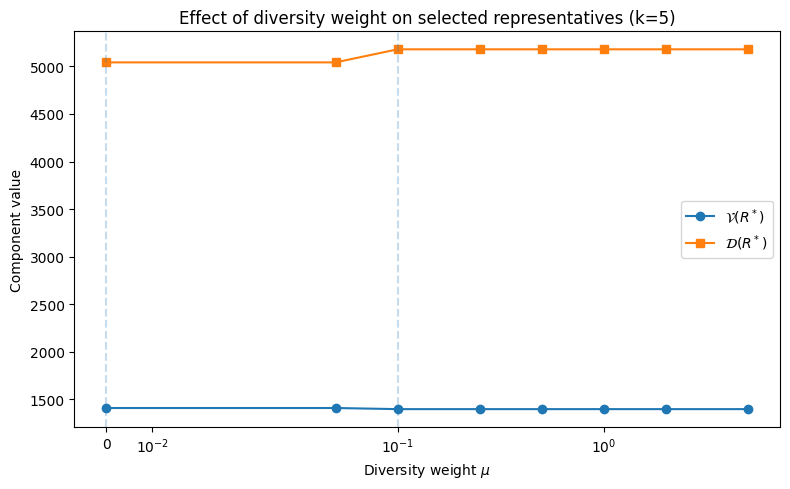

Saved: kras_operator_space_v5_outputs\experiment_10_mu_evolution_components_k_main.png


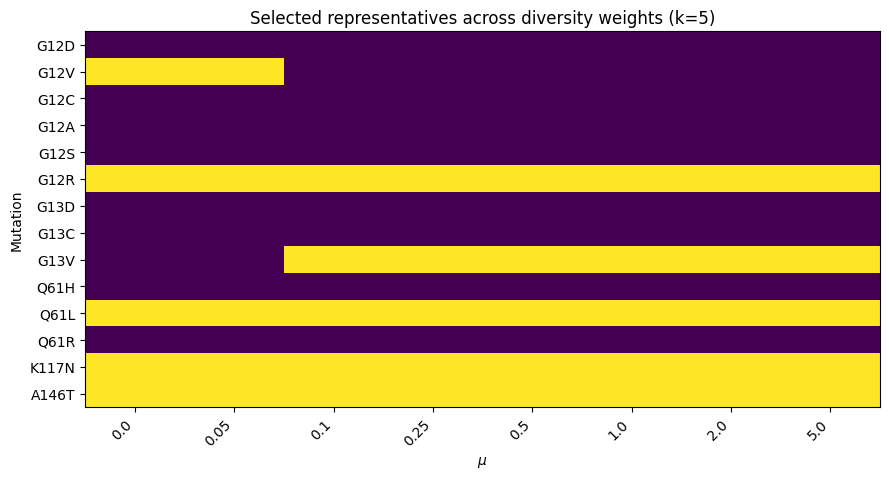

Saved: kras_operator_space_v5_outputs\experiment_10_mu_selection_matrix_k_main.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10D: evolution with the diversity parameter mu
# ---------------------------------------------------------------------
MU_GRID = np.array([0.0, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0], dtype=float)
K_MU = K_MAIN

mu_rows = []
prev_selection = None
for mu_value in MU_GRID:
    result = exact_variational_selection(K_MU, V_vec, D_sq, mu_value)
    selection_tuple = tuple(result["selected"])
    changed = selection_tuple != prev_selection
    prev_selection = selection_tuple

    mu_rows.append({
        "mu": mu_value,
        "k": K_MU,
        "selected": ", ".join(result["selected"]),
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selection_changed": changed,
    })

mu_sensitivity_df = pd.DataFrame(mu_rows)
mu_sensitivity_df.to_csv(OUTPUT_DIR / "experiment_10_mu_evolution_k_main.csv", index=False)
display(mu_sensitivity_df)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(mu_sensitivity_df["mu"], mu_sensitivity_df["V"], marker="o", label=r"$\mathcal{V}(R^*)$")
ax1.plot(mu_sensitivity_df["mu"], mu_sensitivity_df["D"], marker="s", label=r"$\mathcal{D}(R^*)$")
ax1.set_xscale("symlog", linthresh=0.05)
ax1.set_xlabel(r"Diversity weight $\mu$")
ax1.set_ylabel("Component value")
ax1.set_title(f"Effect of diversity weight on selected representatives (k={K_MU})")
for _, row in mu_sensitivity_df.iterrows():
    if row["selection_changed"]:
        ax1.axvline(row["mu"], linestyle="--", alpha=0.25)
ax1.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mu_evolution_components_k_main.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

# Compact mutation-selection matrix across mu values.
selection_matrix_mu = pd.DataFrame(0, index=mutation_names, columns=[str(mu) for mu in MU_GRID])
for _, row in mu_sensitivity_df.iterrows():
    selected_names = [s.strip() for s in row["selected"].split(",") if s.strip()]
    for name in selected_names:
        selection_matrix_mu.loc[name, str(row["mu"])] = 1

plt.figure(figsize=(9, max(4, 0.35 * N_mut)))
plt.imshow(selection_matrix_mu.values, aspect="auto")
plt.yticks(np.arange(N_mut), mutation_names)
plt.xticks(np.arange(len(MU_GRID)), [str(mu) for mu in MU_GRID], rotation=45, ha="right")
plt.xlabel(r"$\mu$")
plt.ylabel("Mutation")
plt.title(f"Selected representatives across diversity weights (k={K_MU})")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_mu_selection_matrix_k_main.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


,quantity_pair,pearson,spearman
0,squared_operator_distance_vs_Ising_coupling,-1.000000,-1.000000
1,squared_operator_distance_vs_reconstructed_dis...,1.000000,1.000000
2,operator_distance_vs_reconstructed_operator_di...,1.000000,1.000000
3,weighted_degree_vs_original_V,0.867222,0.364924
4,weighted_degree_vs_weighted_degree_normalized_V,0.311649,0.161675
5,HS_norm_vs_weighted_degree_normalized_V,0.812333,0.925275


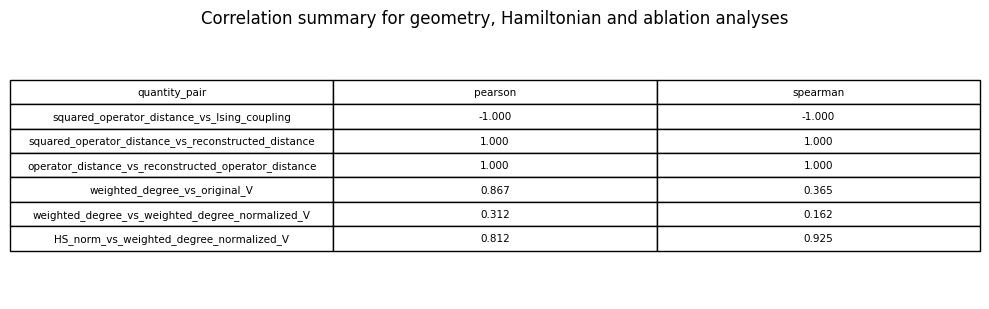

Saved: kras_operator_space_v5_outputs\experiment_10_correlation_summary_table.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10E: compact correlation summary table
# ---------------------------------------------------------------------
correlation_rows = []

def safe_corr(x, y, label):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = np.isfinite(x) & np.isfinite(y)
    if np.sum(mask) < 2:
        return {"quantity_pair": label, "pearson": np.nan, "spearman": np.nan}
    return {
        "quantity_pair": label,
        "pearson": float(pearsonr(x[mask], y[mask]).statistic),
        "spearman": float(spearmanr(x[mask], y[mask]).correlation),
    }

upper = np.triu_indices(N_mut, k=1)
correlation_rows.append(safe_corr(D_sq[upper], J_couplings[upper], "squared_operator_distance_vs_Ising_coupling"))
correlation_rows.append(safe_corr(D_sq[upper], D_sq_from_J[upper], "squared_operator_distance_vs_reconstructed_distance"))
correlation_rows.append(safe_corr(D_hs[upper], D_from_J_hs[upper], "operator_distance_vs_reconstructed_operator_distance"))
correlation_rows.append(safe_corr(mutation_weighted_degrees, V_vec, "weighted_degree_vs_original_V"))
correlation_rows.append(safe_corr(mutation_weighted_degrees, V_weighted_degree_normalized, "weighted_degree_vs_weighted_degree_normalized_V"))
correlation_rows.append(safe_corr(np.sqrt(V_vec), V_weighted_degree_normalized, "HS_norm_vs_weighted_degree_normalized_V"))

correlation_summary_df = pd.DataFrame(correlation_rows)
correlation_summary_df.to_csv(OUTPUT_DIR / "experiment_10_correlation_summary.csv", index=False)
display(correlation_summary_df)

# Visual table figure.
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axis("off")
table_data = correlation_summary_df.copy()
table_data["pearson"] = table_data["pearson"].map(lambda v: f"{v:.3f}" if np.isfinite(v) else "nan")
table_data["spearman"] = table_data["spearman"].map(lambda v: f"{v:.3f}" if np.isfinite(v) else "nan")
tbl = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    loc="center",
    cellLoc="center",
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(7.5)
tbl.scale(1, 1.35)
plt.title("Correlation summary for geometry, Hamiltonian and ablation analyses")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_correlation_summary_table.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10F: optional Sankey-style cluster coverage summary
# ---------------------------------------------------------------------
# This cell uses Plotly if available. If Plotly is not installed, it falls back to a static cluster table.
try:
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except Exception:
    PLOTLY_AVAILABLE = False

K_SANKEY = K_MAIN
selection_for_sankey = {
    "variational": exact_variational_selection(K_SANKEY, V_vec, D_sq, MU)["mask"],
    "top-energy": top_energy_baseline(K_SANKEY, V_vec, D_sq, MU)["mask"],
}
if "sa_result" in globals() and int(sa_result.get("cardinality", -1)) == K_SANKEY:
    selection_for_sankey["simulated_annealing"] = sa_result["mask"]

if "cluster_labels_vis" in globals():
    cluster_labels_for_sankey = np.asarray(cluster_labels_vis)
elif "cluster_labels" in globals():
    cluster_labels_for_sankey = np.asarray(cluster_labels)
else:
    cluster_labels_for_sankey = np.ones(N_mut, dtype=int)

sankey_rows = []
for method, mask in selection_for_sankey.items():
    for i, name in enumerate(mutation_names):
        sankey_rows.append({
            "method": method,
            "mutation": name,
            "cluster": f"Cluster {int(cluster_labels_for_sankey[i])}",
            "selected": int(mask[i]),
        })

sankey_df = pd.DataFrame(sankey_rows)
sankey_df.to_csv(OUTPUT_DIR / "experiment_10_sankey_cluster_selection_data.csv", index=False)
display(sankey_df[sankey_df["selected"] == 1])

if PLOTLY_AVAILABLE:
    # Build a method -> cluster Sankey weighted by selected mutations.
    methods = list(selection_for_sankey.keys())
    clusters = sorted(sankey_df["cluster"].unique(), key=lambda s: int(s.split()[-1]))
    labels = methods + clusters
    label_index = {label: idx for idx, label in enumerate(labels)}

    source = []
    target = []
    value = []
    for method in methods:
        sub = sankey_df[(sankey_df["method"] == method) & (sankey_df["selected"] == 1)]
        counts = sub.groupby("cluster").size()
        for cluster, count in counts.items():
            source.append(label_index[method])
            target.append(label_index[cluster])
            value.append(int(count))

    fig = go.Figure(data=[go.Sankey(
        node=dict(label=labels, pad=18, thickness=18),
        link=dict(source=source, target=target, value=value),
    )])
    fig.update_layout(title_text=f"Cluster coverage by representative-selection method (k={K_SANKEY})", font_size=11)
    out_html = OUTPUT_DIR / "experiment_10_sankey_cluster_coverage.html"
    fig.write_html(str(out_html))
    fig.show()
    print("Saved:", out_html)
else:
    coverage_table = sankey_df[sankey_df["selected"] == 1].pivot_table(
        index="cluster", columns="method", values="mutation", aggfunc=lambda x: ", ".join(x), fill_value=""
    )
    display(coverage_table)
    coverage_table.to_csv(OUTPUT_DIR / "experiment_10_cluster_coverage_table.csv")
    print("Plotly not available. Saved static cluster coverage table instead.")


,method,mutation,cluster,selected
5,variational,G12R,Cluster 6,1
8,variational,G13V,Cluster 4,1
10,variational,Q61L,Cluster 1,1
12,variational,K117N,Cluster 8,1
13,variational,A146T,Cluster 7,1
15,top-energy,G12V,Cluster 6,1
19,top-energy,G12R,Cluster 6,1
24,top-energy,Q61L,Cluster 1,1
26,top-energy,K117N,Cluster 8,1
27,top-energy,A146T,Cluster 7,1


method,simulated_annealing,top-energy,variational
cluster,,,
Cluster 1,Q61L,Q61L,Q61L
Cluster 4,G13V,,G13V
Cluster 6,G12R,"G12V, G12R",G12R
Cluster 7,A146T,A146T,A146T
Cluster 8,K117N,K117N,K117N


Plotly not available. Saved static cluster coverage table instead.


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10G: final representative-subset summary for the manuscript
# ---------------------------------------------------------------------
K_SUMMARY = K_MAIN

summary_rows = []

def add_selection_summary(method, mask_or_result):
    if isinstance(mask_or_result, dict) and "mask" in mask_or_result:
        mask = np.asarray(mask_or_result["mask"], dtype=int)
    elif isinstance(mask_or_result, dict) and "selected" in mask_or_result:
        mask = mask_from_indices([mutation_names.index(m) for m in mask_or_result["selected"]], N_mut)
    else:
        mask = np.asarray(mask_or_result, dtype=int)

    vals = variational_components(mask, V_vec, D_sq, MU)
    clusters_selected = sorted(set(int(cluster_labels_for_sankey[i]) for i in np.where(mask == 1)[0])) if "cluster_labels_for_sankey" in globals() else []
    summary_rows.append({
        "method": method,
        "k": int(mask.sum()),
        "selected": ", ".join(names_from_mask(mask)),
        "V": vals["V"],
        "D": vals["D"],
        "J": vals["J"],
        "n_clusters_covered": len(clusters_selected),
        "clusters_covered": ", ".join(map(str, clusters_selected)),
    })

add_selection_summary("variational_exact", exact_variational_selection(K_SUMMARY, V_vec, D_sq, MU)["mask"])
add_selection_summary("top_perturbation_energy", top_energy_baseline(K_SUMMARY, V_vec, D_sq, MU)["mask"])

if "sa_result" in globals() and int(sa_result.get("cardinality", -1)) == K_SUMMARY:
    add_selection_summary("simulated_annealing", sa_result["mask"])

if "qaoa_df" in globals() and len(qaoa_df) > 0 and "best_bitstring" in qaoa_df.columns:
    best_qaoa_row = qaoa_df.sort_values("best_energy").iloc[0]
    bitstring = best_qaoa_row["best_bitstring"]
    qaoa_mask = np.array([int(ch) for ch in bitstring], dtype=int) if isinstance(bitstring, str) else np.asarray(bitstring, dtype=int)
    if int(qaoa_mask.sum()) == K_SUMMARY:
        add_selection_summary("qaoa_best_sampled", qaoa_mask)

if "normalized_results_df" in globals() and len(normalized_results_df) > 0:
    for _, row in normalized_results_df.iterrows():
        selected_names = [s.strip() for s in str(row["selected"]).split(",") if s.strip()]
        mask = np.zeros(N_mut, dtype=int)
        for name in selected_names:
            if name in mutation_names:
                mask[mutation_names.index(name)] = 1
        if int(mask.sum()) == K_SUMMARY:
            add_selection_summary(f"normalized_{row['variant']}", mask)

final_selection_summary_df = pd.DataFrame(summary_rows)
final_selection_summary_df.to_csv(OUTPUT_DIR / "experiment_10_final_selection_summary.csv", index=False)
display(final_selection_summary_df)


,method,k,selected,V,D,J,n_clusters_covered,clusters_covered
0,variational_exact,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,5,"1, 4, 6, 7, 8"
1,top_perturbation_energy,5,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856,4,"1, 6, 7, 8"
2,simulated_annealing,5,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,5,"1, 4, 6, 7, 8"


### Experiment 12: operator geometry, Hamiltonian couplings, and reconstructed geometry

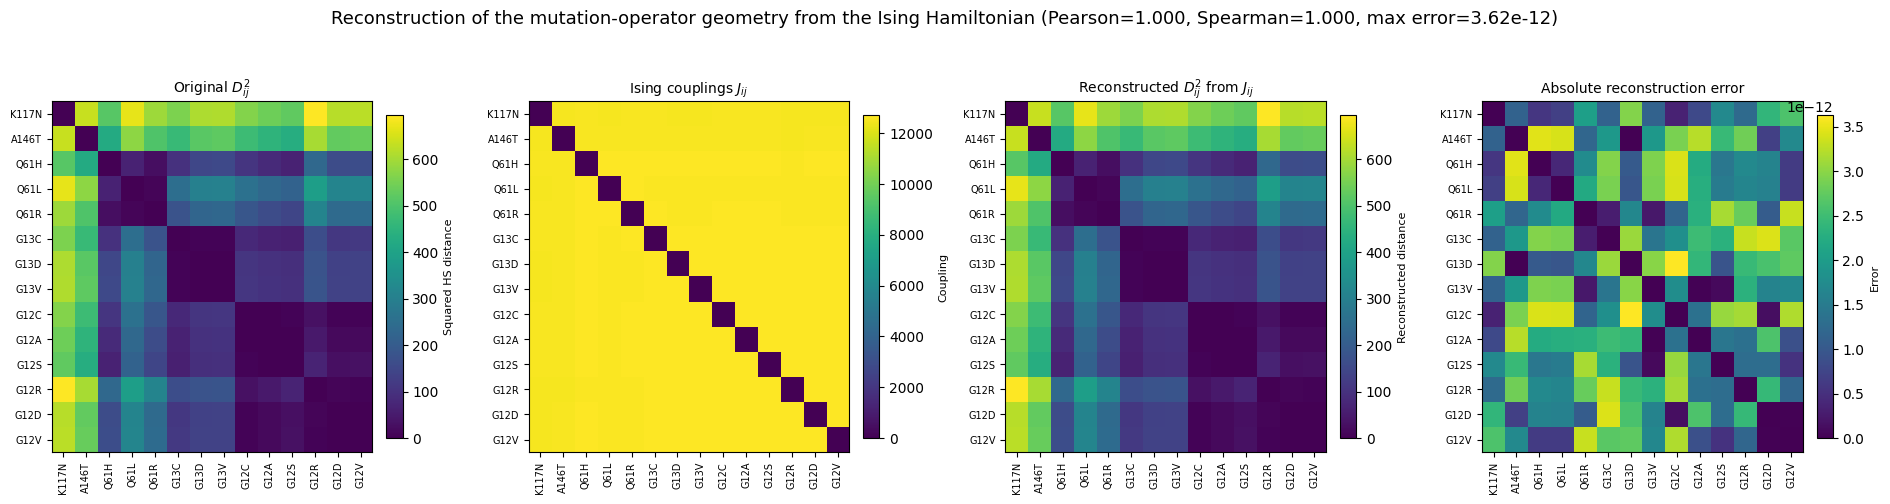

Saved: kras_operator_space_v5_outputs\experiment_12_geometry_hamiltonian_reconstruction.png


,k,lambda,mu,pearson_Dsq_vs_reconstructed_Dsq,spearman_Dsq_vs_reconstructed_Dsq,max_abs_error_Dsq,max_abs_error_Dhs
0,5,25389.536101,1.0,1.0,1.0,3.623768e-12,8.549689e-12


In [ ]:
# ---------------------------------------------------------------------
# Experiment 12: operator geometry -> Ising couplings -> reconstructed geometry
# ---------------------------------------------------------------------
# This figure visualizes the core statement of the geometry-preserving
# Ising representation: the Hamiltonian couplings contain enough information
# to reconstruct the original operator-space geometry.

from scipy.stats import pearsonr, spearmanr

# Ensure the Ising coefficients are available. Reuse the same k and lambda
# used in the geometry-preservation experiments whenever possible.
K_GEOM_RECON = K_QOPT if "K_QOPT" in globals() else K_MAIN
LAMBDA_GEOM_RECON = LAMBDA_QOPT if "LAMBDA_QOPT" in globals() else 1.05 * penalty_bound_B(V_vec, D_sq, MU)

if "J_couplings" not in globals():
    A_geom_recon = build_qubo_matrix(V_vec, D_sq, MU, LAMBDA_GEOM_RECON, K_GEOM_RECON)
    ising_geom_recon = ising_coefficients_from_A(A_geom_recon, LAMBDA_GEOM_RECON, K_GEOM_RECON)
    J_couplings = ising_geom_recon["J"]

if MU <= 0:
    raise ValueError("MU must be positive to reconstruct distances from Ising couplings.")

# Reconstruct squared distances from the Ising couplings:
#     J_ij = lambda/2 - mu/4 D_ij^2
# hence
#     D_ij^2 = (4/mu)(lambda/2 - J_ij).
D_sq_reconstructed = (4.0 / MU) * (LAMBDA_GEOM_RECON / 2.0 - J_couplings)
np.fill_diagonal(D_sq_reconstructed, 0.0)
D_sq_reconstructed = np.maximum(D_sq_reconstructed, 0.0)
D_hs_reconstructed = np.sqrt(D_sq_reconstructed)

abs_error_sq = np.abs(D_sq - D_sq_reconstructed)
max_abs_error_sq = float(np.max(abs_error_sq))
max_abs_error_hs = float(np.max(np.abs(D_hs - D_hs_reconstructed)))

upper = np.triu_indices(N_mut, k=1)
pearson_recon = pearsonr(D_sq[upper], D_sq_reconstructed[upper]).statistic
spearman_recon = spearmanr(D_sq[upper], D_sq_reconstructed[upper]).correlation

# Use the same ordering in all panels for direct visual comparison.
try:
    order_recon = order_D
except NameError:
    Z_recon = linkage(squareform(D_hs, checks=False), method="average")
    order_recon = leaves_list(Z_recon)

labels_recon = [mutation_names[i] for i in order_recon]
D_sq_ord = D_sq[np.ix_(order_recon, order_recon)]
J_ord = J_couplings[np.ix_(order_recon, order_recon)]
D_sq_rec_ord = D_sq_reconstructed[np.ix_(order_recon, order_recon)]
err_ord = abs_error_sq[np.ix_(order_recon, order_recon)]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))

panels = [
    (D_sq_ord, r"Original $D_{ij}^2$", r"Squared HS distance"),
    (J_ord, r"Ising couplings $J_{ij}$", r"Coupling"),
    (D_sq_rec_ord, r"Reconstructed $D_{ij}^2$ from $J_{ij}$", r"Reconstructed distance"),
    (err_ord, r"Absolute reconstruction error", r"Error"),
]

for ax, (mat, title, cbar_label) in zip(axes, panels):
    im = ax.imshow(mat, aspect="auto")
    ax.set_title(title, fontsize=10)
    ax.set_xticks(np.arange(N_mut))
    ax.set_yticks(np.arange(N_mut))
    ax.set_xticklabels(labels_recon, rotation=90, fontsize=7)
    ax.set_yticklabels(labels_recon, fontsize=7)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label, fontsize=8)

fig.suptitle(
    "Reconstruction of the mutation-operator geometry from the Ising Hamiltonian "
    f"(Pearson={pearson_recon:.3f}, Spearman={spearman_recon:.3f}, max error={max_abs_error_sq:.2e})",
    fontsize=13,
    y=1.04,
)
fig.tight_layout()

out_path = OUTPUT_DIR / "experiment_12_geometry_hamiltonian_reconstruction.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

geometry_reconstruction_summary_df = pd.DataFrame([
    {
        "k": K_GEOM_RECON,
        "lambda": LAMBDA_GEOM_RECON,
        "mu": MU,
        "pearson_Dsq_vs_reconstructed_Dsq": float(pearson_recon),
        "spearman_Dsq_vs_reconstructed_Dsq": float(spearman_recon),
        "max_abs_error_Dsq": max_abs_error_sq,
        "max_abs_error_Dhs": max_abs_error_hs,
    }
])
geometry_reconstruction_summary_df.to_csv(
    OUTPUT_DIR / "experiment_12_geometry_reconstruction_summary.csv",
    index=False,
)
display(geometry_reconstruction_summary_df)

### Experiment 10H: Geometry-only MDS visualization

C:\Users\Roberto\anaconda3\envs\Computacion-cuantica\Lib\site-packages\sklearn\manifold\_mds.py:744: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9. To suppress this warning, provide some value of `n_init`.
  warnings.warn(
C:\Users\Roberto\anaconda3\envs\Computacion-cuantica\Lib\site-packages\sklearn\manifold\_mds.py:754: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
C:\Users\Roberto\anaconda3\envs\Computacion-cuantica\Lib\site-packages\sklearn\manifold\_mds.py:771: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


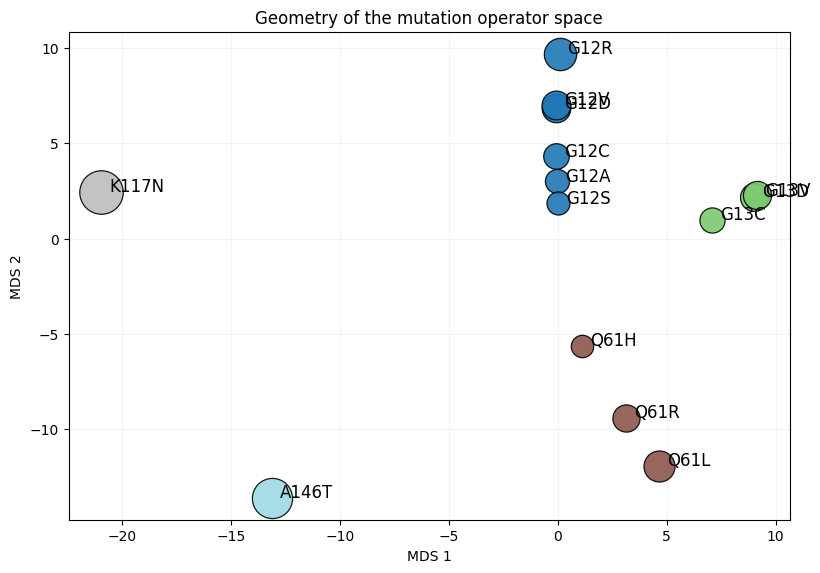

Saved figure to: kras_operator_space_v5_outputs\experiment_10_geometry_only_mds.png


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10H: Geometry-only MDS visualization
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
import numpy as np

# Recover the Hilbert--Schmidt operator-distance matrix from previous cells.
# The MDS embedding must use distances, not squared distances.
if "D_hs" in globals():
    DIST_HS = np.asarray(D_hs, dtype=float)
elif "D_sq" in globals():
    DIST_HS = np.sqrt(np.maximum(np.asarray(D_sq, dtype=float), 0.0))
elif "D_matrix" in globals():
    # Backward compatibility: older versions used D_matrix ambiguously.
    # If it looks squared, this conversion still gives the intended HS scale.
    D_tmp = np.asarray(D_matrix, dtype=float)
    DIST_HS = np.sqrt(np.maximum(D_tmp, 0.0))
elif "distance_matrix" in globals():
    DIST_HS = np.asarray(distance_matrix, dtype=float)
elif "distance_df" in globals():
    DIST_HS = np.asarray(distance_df.values, dtype=float)
else:
    raise RuntimeError(
        "Operator distance matrix not found. Execute the previous "
        "operator-space geometry cells first."
    )

coords = MDS(
    n_components=2,
    dissimilarity="precomputed",
    random_state=42,
    normalized_stress="auto",
).fit_transform(DIST_HS)

site_colors = {}
for m in mutation_names:
    if m.startswith("G12"):
        site_colors[m] = "#1f77b4"
    elif m.startswith("G13"):
        site_colors[m] = "#7bc96f"
    elif m.startswith("Q61"):
        site_colors[m] = "#8c564b"
    elif m.startswith("K117"):
        site_colors[m] = "#bdbdbd"
    else:
        site_colors[m] = "#9edae5"

sizes = 260 + 720 * (V_vec - V_vec.min()) / (V_vec.max() - V_vec.min() + 1e-12)

plt.figure(figsize=(8.2, 6.1))
ax = plt.gca()

for i, m in enumerate(mutation_names):
    ax.scatter(
        coords[i, 0],
        coords[i, 1],
        s=sizes[i],
        color=site_colors[m],
        edgecolor="black",
        linewidth=0.9,
        alpha=0.9,
        zorder=2,
    )

# Slightly larger labels. A fixed offset is intentionally used to keep the
# visualization deterministic and reproducible without external label-adjustment
# dependencies.
x_span = coords[:, 0].max() - coords[:, 0].min()
y_span = coords[:, 1].max() - coords[:, 1].min()
dx = 0.012 * x_span
dy = 0.012 * y_span

for i, m in enumerate(mutation_names):
    ax.text(
        coords[i, 0] + dx,
        coords[i, 1] + dy,
        m,
        fontsize=12,
        ha="left",
        va="center",
        zorder=3,
    )

ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")
ax.set_title("Geometry of the mutation operator space")

# No legend is shown here to keep the paper figure uncluttered. Colors encode
# mutation site and marker size is proportional to V_i; both are described in
# the figure caption.
ax.grid(alpha=0.15)
plt.subplots_adjust(left=0.10, right=0.98, bottom=0.11, top=0.91)

out_path = OUTPUT_DIR / "experiment_10_geometry_only_mds.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {out_path}")


### Experiment 10I: Distribution of Hilbert--Schmidt distances

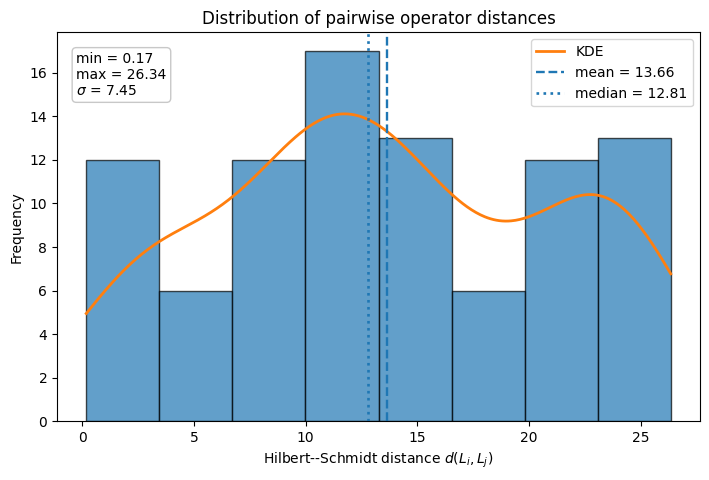

Saved figure to: kras_operator_space_v5_outputs\experiment_10_operator_distance_histogram.png
min=0.175
max=26.341
mean=13.656
median=12.806
std=7.449


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10I: Distribution of Hilbert--Schmidt distances
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

# Recover the Hilbert--Schmidt operator-distance matrix from previous cells.
if "D_hs" in globals():
    DIST_HS = np.asarray(D_hs, dtype=float)
elif "D_sq" in globals():
    DIST_HS = np.sqrt(np.maximum(np.asarray(D_sq, dtype=float), 0.0))
elif "D_matrix" in globals():
    D_tmp = np.asarray(D_matrix, dtype=float)
    DIST_HS = np.sqrt(np.maximum(D_tmp, 0.0))
elif "distance_matrix" in globals():
    DIST_HS = np.asarray(distance_matrix, dtype=float)
elif "distance_df" in globals():
    DIST_HS = np.asarray(distance_df.values, dtype=float)
else:
    raise RuntimeError(
        "Operator distance matrix not found. Execute the previous "
        "operator-space geometry cells first."
    )

vals = DIST_HS[np.triu_indices_from(DIST_HS, k=1)]

mean_val = float(vals.mean())
median_val = float(np.median(vals))
std_val = float(vals.std())
min_val = float(vals.min())
max_val = float(vals.max())

fig, ax = plt.subplots(figsize=(7.2, 4.9))

counts, bins, _ = ax.hist(
    vals,
    bins="auto",
    edgecolor="black",
    alpha=0.70,
    density=False,
)

# Kernel density estimate, rescaled to histogram counts.
x_grid = np.linspace(min_val, max_val, 400)
kde = gaussian_kde(vals)
bin_width = np.mean(np.diff(bins))
kde_counts = kde(x_grid) * len(vals) * bin_width
ax.plot(x_grid, kde_counts, linewidth=2.0, label="KDE")

ax.axvline(mean_val, linestyle="--", linewidth=1.7, label=f"mean = {mean_val:.2f}")
ax.axvline(median_val, linestyle=":", linewidth=1.9, label=f"median = {median_val:.2f}")

stats_text = (
    f"min = {min_val:.2f}\n"
    f"max = {max_val:.2f}\n"
    f"$\\sigma$ = {std_val:.2f}"
)
ax.text(
    0.03,
    0.95,
    stats_text,
    transform=ax.transAxes,
    va="top",
    ha="left",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.75"),
)

ax.set_xlabel(r"Hilbert--Schmidt distance $d(L_i,L_j)$")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of pairwise operator distances")
ax.legend(loc="upper right")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_operator_distance_histogram.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {out_path}")
print(f"min={min_val:.3f}")
print(f"max={max_val:.3f}")
print(f"mean={mean_val:.3f}")
print(f"median={median_val:.3f}")
print(f"std={std_val:.3f}")


### Experiment 10J: Perturbation-energy ranking of mutation operators


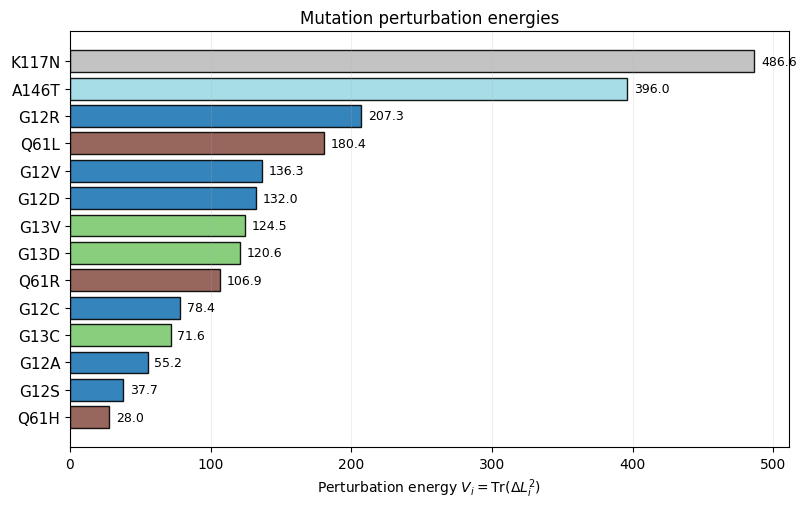

Saved figure to: kras_operator_space_v5_outputs\experiment_10_operator_energy_ranking.png


,mutation,V_i
0,K117N,486.597913
1,A146T,395.962046
2,G12R,207.269593
3,Q61L,180.367635
4,G12V,136.272940
5,G12D,132.039525
6,G13V,124.469871
7,G13D,120.603126
8,Q61R,106.895648
9,G12C,78.370481


In [ ]:
# ---------------------------------------------------------------------
# Experiment 10J: Perturbation-energy ranking of mutation operators
# ---------------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np

if "mutation_names" not in globals() or "V_vec" not in globals():
    raise RuntimeError(
        "mutation_names and V_vec must exist. Execute the operator-space "
        "construction cells first."
    )

names_arr = np.asarray(mutation_names)
V_arr = np.asarray(V_vec, dtype=float)

order = np.argsort(V_arr)[::-1]
names_sorted = names_arr[order]
V_sorted = V_arr[order]

def site_color(m):
    if m.startswith("G12"):
        return "#1f77b4"
    if m.startswith("G13"):
        return "#7bc96f"
    if m.startswith("Q61"):
        return "#8c564b"
    if m.startswith("K117"):
        return "#bdbdbd"
    return "#9edae5"

colors_sorted = [site_color(m) for m in names_sorted]

fig, ax = plt.subplots(figsize=(8.2, 5.2))
y = np.arange(len(names_sorted))

ax.barh(y, V_sorted, color=colors_sorted, edgecolor="black", alpha=0.9)
ax.set_yticks(y)
ax.set_yticklabels(names_sorted, fontsize=11)
ax.invert_yaxis()

ax.set_xlabel(r"Perturbation energy $V_i=\operatorname{Tr}(\Delta L_i^2)$")
ax.set_title("Mutation perturbation energies")

for yi, val in zip(y, V_sorted):
    ax.text(val + 0.01 * V_sorted.max(), yi, f"{val:.1f}", va="center", fontsize=9)

ax.grid(axis="x", alpha=0.2)
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_10_operator_energy_ranking.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

energy_ranking_df = (
    pd.DataFrame({"mutation": names_sorted, "V_i": V_sorted})
    if "pd" in globals()
    else None
)

print(f"Saved figure to: {out_path}")
if energy_ranking_df is not None:
    display(energy_ranking_df)



## Experiment 11: final manuscript figures for variational representative selection



,method,k,V,D,J,selected
0,variational,5,1394.667058,5180.325154,-6574.992212,"G12R, G13V, Q61L, K117N, A146T"
1,top-energy,5,1406.470127,5042.880729,-6449.350856,"G12V, G12R, Q61L, K117N, A146T"
2,simulated annealing,5,1394.667058,5180.325154,-6574.992212,"G12R, G13V, Q61L, K117N, A146T"


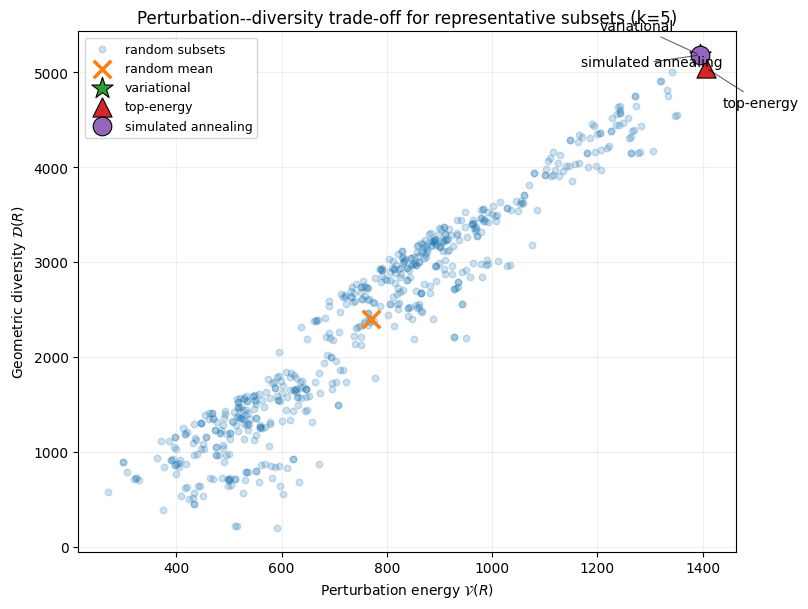

Saved: kras_operator_space_v5_outputs\experiment_11_pareto_V_D_tradeoff_final.png


In [ ]:

# ---------------------------------------------------------------------
# Experiment 11A: final Pareto-style perturbation--diversity trade-off
# ---------------------------------------------------------------------

K_PARETO = K_MAIN

# Recompute exact and top-energy summaries to avoid depending on previous cells.
exact_main = exact_variational_selection(K_PARETO, V_vec, D_sq, MU)
top_main = top_energy_baseline(K_PARETO, V_vec, D_sq, MU)

pareto_rows_final = []

for method_label, result in [
    ("variational", exact_main),
    ("top-energy", top_main),
]:
    pareto_rows_final.append({
        "method": method_label,
        "k": K_PARETO,
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selected": ", ".join(result["selected"]),
        "mask": result["mask"],
    })

# Simulated annealing if available.
if "sa_result" in globals() and int(sa_result.get("cardinality", -1)) == K_PARETO:
    sa_mask = sa_result["mask"]
    sa_vals = variational_components(sa_mask, V_vec, D_sq, MU)
    pareto_rows_final.append({
        "method": "simulated annealing",
        "k": K_PARETO,
        "V": sa_vals["V"],
        "D": sa_vals["D"],
        "J": sa_vals["J"],
        "selected": ", ".join(names_from_mask(sa_mask)),
        "mask": sa_mask,
    })

# QAOA best sampled result if available and feasible.
if "qaoa_df" in globals() and len(qaoa_df) > 0 and "best_bitstring" in qaoa_df.columns:
    try:
        best_row = qaoa_df.sort_values("best_energy").iloc[0]
        bitstring = best_row["best_bitstring"]
        if isinstance(bitstring, str):
            qaoa_mask = np.array([int(ch) for ch in bitstring], dtype=int)
        else:
            qaoa_mask = np.array(bitstring, dtype=int)

        if int(qaoa_mask.sum()) == K_PARETO:
            qaoa_vals = variational_components(qaoa_mask, V_vec, D_sq, MU)
            pareto_rows_final.append({
                "method": "QAOA",
                "k": K_PARETO,
                "V": qaoa_vals["V"],
                "D": qaoa_vals["D"],
                "J": qaoa_vals["J"],
                "selected": ", ".join(names_from_mask(qaoa_mask)),
                "mask": qaoa_mask,
            })
    except Exception as exc:
        print("QAOA point skipped:", exc)

pareto_final_df = pd.DataFrame([
    {k: v for k, v in row.items() if k != "mask"}
    for row in pareto_rows_final
])
pareto_final_df.to_csv(OUTPUT_DIR / "experiment_11_pareto_summary_final.csv", index=False)
display(pareto_final_df)

# Random cloud.
rng = np.random.default_rng(RANDOM_SEED + 1100 + K_PARETO)
random_points = []
for _ in range(600):
    idx = tuple(rng.choice(N_mut, size=K_PARETO, replace=False))
    mask = mask_from_indices(idx, N_mut)
    random_points.append(variational_components(mask, V_vec, D_sq, MU))
random_df_final = pd.DataFrame(random_points)

fig, ax = plt.subplots(figsize=(8.2, 6.2))
ax.scatter(
    random_df_final["V"],
    random_df_final["D"],
    s=22,
    alpha=0.22,
    label="random subsets",
)

# Random mean.
ax.scatter(
    [random_df_final["V"].mean()],
    [random_df_final["D"].mean()],
    marker="x",
    s=160,
    linewidths=2.5,
    label="random mean",
)

marker_map = {
    "variational": "*",
    "top-energy": "^",
    "simulated annealing": "o",
    "QAOA": "s",
}
size_map = {
    "variational": 260,
    "top-energy": 190,
    "simulated annealing": 180,
    "QAOA": 170,
}

# Offset labels manually to avoid overlapping at the upper right.
label_offsets = {
    "variational": (-72, 18),
    "top-energy": (12, -28),
    "simulated annealing": (-86, -8),
    "QAOA": (16, 16),
}

for row in pareto_rows_final:
    method = row["method"]
    ax.scatter(
        [row["V"]],
        [row["D"]],
        marker=marker_map.get(method, "o"),
        s=size_map.get(method, 160),
        edgecolor="black",
        linewidth=0.8,
        label=method,
        zorder=5,
    )
    dx, dy = label_offsets.get(method, (8, 8))
    ax.annotate(
        method,
        xy=(row["V"], row["D"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=10,
        arrowprops=dict(arrowstyle="-", lw=0.8, alpha=0.6),
        zorder=6,
    )

ax.set_xlabel(r"Perturbation energy $\mathcal{V}(R)$")
ax.set_ylabel(r"Geometric diversity $\mathcal{D}(R)$")
ax.set_title(f"Perturbation--diversity trade-off for representative subsets (k={K_PARETO})")
ax.grid(alpha=0.2)
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_11_pareto_V_D_tradeoff_final.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


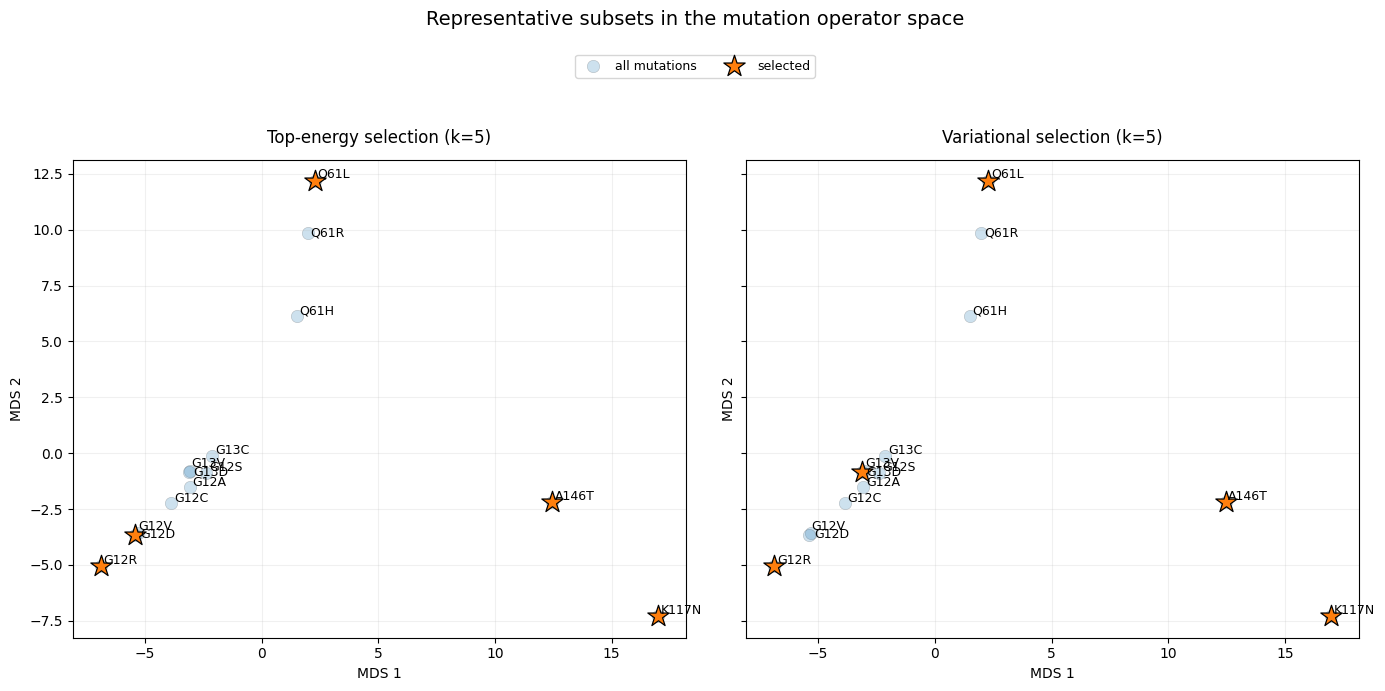

Saved: kras_operator_space_v5_outputs\experiment_11_mds_top_energy_vs_variational.png


,method,selected,V,D,J
0,top-energy,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-6449.350856
1,variational,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212


In [ ]:
# ---------------------------------------------------------------------
# Experiment 11B: side-by-side MDS comparison of top-energy vs variational selection
# ---------------------------------------------------------------------
# This figure shows why the diversity term matters:
# top-energy selection tends to reuse nearby/high-energy regions,
# whereas the variational solution covers a broader region of the operator space.

K_SHOW = K_MAIN
exact_show = exact_variational_selection(K_SHOW, V_vec, D_sq, MU)
top_show = top_energy_baseline(K_SHOW, V_vec, D_sq, MU)

# Robust recovery of MDS coordinates.
if "mds_coords" in globals():
    COORDS = np.asarray(mds_coords)
else:
    from sklearn.manifold import MDS
    COORDS = MDS(
        n_components=2,
        dissimilarity="precomputed",
        random_state=42,
        normalized_stress="auto",
    ).fit_transform(D_hs)

def plot_selection_panel(ax, selected_mask, title):
    selected_idx = set(np.where(selected_mask == 1)[0])

    # Background: all mutations.
    ax.scatter(
        COORDS[:, 0],
        COORDS[:, 1],
        s=80,
        alpha=0.22,
        edgecolor="black",
        linewidth=0.4,
        label="all mutations",
    )

    # Selected mutations.
    ax.scatter(
        COORDS[list(selected_idx), 0],
        COORDS[list(selected_idx), 1],
        s=260,
        marker="*",
        edgecolor="black",
        linewidth=0.9,
        label="selected",
        zorder=5,
    )

    # Small manual offsets to reduce label overlap in dense regions.
    label_offsets = {
        "G12D": (0.12, -0.22),
        "G12V": (0.12, 0.22),
        "G13D": (0.12, -0.22),
        "G13V": (0.12, 0.22),
        "Q61L": (0.12, 0.18),
        "Q61R": (0.12, -0.18),
    }

    for i, name in enumerate(mutation_names):
        offset_x, offset_y = label_offsets.get(name, (0.12, 0.08))
        ax.text(
            COORDS[i, 0] + offset_x,
            COORDS[i, 1] + offset_y,
            name,
            fontsize=9,
            zorder=6,
        )

    ax.set_title(title, pad=12)
    ax.set_xlabel("MDS 1")
    ax.set_ylabel("MDS 2")
    ax.grid(alpha=0.18)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)

plot_selection_panel(
    axes[0],
    top_show["mask"],
    f"Top-energy selection (k={K_SHOW})",
)

plot_selection_panel(
    axes[1],
    exact_show["mask"],
    f"Variational selection (k={K_SHOW})",
)

# Put the legend below the title and outside the plotting area to avoid overlap.
handles, labels = axes[1].get_legend_handles_labels()
fig.suptitle("Representative subsets in the mutation operator space", y=0.98, fontsize=14)
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=2,
    frameon=True,
    fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.88])

out_path = OUTPUT_DIR / "experiment_11_mds_top_energy_vs_variational.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

comparison_rows = []
for method, result in [
    ("top-energy", top_show),
    ("variational", exact_show),
]:
    comparison_rows.append({
        "method": method,
        "selected": ", ".join(result["selected"]),
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
    })
selection_comparison_df = pd.DataFrame(comparison_rows)
selection_comparison_df.to_csv(OUTPUT_DIR / "experiment_11_selection_comparison.csv", index=False)
display(selection_comparison_df)

In [ ]:

# ---------------------------------------------------------------------
# Experiment 11C: compact cluster-coverage table
# ---------------------------------------------------------------------
# The coverage information is more effective as a table than as a standalone bar plot.

N_CLUSTERS_FOR_TABLE = len(set(cluster_labels)) if "cluster_labels" in globals() else np.nan

coverage_table_rows = []
coverage_masks = {
    "variational": exact_show["mask"],
    "top-energy": top_show["mask"],
}

if "qaoa_mask" in globals() and int(np.sum(qaoa_mask)) == K_SHOW:
    coverage_masks["QAOA"] = qaoa_mask

if "sa_result" in globals() and int(sa_result.get("cardinality", -1)) == K_SHOW:
    coverage_masks["simulated annealing"] = sa_result["mask"]

for method, mask in coverage_masks.items():
    selected_idx = np.where(mask == 1)[0]
    if "cluster_labels" in globals():
        covered = sorted(set(cluster_labels[selected_idx]))
        n_covered = len(covered)
        ratio = n_covered / max(1, len(set(cluster_labels)))
        covered_str = ", ".join(map(str, covered))
    else:
        n_covered = np.nan
        ratio = np.nan
        covered_str = ""

    coverage_table_rows.append({
        "method": method,
        "selected": ", ".join(names_from_mask(mask)),
        "covered clusters": covered_str,
        "coverage": f"{n_covered}/{N_CLUSTERS_FOR_TABLE}" if not pd.isna(n_covered) else "",
        "coverage ratio": ratio,
    })

coverage_table_final_df = pd.DataFrame(coverage_table_rows)
coverage_table_final_df.to_csv(OUTPUT_DIR / "experiment_11_cluster_coverage_table.csv", index=False)
display(coverage_table_final_df)


,method,selected,covered clusters,coverage,coverage ratio
0,variational,"G12R, G13V, Q61L, K117N, A146T","1, 4, 6, 7, 8",5/8,0.625
1,top-energy,"G12V, G12R, Q61L, K117N, A146T","1, 6, 7, 8",4/8,0.500
2,simulated annealing,"G12R, G13V, Q61L, K117N, A146T","1, 4, 6, 7, 8",5/8,0.625


,mu,selected,V,D,J,selection_changed
0,0.00,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1406.470127,True
1,0.05,"G12V, G12R, Q61L, K117N, A146T",1406.470127,5042.880729,-1658.614164,False
2,0.10,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-1912.699573,True
3,0.25,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-2689.748346,False
4,0.50,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-3984.829635,False
5,1.00,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-6574.992212,False
6,2.00,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-11755.317366,False
7,5.00,"G12R, G13V, Q61L, K117N, A146T",1394.667058,5180.325154,-27296.292828,False


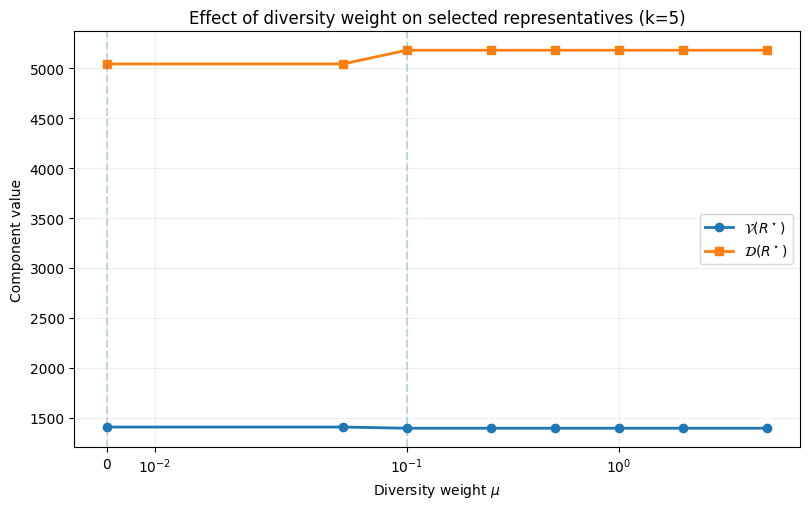

Saved: kras_operator_space_v5_outputs\experiment_11_mu_evolution_components_final.png


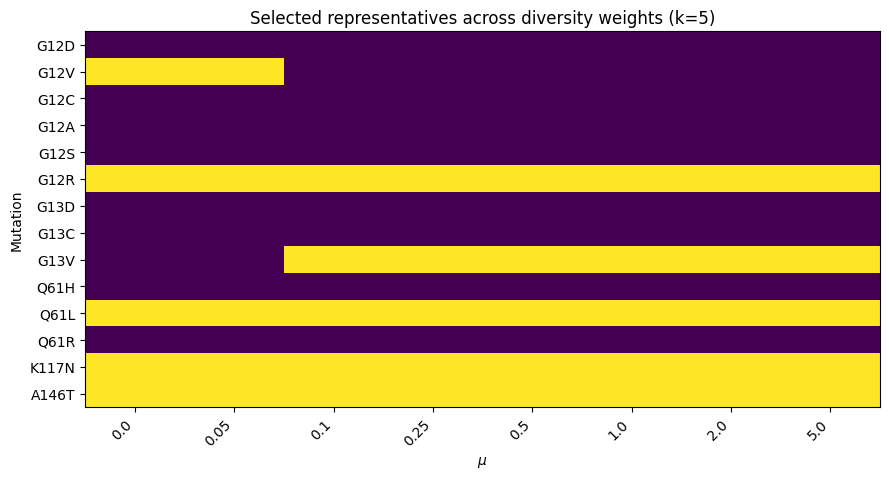

Saved: kras_operator_space_v5_outputs\experiment_11_mu_selection_matrix_final.png


In [ ]:

# ---------------------------------------------------------------------
# Experiment 11D: final mu sensitivity figures with cleaner labels
# ---------------------------------------------------------------------
MU_GRID_FINAL = np.array([0.0, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0], dtype=float)
K_MU = K_MAIN

mu_rows_final = []
prev_selection = None

for mu_value in MU_GRID_FINAL:
    result = exact_variational_selection(K_MU, V_vec, D_sq, mu_value)
    selection_tuple = tuple(result["selected"])
    changed = selection_tuple != prev_selection
    prev_selection = selection_tuple

    mu_rows_final.append({
        "mu": mu_value,
        "selected": ", ".join(result["selected"]),
        "V": result["V"],
        "D": result["D"],
        "J": result["J"],
        "selection_changed": changed,
    })

mu_sensitivity_final_df = pd.DataFrame(mu_rows_final)
mu_sensitivity_final_df.to_csv(OUTPUT_DIR / "experiment_11_mu_sensitivity_final.csv", index=False)
display(mu_sensitivity_final_df)

fig, ax = plt.subplots(figsize=(8.2, 5.2))
ax.plot(
    mu_sensitivity_final_df["mu"],
    mu_sensitivity_final_df["V"],
    marker="o",
    linewidth=2,
    label=r"$\mathcal{V}(R^\star)$",
)
ax.plot(
    mu_sensitivity_final_df["mu"],
    mu_sensitivity_final_df["D"],
    marker="s",
    linewidth=2,
    label=r"$\mathcal{D}(R^\star)$",
)
ax.set_xscale("symlog", linthresh=0.05)
ax.set_xlabel(r"Diversity weight $\mu$")
ax.set_ylabel("Component value")
ax.set_title(f"Effect of diversity weight on selected representatives (k={K_MU})")

for _, row in mu_sensitivity_final_df.iterrows():
    if row["selection_changed"]:
        ax.axvline(row["mu"], linestyle="--", alpha=0.25)

ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_11_mu_evolution_components_final.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)

# Selection matrix.
selection_matrix_mu_final = pd.DataFrame(0, index=mutation_names, columns=[str(mu) for mu in MU_GRID_FINAL])
for _, row in mu_sensitivity_final_df.iterrows():
    selected_names = [s.strip() for s in row["selected"].split(",") if s.strip()]
    for name in selected_names:
        selection_matrix_mu_final.loc[name, str(row["mu"])] = 1

fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * N_mut)))
ax.imshow(selection_matrix_mu_final.values, aspect="auto")
ax.set_yticks(np.arange(N_mut))
ax.set_yticklabels(mutation_names)
ax.set_xticks(np.arange(len(MU_GRID_FINAL)))
ax.set_xticklabels([str(mu) for mu in MU_GRID_FINAL], rotation=45, ha="right")
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Mutation")
ax.set_title(f"Selected representatives across diversity weights (k={K_MU})")
plt.tight_layout()

out_path = OUTPUT_DIR / "experiment_11_mu_selection_matrix_final.png"
plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", out_path)


## Experiment 13. Optimization of the induced Ising Hamiltonian (paper-ready figures)

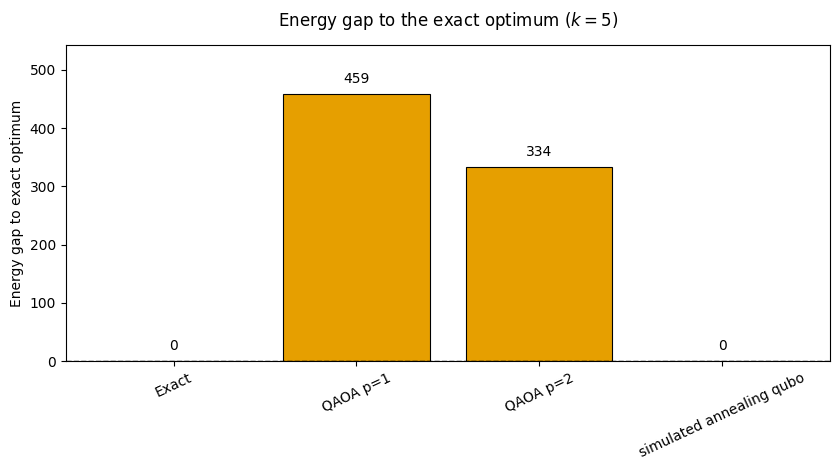

,solver,energy,optimality_gap,relative_gap_percent,optimal_probability,feasible_probability,selected
0,Exact,-6574.992212,0.000000,0.000000,1.000000,1.000000,"G12R, G13V, Q61L, K117N, A146T"
1,QAOA p=1,-6115.806633,459.185579,6.983819,0.000038,0.122134,"G12S, G12R, Q61L, K117N, A146T"
2,QAOA p=2,-6241.062471,333.929740,5.078785,0.000019,0.123923,"G12C, G12R, Q61L, K117N, A146T"
3,simulated annealing qubo,-6574.992212,0.000000,0.000000,NaN,1.000000,"G12R, G13V, Q61L, K117N, A146T"


Saved solver comparison table: kras_operator_space_v5_outputs\experiment_13_solver_comparison_table.csv


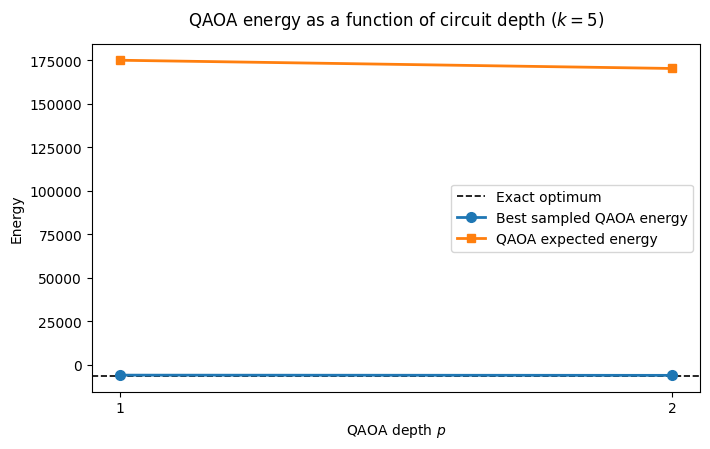

Saved:
 - kras_operator_space_v5_outputs\experiment_13_energy_gap_to_exact_optimum.png
 - kras_operator_space_v5_outputs\experiment_13_qaoa_depth_convergence.png


In [ ]:

# ---------------------------------------------------------------------
# Experiment 13: paper-ready optimization figures for Section 4.5
# ---------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Recover output directory.
if "OUTPUT_DIR" not in globals():
    OUTPUT_DIR = Path("figures")
else:
    OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Recover Experiment 4 dataframe.
if "experiment_4_df" in globals():
    exp4 = experiment_4_df.copy()
else:
    csv_path = OUTPUT_DIR / "experiment_4_quantum_hybrid_optimization.csv"
    if not csv_path.exists():
        raise RuntimeError(
            "Experiment 4 results not found. Execute Experiment 4 first, "
            "or ensure experiment_4_quantum_hybrid_optimization.csv exists in OUTPUT_DIR."
        )
    exp4 = pd.read_csv(csv_path)

# Infer main k value.
K_MAIN = int(exp4["cardinality"].dropna().mode().iloc[0]) if "cardinality" in exp4 else 5

def pretty_solver_label(row):
    method = str(row["method"])
    if method == "exact_enumeration":
        return "Exact"
    if method == "simulated_annealing":
        return "SA"
    if method == "qaoa_statevector_sampled_best":
        return f"QAOA p={int(row['p'])}"
    return method.replace("_", " ")

exp4["solver"] = exp4.apply(pretty_solver_label, axis=1)

# Sort solvers in a consistent order.
def solver_order(label):
    if label == "Exact":
        return 0
    if label.startswith("QAOA"):
        try:
            return 10 + int(label.split("=")[1])
        except Exception:
            return 19
    if label == "SA":
        return 99
    return 50

exp4 = exp4.sort_values("solver", key=lambda s: s.map(solver_order)).reset_index(drop=True)

# ---------------------------------------------------------------------
# Paper-ready figure 1: energy gap to exact optimum.
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8.5, 4.8))

labels = exp4["solver"].tolist()
gaps = exp4["optimality_gap"].astype(float).values

bar_colors = []
for lab, gap in zip(labels, gaps):
    if abs(gap) < 1e-9:
        bar_colors.append("#4C9A2A")  # optimal
    elif lab.startswith("QAOA"):
        bar_colors.append("#E69F00")  # shallow QAOA
    else:
        bar_colors.append("#999999")

bars = ax.bar(labels, gaps, color=bar_colors, edgecolor="black", linewidth=0.8)
ax.axhline(0, linestyle="--", linewidth=1.0, color="black")
ax.set_ylabel("Energy gap to exact optimum")
ax.set_title(f"Energy gap to the exact optimum ($k={K_MAIN}$)", pad=14)
ax.tick_params(axis="x", rotation=25)

# Annotate bars.
ymax = max(np.max(gaps), 1.0)
for bar, gap in zip(bars, gaps):
    height = bar.get_height()
    label = f"{gap:.0f}" if abs(gap) >= 1 else f"{gap:.2g}"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.03 * ymax,
        label,
        ha="center",
        va="bottom",
        fontsize=10,
    )

ax.set_ylim(0, ymax * 1.18)
plt.tight_layout()
gap_path = OUTPUT_DIR / "experiment_13_energy_gap_to_exact_optimum.png"
plt.savefig(gap_path, dpi=300, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------
# Paper-ready table: solver comparison.
# ---------------------------------------------------------------------
summary_cols = ["solver", "energy", "optimality_gap", "relative_gap", "optimal_probability", "feasible_probability", "selected"]
available_cols = [c for c in summary_cols if c in exp4.columns]
solver_summary = exp4[available_cols].copy()

# Use percentages for readability.
if "relative_gap" in solver_summary.columns:
    solver_summary["relative_gap_percent"] = 100.0 * solver_summary["relative_gap"].astype(float)
if "optimal_probability" in solver_summary.columns:
    solver_summary["optimal_probability"] = solver_summary["optimal_probability"].astype(float)
if "feasible_probability" in solver_summary.columns:
    solver_summary["feasible_probability"] = solver_summary["feasible_probability"].astype(float)

# Reorder columns for manuscript.
ordered = ["solver", "energy", "optimality_gap", "relative_gap_percent", "optimal_probability", "feasible_probability", "selected"]
solver_summary = solver_summary[[c for c in ordered if c in solver_summary.columns]]
solver_summary.to_csv(OUTPUT_DIR / "experiment_13_solver_comparison_table.csv", index=False)

display(solver_summary)
print("Saved solver comparison table:", OUTPUT_DIR / "experiment_13_solver_comparison_table.csv")

# ---------------------------------------------------------------------
# Paper-ready figure 2: QAOA convergence with depth.
# ---------------------------------------------------------------------
qaoa = exp4[exp4["solver"].str.startswith("QAOA")].copy()
if len(qaoa) > 0:
    qaoa["p"] = qaoa["p"].astype(int)
    qaoa = qaoa.sort_values("p")

    fig, ax = plt.subplots(figsize=(7.2, 4.6))

    # Exact energy line.
    exact_rows = exp4[exp4["solver"] == "Exact"]
    if len(exact_rows) > 0:
        exact_energy_plot = float(exact_rows["energy"].iloc[0])
        ax.axhline(
            exact_energy_plot,
            linestyle="--",
            linewidth=1.2,
            color="black",
            label="Exact optimum",
        )

    # Plot best sampled energy.
    ax.plot(
        qaoa["p"],
        qaoa["energy"],
        marker="o",
        linewidth=2.0,
        markersize=7,
        label="Best sampled QAOA energy",
    )

    # Plot expectation if available and finite.
    if "expectation" in qaoa.columns and np.isfinite(qaoa["expectation"].astype(float)).all():
        ax.plot(
            qaoa["p"],
            qaoa["expectation"],
            marker="s",
            linewidth=2.0,
            markersize=6,
            label="QAOA expected energy",
        )

    ax.set_xlabel("QAOA depth $p$")
    ax.set_ylabel("Energy")
    ax.set_title(f"QAOA energy as a function of circuit depth ($k={K_MAIN}$)", pad=14)
    ax.set_xticks(qaoa["p"].tolist())
    ax.legend(frameon=True)
    plt.tight_layout()

    qaoa_path = OUTPUT_DIR / "experiment_13_qaoa_depth_convergence.png"
    plt.savefig(qaoa_path, dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("No QAOA rows found in Experiment 4 results; convergence figure was not generated.")

print("Saved:")
print(" -", gap_path)
if len(qaoa) > 0:
    print(" -", qaoa_path)
